
#Tesis — EMS inteligente para arbitraje energético en sistema PV–BESS conectado al SIN colombiano

Autor: Santiago Alberto Mera Ponce

Caso de estudio: Parque Solar El Paso, Cesar, Colombia

Arquitectura del notebook:


Módulo de predicción

Precio de Bolsa Nacional — Random Forest.

Irradiancia GHI — CNN-LSTM.

Conversión GHI → potencia fotovoltaica.

Módulo de optimización PV–BESS

Pyomo + HiGHS.

Horizonte de 24 h.

Rolling Horizon

Reoptimización secuencial.

Evaluación con valores reales/simulados.

Exportación de resultados

Métricas, despacho y resumen económico a Excel.



## 0. Configuración central




In [1]:

from pathlib import Path

# ============================================================
# CONFIGURACIÓN CENTRAL
# ============================================================

MODO_RAPIDO = True
RANDOM_STATE = 42
HORIZONTE = 24

# ------------------------------------------------------------
# HISTÓRICO XM / SIMEM
# Para mantener comparabilidad con XM_v3 se dejan 2024-2025.
# Una vez el pipeline funcione puedes ampliar FECHA_INICIO.
# ------------------------------------------------------------
FECHA_INICIO = "2024-01-01"
FECHA_FIN    = "2025-12-31"

ANIO_GRAFICA = 2025
MES_GRAFICA  = 12

# ------------------------------------------------------------
# CASO DE ESTUDIO SOLAR
# ------------------------------------------------------------
UBICACION = {
    "nombre": "Parque Solar El Paso, Cesar",
    "lat": 9.78,
    "lon": -73.72,
    "zona_horaria": "America/Bogota",
}

SOLAR_START_YEAR = 2005
SOLAR_END_YEAR   = 2025

# ------------------------------------------------------------
# PARÁMETROS PV — caso de estudio
# ------------------------------------------------------------
PV_DC_MW = 99.5
PV_AC_MW = 67.92
PV_ANNUAL_TARGET_MWH = 203_500.0
PV_NOCT_C = 45.0
PV_GAMMA_PCT_C = -0.004

# ------------------------------------------------------------
# BESS
# ------------------------------------------------------------
BESS_POWER_MW = 30.0
BESS_ENERGY_MWH = 60.0
SOC_MIN = 0.10
SOC_MAX = 0.90
SOC_INITIAL = 0.50
ETA_C = 0.96
ETA_D = 0.96
EXPORT_LIMIT_MW = PV_AC_MW

# No se inventa costo de degradación.
# Cambiar cuando se defina documentalmente.
DEGRADATION_COST_COP_MWH = 0.0

BESS_BINARY_MODE = False if MODO_RAPIDO else True

# ------------------------------------------------------------
# ENTRENAMIENTO
# ------------------------------------------------------------
RF_TUNING_ITER = 20 if MODO_RAPIDO else 50
RF_FINE_ITER = 12 if MODO_RAPIDO else 30

SOLAR_EPOCHS = 15 if MODO_RAPIDO else 120
SOLAR_BATCH = 128 if MODO_RAPIDO else 64
SOLAR_SEQUENCE_LENGTH = 120

# ------------------------------------------------------------
# ROLLING HORIZON
# ------------------------------------------------------------
ROLLING_START = "2025-01-15 00:00:00"
ROLLING_DAYS = 7 if MODO_RAPIDO else 30

# ------------------------------------------------------------
# CARPETAS / CACHÉ
# ------------------------------------------------------------
OUTPUT_DIR = Path("outputs_tesis_ems")
CACHE_DIR = OUTPUT_DIR / "cache"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("======================================")
print("CONFIGURACIÓN")
print("======================================")
print("Precio:", FECHA_INICIO, "->", FECHA_FIN)
print("Solar:", SOLAR_START_YEAR, "->", SOLAR_END_YEAR)
print("Sitio:", UBICACION)
print("Modo rápido:", MODO_RAPIDO)


CONFIGURACIÓN
Precio: 2024-01-01 -> 2025-12-31
Solar: 2005 -> 2025
Sitio: {'nombre': 'Parque Solar El Paso, Cesar', 'lat': 9.65, 'lon': -73.75, 'zona_horaria': 'America/Bogota'}
Modo rápido: True


## 1. Instalación e importaciones

In [2]:

!pip install -q --upgrade pydataxm
!pip install -q xgboost tensorflow pyomo highspy openpyxl joblib requests


In [3]:

import warnings
import re
import unicodedata
import time
import os
import json

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import joblib

from pydataxm.pydatasimem import VariableSIMEM, CatalogSIMEM, ReadSIMEM

from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

from xgboost import XGBRegressor

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Conv1D, MaxPooling1D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

import pyomo.environ as pyo

pd.set_option("display.max_columns", 150)
pd.set_option("display.width", 180)

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Entorno configurado.")


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Entorno configurado.



# PARTE I — Módulo de pronóstico del Precio de Bolsa Nacional

## 2. Catálogo SIMEM y funciones de descarga

El notebook anterior consultaba SINERGOX mediante `ReadDB()`. Como ese endpoint presentó fallas DNS en Colab, aquí se conserva la **misma información oficial de XM**, pero se consulta a través de **SIMEM**.

Las variables se localizan en el catálogo por nombre/código para evitar depender de un ID rígido.


In [4]:

# ============================================================
# CATÁLOGOS SIMEM
# ============================================================

catalogo_variables_obj = CatalogSIMEM("variables")
catalogo_datasets_obj = CatalogSIMEM("Datasets")

catalogo_variables = catalogo_variables_obj.get_data().copy()
catalogo_datasets = catalogo_datasets_obj.get_data().copy()

print("Variables disponibles:", len(catalogo_variables))
print("Datasets disponibles:", len(catalogo_datasets))

print("\nColumnas catálogo variables:")
print(catalogo_variables.columns.tolist())

print("\nColumnas catálogo datasets:")
print(catalogo_datasets.columns.tolist())


Variables disponibles: 960
Datasets disponibles: 405

Columnas catálogo variables:
['idDataset', 'nombreDataset', 'codigoVariable', 'nombreVariable', 'descripcion', 'unidadMedida', 'fechaPublicacion', 'fechaInicio', 'fechaFin']

Columnas catálogo datasets:
['idDataset', 'nombreConjuntoDatos', 'fechaPublicacion', 'fechaActualizacion', 'inicioDato', 'finDato', 'fechaDescarga', 'urlConexionAPI', 'urlConjuntoDatos', 'tipoPublicacion']


In [5]:

# ============================================================
# FUNCIONES DE BÚSQUEDA / DESCARGA
# ============================================================

def normalizar_txt(x):
    x = "" if pd.isna(x) else str(x)
    x = unicodedata.normalize("NFKD", x)
    x = "".join(c for c in x if not unicodedata.combining(c))
    return x.lower().strip()

def buscar_variables_simem(texto, n=30):
    patron = normalizar_txt(texto)
    cat = catalogo_variables.copy()

    mask = pd.Series(False, index=cat.index)

    for col in cat.columns:
        if cat[col].dtype == "object":
            mask |= (
                cat[col]
                .astype(str)
                .map(normalizar_txt)
                .str.contains(patron, regex=False, na=False)
            )

    return cat.loc[mask].head(n)

def buscar_datasets_simem(texto, n=30):
    patron = normalizar_txt(texto)
    cat = catalogo_datasets.copy()

    mask = pd.Series(False, index=cat.index)

    for col in cat.columns:
        if cat[col].dtype == "object":
            mask |= (
                cat[col]
                .astype(str)
                .map(normalizar_txt)
                .str.contains(patron, regex=False, na=False)
            )

    return cat.loc[mask].head(n)

def seleccionar_variable_simem(textos, codigo_preferido=None, excluir=None):
    if isinstance(textos, str):
        textos = [textos]

    excluir = excluir or []

    cat = catalogo_variables.copy()

    if codigo_preferido is not None and "codigoVariable" in cat.columns:
        exact = cat[
            cat["codigoVariable"]
            .astype(str)
            .str.casefold()
            .eq(str(codigo_preferido).casefold())
        ]
        if not exact.empty:
            return exact.iloc[0]

    candidatos = []

    for texto in textos:
        hit = buscar_variables_simem(texto, 200)
        if not hit.empty:
            candidatos.append(hit)

    if not candidatos:
        raise ValueError(f"No se encontraron variables para: {textos}")

    cand = pd.concat(candidatos).drop_duplicates()

    # Excluir variantes no deseadas
    texto_filas = (
        cand.astype(str)
        .apply(lambda r: " | ".join(r.values), axis=1)
        .map(normalizar_txt)
    )

    mask = pd.Series(True, index=cand.index)
    for e in excluir:
        mask &= ~texto_filas.str.contains(normalizar_txt(e), regex=False)

    cand = cand.loc[mask]

    if cand.empty:
        raise ValueError(
            f"Los candidatos fueron excluidos para {textos}. "
            "Revisa el catálogo."
        )

    return cand.iloc[0]

def descargar_variable_simem(
    fila_catalogo,
    fecha_inicio=FECHA_INICIO,
    fecha_fin=FECHA_FIN,
    cache_name=None
):
    codigo = (
        str(fila_catalogo["codigoVariable"])
        if "codigoVariable" in fila_catalogo.index
        else None
    )

    dataset_id = (
        str(fila_catalogo["idDataset"])
        if "idDataset" in fila_catalogo.index
        else None
    )

    if cache_name is None:
        cache_name = f"{codigo or dataset_id}_{fecha_inicio}_{fecha_fin}.csv"

    cache_path = CACHE_DIR / cache_name

    if cache_path.exists():
        print("Cargando caché:", cache_path)
        return pd.read_csv(cache_path)

    errores = []

    # Método 1 — VariableSIMEM
    if codigo is not None:
        try:
            print(f"Descargando VariableSIMEM: {codigo}")
            obj = VariableSIMEM(
                cod_variable=codigo,
                start_date=fecha_inicio,
                end_date=fecha_fin,
                version=0
            )
            df = obj.get_data()

            if df is not None and len(df):
                df.reset_index().to_csv(cache_path, index=False)
                return df
        except Exception as e:
            errores.append(("VariableSIMEM", repr(e)))

    # Método 2 — ReadSIMEM
    if dataset_id is not None:
        try:
            print(f"Descargando ReadSIMEM dataset={dataset_id}")
            obj = ReadSIMEM(
                dataset_id,
                fecha_inicio,
                fecha_fin
            )
            df = obj.main(filter=False)

            if df is not None and len(df):
                df.reset_index().to_csv(cache_path, index=False)
                return df
        except Exception as e:
            errores.append(("ReadSIMEM", repr(e)))

    raise RuntimeError(
        f"No fue posible descargar {codigo}/{dataset_id}. Errores: {errores}"
    )

def descargar_dataset_bloques(
    dataset_id,
    fecha_inicio=FECHA_INICIO,
    fecha_fin=FECHA_FIN,
    cache_name=None,
    dias=30
):
    """
    Descarga por bloques para datasets horarios voluminosos,
    por ejemplo Generación Real por Recurso.
    """
    if cache_name is None:
        cache_name = f"{dataset_id}_{fecha_inicio}_{fecha_fin}.csv"

    cache_path = CACHE_DIR / cache_name

    if cache_path.exists():
        print("Cargando caché:", cache_path)
        return pd.read_csv(cache_path)

    inicio = pd.Timestamp(fecha_inicio)
    fin = pd.Timestamp(fecha_fin)

    bloques = []
    actual = inicio

    while actual <= fin:
        bloque_fin = min(
            actual + pd.Timedelta(days=dias - 1),
            fin
        )

        fi = actual.strftime("%Y-%m-%d")
        ff = bloque_fin.strftime("%Y-%m-%d")

        print(f"{dataset_id}: {fi} -> {ff}")

        obj = ReadSIMEM(
            dataset_id,
            fi,
            ff
        )

        temp = obj.main(filter=False)

        if temp is not None and len(temp):
            bloques.append(temp.reset_index())

        actual = bloque_fin + pd.Timedelta(days=1)

    if not bloques:
        raise RuntimeError(f"Dataset vacío: {dataset_id}")

    df = (
        pd.concat(bloques, ignore_index=True)
        .drop_duplicates()
    )

    df.to_csv(cache_path, index=False)

    print("Caché guardada:", cache_path)
    return df



## 3. Selección explícita de variables del SIN

Esta celda deja trazabilidad de qué está entrando al modelo.


In [7]:

# ============================================================
# 3. SELECCIÓN ROBUSTA DE VARIABLES DEL SIN
# ============================================================

def texto_catalogo(df):
    """
    Une todas las columnas de cada fila en un único texto
    normalizado para poder buscar aunque SIMEM cambie
    ligeramente los nombres.
    """
    return (
        df.astype(str)
        .apply(lambda fila: " | ".join(fila.values), axis=1)
        .map(normalizar_txt)
    )


def buscar_por_tokens(tokens, excluir=None):
    """
    Busca filas que contengan TODOS los tokens indicados.
    """
    excluir = excluir or []

    cat = catalogo_variables.copy()
    texto = texto_catalogo(cat)

    mask = pd.Series(True, index=cat.index)

    for token in tokens:
        mask &= texto.str.contains(
            normalizar_txt(token),
            regex=False,
            na=False
        )

    for token in excluir:
        mask &= ~texto.str.contains(
            normalizar_txt(token),
            regex=False,
            na=False
        )

    return cat.loc[mask].copy()


def seleccionar_mejor_variable(
    tokens,
    preferir=None,
    excluir=None,
    nombre="Variable"
):
    """
    Busca candidatos y asigna una puntuación según
    palabras preferidas.
    """

    preferir = preferir or []
    excluir = excluir or []

    candidatos = buscar_por_tokens(
        tokens=tokens,
        excluir=excluir
    )

    # Si no encuentra con todos los tokens,
    # hacer una búsqueda más abierta con el primero
    if candidatos.empty:

        candidatos = buscar_por_tokens(
            tokens=[tokens[0]],
            excluir=excluir
        )

    if candidatos.empty:
        print(
            f"\nERROR: no se encontraron candidatos para {nombre}"
        )

        print(
            f"Búsqueda utilizada: {tokens}"
        )

        raise ValueError(
            f"No se encontró una variable adecuada para {nombre}"
        )

    textos = texto_catalogo(candidatos)

    score = pd.Series(
        0.0,
        index=candidatos.index
    )

    # Sumar puntuación por palabras deseables
    for i, palabra in enumerate(preferir):

        peso = len(preferir) - i

        score += (
            textos.str.contains(
                normalizar_txt(palabra),
                regex=False,
                na=False
            )
            .astype(float)
            * peso
        )

    candidatos["_score"] = score

    candidatos = candidatos.sort_values(
        "_score",
        ascending=False
    )

    print("\n" + "="*65)
    print(nombre.upper())
    print("="*65)

    columnas_mostrar = [
        c for c in [
            "idDataset",
            "nombreDataset",
            "codigoVariable",
            "nombreVariable",
            "unidadMedida",
            "fechaInicio",
            "fechaFin",
            "_score"
        ]
        if c in candidatos.columns
    ]

    display(
        candidatos[
            columnas_mostrar
        ].head(15)
    )

    seleccionada = candidatos.iloc[0]

    print("\nSeleccionada:")

    for c in [
        "idDataset",
        "nombreDataset",
        "codigoVariable",
        "nombreVariable",
        "unidadMedida"
    ]:
        if c in seleccionada.index:
            print(
                f"{c}: {seleccionada[c]}"
            )

    return seleccionada


# ============================================================
# PRECIO DE BOLSA NACIONAL
# ============================================================

# Aquí sí conocemos el código oficial y evitamos TX1.
fila_precio = seleccionar_variable_simem(
    "Precio de Bolsa Nacional",
    codigo_preferido="PB_Nal",
    excluir=["TX1"]
)


# ============================================================
# DEMANDA DEL SIN / DEMANDA REAL
# ============================================================

fila_demanda = seleccionar_mejor_variable(
    tokens=["demanda"],
    preferir=[
        "demanda real",
        "sin",
        "sistema"
    ],
    excluir=[
        "agente",
        "comercializador",
        "operador de red"
    ],
    nombre="Demanda SIN"
)


# ============================================================
# VOLUMEN ÚTIL
# ============================================================

fila_volumen = seleccionar_mejor_variable(
    tokens=[
        "volumen",
        "util"
    ],
    preferir=[
        "energia",
        "sin",
        "diario"
    ],
    excluir=[
        "por embalse"
    ],
    nombre="Volumen útil del SIN"
)


# ============================================================
# APORTES HÍDRICOS
# ============================================================

fila_aportes = seleccionar_mejor_variable(
    tokens=[
        "aporte"
    ],
    preferir=[
        "energia",
        "sin",
        "diario",
        "hidrolog"
    ],
    excluir=[
        "por rio",
        "media historica"
    ],
    nombre="Aportes hídricos del SIN"
)


# ============================================================
# RESUMEN FINAL DE VARIABLES SELECCIONADAS
# ============================================================

seleccion = pd.DataFrame([
    fila_precio,
    fila_demanda,
    fila_volumen,
    fila_aportes
])

cols_show = [
    c for c in [
        "idDataset",
        "nombreDataset",
        "codigoVariable",
        "nombreVariable",
        "unidadMedida",
        "fechaInicio",
        "fechaFin"
    ]
    if c in seleccion.columns
]

print("\n")
print("="*70)
print("VARIABLES DEFINITIVAS SELECCIONADAS PARA EL MODELO")
print("="*70)

display(
    seleccion[
        cols_show
    ]
)


print("\n")
print("="*70)
print("DATASETS RELACIONADOS CON GENERACIÓN REAL")
print("="*70)

display(
    buscar_datasets_simem(
        "Generación Real",
        20
    )
)


DEMANDA SIN


,idDataset,nombreDataset,codigoVariable,nombreVariable,unidadMedida,fechaInicio,fechaFin,_score
105,14fabb,Demanda real nacional,DdaReal,Demanda real,kWh,2022-01-01T00:00:00,None,4.0
106,38FF5B,Demandas agrupadas por Sistema de Transmisión ...,DdaReal,Demanda real,kWh,2022-01-01T00:00:00,None,4.0
237,760616,Déficit Energético Largo Plazo,Deficit,Deficit proyectado de energía,kWh-día,2022-01-01T00:00:00,None,3.0
879,596c1c,Demanda Energético Mediano Plazo,DemandaSIN,Demanda del Sistema Interconectado Nacional,kWh-dia,2022-01-01T00:00:00,None,3.0
880,682a0b,Demanda Energético Largo Plazo,DemandaSIN,Demanda del Sistema Interconectado Nacional,kWh-dia,2022-01-01T00:00:00,None,3.0
238,f63b8b,Déficit Energético Mediano Plazo,Deficit,Deficit proyectado de energía,kWh-día,2022-01-01T00:00:00,None,3.0
236,06b8bc,Proyección de balance energético de corto plazo,Deficit,Deficit proyectado de energía,kWh-día,2022-01-01T00:00:00,None,3.0
450,c10ec7,Cobertura de la demanda de contratos realizado...,PrcjCoberturaNoReguladoFueraSICEP,Porcentaje de cobertura del mercado NO regulad...,%,2023-08-01T00:00:00,None,2.0
520,0fa2ac,Datos soporte del proceso de Demandas por Recu...,BanderaEstadoEventoDisponibilidad,Bandera de disponibilidad real,NA,2022-01-01T00:00:00,None,2.0
566,c10ec7,Cobertura de la demanda de contratos realizado...,CantContMRFueraSICEP,Cantidad de energía contratada fuera del SICEP...,GWh,2022-01-01T00:00:00,None,2.0



Seleccionada:
idDataset: 14fabb
nombreDataset: Demanda real nacional
codigoVariable: DdaReal
nombreVariable: Demanda real
unidadMedida: kWh

VOLUMEN ÚTIL DEL SIN


,idDataset,nombreDataset,codigoVariable,nombreVariable,unidadMedida,fechaInicio,fechaFin,_score
424,9605b0,Reservas Hidráulicas en Masa del Informe Diari...,VolumenUtilDiarioMasa,Volumen útil diario,m3,2022-01-01T00:00:00,None,4.0
423,138ED1,Reservas Hidráulicas en Masa,VolumenUtilDiarioMasa,Volumen útil diario,m3,2022-01-01T00:00:00,None,4.0
611,B0E933,Reservas Hidráulicas en Energía,VolumenUtilDiarioEnergia,Volumen útil diario expresado en energía,kWh,2022-01-01T00:00:00,None,4.0
612,c51127,Reservas Hidráulicas Energía del Informe Diari...,VolumenUtilDiarioEnergia,Volumen útil diario expresado en energía,kWh,2022-01-01T00:00:00,None,4.0
850,c51127,Reservas Hidráulicas Energía del Informe Diari...,CapacidadUtilEnergia,Capacidad útil del embalse,kWh,2022-01-01T00:00:00,None,4.0
537,138ED1,Reservas Hidráulicas en Masa,CapacidadUtilMasa,Capacidad útil del embalse,m3,2022-01-01T00:00:00,None,3.0
851,B0E933,Reservas Hidráulicas en Energía,CapacidadUtilEnergia,Capacidad útil del embalse,kWh,2022-01-01T00:00:00,None,3.0
4,843497,Reservas Hidráulicas en Porcentaje,VolumenPorcentaje,Volumen total del embalse expresado en porcentaje,%,2022-01-01T00:00:00,None,1.0
3,1d3ef8,Reservas Hidráulicas en Porcentaje del Informe...,VolumenPorcentaje,Volumen total del embalse expresado en porcentaje,%,2022-01-01T00:00:00,None,1.0
738,9605b0,Reservas Hidráulicas en Masa del Informe Diari...,VolumenTotalMasa,Volumen total del embalse,m3,2022-01-01T00:00:00,None,1.0



Seleccionada:
idDataset: 9605b0
nombreDataset: Reservas Hidráulicas en Masa del Informe Diario de Operación
codigoVariable: VolumenUtilDiarioMasa
nombreVariable: Volumen útil diario
unidadMedida: m3

APORTES HÍDRICOS DEL SIN


,idDataset,nombreDataset,codigoVariable,nombreVariable,unidadMedida,fechaInicio,fechaFin,_score
53,2bff14,Aportes Hídricos en Energía del Informe Diario...,PromedioAcumuladoEnergia,Aportes hídricos acumulados de las series hidr...,kWh,2022-01-01T00:00:00,None,7.0
298,2bff14,Aportes Hídricos en Energía del Informe Diario...,AportesHidricosEnergia,Aportes hídricos de las series hidrológicas ex...,kWh,2022-01-01T00:00:00,None,7.0
405,2bff14,Aportes Hídricos en Energía del Informe Diario...,MediaHistoricaEnergia,Aporte promedio mensual multianual en energía,kWh,2022-01-01T00:00:00,None,7.0
430,2bff14,Aportes Hídricos en Energía del Informe Diario...,AportesHidricosEnergiaPSS95,Aportes hídricos para un 95% de Probabilidad d...,kWh,2022-01-01T00:00:00,None,6.0
54,BA1C55,Aportes Hídricos en Energía,PromedioAcumuladoEnergia,Aportes hídricos acumulados de las series hidr...,kWh,2022-01-01T00:00:00,None,5.0
404,BA1C55,Aportes Hídricos en Energía,MediaHistoricaEnergia,Aporte promedio mensual multianual en energía,kWh,2022-01-01T00:00:00,None,5.0
297,BA1C55,Aportes Hídricos en Energía,AportesHidricosEnergia,Aportes hídricos de las series hidrológicas ex...,kWh,2022-01-01T00:00:00,None,5.0
435,75f675,Aportes Energético Largo Plazo,AportesProyectados,Aportes hídricos proyectados en energía,kWh-día,2022-01-01T00:00:00,None,4.0
434,1eee63,Aportes Energético Mediano Plazo,AportesProyectados,Aportes hídricos proyectados en energía,kWh-día,2022-01-01T00:00:00,None,4.0
748,f138b6,Aportes Hídricos en Caudal del Informe Diario,MediaHistoricaMasa,Aporte promedio mensual multianual,m3/s,2022-01-01T00:00:00,None,3.0



Seleccionada:
idDataset: 2bff14
nombreDataset: Aportes Hídricos en Energía del Informe Diario de Operación
codigoVariable: PromedioAcumuladoEnergia
nombreVariable: Aportes hídricos acumulados de las series hidrológicas expresados en energía
unidadMedida: kWh


VARIABLES DEFINITIVAS SELECCIONADAS PARA EL MODELO


,idDataset,nombreDataset,codigoVariable,nombreVariable,unidadMedida,fechaInicio,fechaFin
180,EC6945,Precio de bolsa horario,PB_Nal,Precio de bolsa nacional,COP/kWh,2022-01-01T00:00:00,None
105,14fabb,Demanda real nacional,DdaReal,Demanda real,kWh,2022-01-01T00:00:00,None
424,9605b0,Reservas Hidráulicas en Masa del Informe Diari...,VolumenUtilDiarioMasa,Volumen útil diario,m3,2022-01-01T00:00:00,None
53,2bff14,Aportes Hídricos en Energía del Informe Diario...,PromedioAcumuladoEnergia,Aportes hídricos acumulados de las series hidr...,kWh,2022-01-01T00:00:00,None




DATASETS RELACIONADOS CON GENERACIÓN REAL


,idDataset,nombreConjuntoDatos,fechaPublicacion,fechaActualizacion,inicioDato,finDato,fechaDescarga,urlConexionAPI,urlConjuntoDatos,tipoPublicacion
44,055A4D,Generación real,2023-09-28T22:45:20.783,2026-11-16T04:41:11.507,2013-01-01T00:00:00,2026-11-13T00:00:00,None,https://www.simem.coPublicData?startDate=2026-...,https://www.simem.co/datadetail/055a4d5f-3616-...,Público
243,a51857,Generación Real por Agente Comercializador,2026-08-11T19:22:57.47,2026-11-16T08:24:37.427,2026-01-01T00:00:00,2026-11-11T00:00:00,None,https://www.simem.coPublicData?startDate=2026-...,https://www.simem.co/datadetail/a5185708-e17f-...,Público
332,E17D25,Generación Real y Programada en las Plantas de...,2023-09-29T10:59:40.38,2026-11-13T11:18:59.4,2013-01-01T00:00:00,2026-11-11T00:00:00,2025-04-23T15:45:51.61,https://www.simem.coPublicData?startDate=2026-...,https://www.simem.co/datadetail/e17d259d-ffba-...,Público



## 4. Descarga de precio, demanda e hidrología


In [8]:

raw_precio = descargar_variable_simem(
    fila_precio,
    cache_name="precio_bolsa.csv"
)

raw_demanda = descargar_variable_simem(
    fila_demanda,
    cache_name="demanda_sin.csv"
)

raw_embalse = descargar_variable_simem(
    fila_volumen,
    cache_name="volumen_util.csv"
)

raw_aportes = descargar_variable_simem(
    fila_aportes,
    cache_name="aportes_hidricos.csv"
)

print("Precio:", raw_precio.shape)
print("Demanda:", raw_demanda.shape)
print("Volumen útil:", raw_embalse.shape)
print("Aportes:", raw_aportes.shape)


Descargando VariableSIMEM: PB_Nal
****************************************************************************************************
Initializing object
The object has been initialized with the dataset: "Precio de bolsa horario"
****************************************************************************************************
Inicio consulta sincronica
Creacion url: 0.005646228790283203
Extraccion de registros: 73.19451785087585
End of data extracting process
****************************************************************************************************
****************************************************************************************************
Initializing object
The object has been initialized with the dataset: "Versiones de factura para la liquidación mensual"
****************************************************************************************************
Inicio consulta sincronica
Creacion url: 0.0016901493072509766
Extraccion de registros: 18.333292484283447
E


## 5. Generación real por tecnología

Se utiliza el dataset oficial de **Generación Real** por recurso (`E17D25`, documentado por XM/SIMEM).

El código intenta identificar directamente en el dataset:

- recurso;
- tipo de generación;
- tecnología;
- combustible.

Si el tipo no viene en el dataset, intenta enriquecerlo con el dataset de **Listado de Recursos**.

La salida buscada es:

- `gen_hidraulica`
- `gen_termica`
- `gen_solar`
- `gen_eolica`
- `gen_biomasa`
- `gen_otra`
- `generacion_total`


In [9]:

# ============================================================
# GENERACIÓN REAL POR RECURSO
# ============================================================

DATASET_GENERACION_REAL = "E17D25"

raw_generacion_recurso = descargar_dataset_bloques(
    DATASET_GENERACION_REAL,
    cache_name="generacion_real_recurso.csv"
)

print("Generación real descargada:", raw_generacion_recurso.shape)
print("Columnas:")
print(raw_generacion_recurso.columns.tolist())

display(raw_generacion_recurso.head())


E17D25: 2024-01-01 -> 2024-01-30
****************************************************************************************************
Initializing object
The object has been initialized with the dataset: "Generación Real y Programada en las Plantas de Generación"
****************************************************************************************************
Inicio consulta sincronica
Creacion url: 0.0005168914794921875
Extraccion de registros: 6.322702884674072
End of data extracting process
****************************************************************************************************
E17D25: 2024-01-31 -> 2024-02-29
****************************************************************************************************
Initializing object
The object has been initialized with the dataset: "Generación Real y Programada en las Plantas de Generación"
****************************************************************************************************
Inicio consulta sincronica
Creac

,index,Fecha,CodigoPlanta,TipoGeneracion,TipoClasificacion,TipoDespachoRecurso,GeneracionRealEstimada,GeneracionProgramadaDespacho,GeneracionProgramadaRedespacho
0,0,2024-01-17,2WFN,Termica,Termica,No Despachado Centralmente,19787.00,72000.00,72000.0
1,1,2024-01-17,GYPO,Solar,Solar,Despachado Centralmente,665344.06,643000.00,643000.0
2,2,2024-01-17,TBST,Termica,CICLO COMBINADO,Despachado Centralmente,1076079.63,1227000.00,1325000.0
3,3,2024-01-17,3EE4,Eolica,Eolica,No Despachado Centralmente,439632.56,432790.00,432790.0
4,4,2024-01-17,PTR1,Termica,Termica,No Despachado Centralmente,16.95,16.95,0.0


In [10]:

# ============================================================
# FUNCIONES DE NORMALIZACIÓN SIMEM
# ============================================================

def col_normalizada(c):
    return normalizar_txt(c).replace(" ", "").replace("_", "")

def encontrar_columna(df, palabras, excluir=None):
    excluir = excluir or []

    for c in df.columns:
        n = col_normalizada(c)

        if all(normalizar_txt(p).replace(" ", "") in n for p in palabras):
            if not any(normalizar_txt(e).replace(" ", "") in n for e in excluir):
                return c

    return None

def detectar_fecha_hora(df):
    d = df.copy().reset_index(drop=False)

    # Fecha
    fecha_col = encontrar_columna(
        d,
        ["fecha"],
        excluir=["publicacion", "publicación", "fin"]
    )

    if fecha_col is None:
        for c in d.columns:
            parsed = pd.to_datetime(d[c], errors="coerce")
            if parsed.notna().mean() > 0.85:
                fecha_col = c
                break

    if fecha_col is None:
        raise ValueError(f"No se encontró fecha. Columnas: {d.columns.tolist()}")

    fecha = pd.to_datetime(d[fecha_col], errors="coerce")

    # ¿La fecha ya trae horas?
    trae_hora = (
        fecha.dropna().dt.hour.nunique() > 1
        or
        (fecha.dropna().dt.hour != 0).any()
    )

    if trae_hora:
        return d, fecha

    # Hora / periodo
    hora_col = None
    for palabra in ["hora", "periodo", "period"]:
        hora_col = encontrar_columna(d, [palabra])
        if hora_col is not None:
            break

    if hora_col is None:
        return d, fecha.dt.normalize()

    h = (
        d[hora_col]
        .astype(str)
        .str.extract(r"(\d{1,2})", expand=False)
    )

    h = pd.to_numeric(h, errors="coerce")

    valid = h.dropna()

    if len(valid) and valid.min() >= 1 and valid.max() <= 24:
        h = h - 1

    dt = (
        fecha.dt.normalize()
        + pd.to_timedelta(h, unit="h")
    )

    return d, dt

def detectar_valor(df):
    # Prioridad a columna Valor
    for c in df.columns:
        if col_normalizada(c) in ["valor", "value"]:
            return c

    # Buscar una columna numérica no identificadora
    candidatos = []

    for c in df.columns:
        n = col_normalizada(c)

        if any(
            k in n
            for k in [
                "id",
                "codigo",
                "fecha",
                "hora",
                "periodo",
                "version"
            ]
        ):
            continue

        num = pd.to_numeric(df[c], errors="coerce")

        if num.notna().mean() > 0.7:
            candidatos.append(c)

    if not candidatos:
        raise ValueError(
            f"No se encontró columna de valor: {df.columns.tolist()}"
        )

    return candidatos[-1]

def a_serie_simem(df_raw, nombre, agg="mean"):
    d, dt = detectar_fecha_hora(df_raw)
    valor_col = detectar_valor(d)

    temp = pd.DataFrame({
        "datetime": dt,
        nombre: pd.to_numeric(
            d[valor_col],
            errors="coerce"
        )
    })

    temp = temp.dropna()

    return (
        temp.groupby("datetime")[nombre]
        .agg(agg)
        .to_frame()
        .sort_index()
    )


In [14]:

# ============================================================
# GENERACIÓN REAL DIARIA POR TECNOLOGÍA
# Dataset E17D25
# ============================================================

gen = raw_generacion_recurso.copy()

# ------------------------------------------------------------
# 1. Preparación
# ------------------------------------------------------------

gen["Fecha"] = pd.to_datetime(
    gen["Fecha"],
    errors="coerce"
)

gen["GeneracionRealEstimada"] = pd.to_numeric(
    gen["GeneracionRealEstimada"],
    errors="coerce"
)

gen = gen.dropna(
    subset=[
        "Fecha",
        "CodigoPlanta",
        "TipoGeneracion",
        "GeneracionRealEstimada"
    ]
)

# ------------------------------------------------------------
# 2. Eliminar duplicados exactos
# Se ignora 'index' porque solo es el índice de descarga
# ------------------------------------------------------------

cols_sin_index = [
    c for c in gen.columns
    if c != "index"
]

antes = len(gen)

gen = gen.drop_duplicates(
    subset=cols_sin_index
)

despues = len(gen)

print(
    "Duplicados exactos eliminados:",
    antes - despues
)

# ------------------------------------------------------------
# 3. Revisar casos donde aún exista más de un registro
# por planta/día
# ------------------------------------------------------------

duplicados_planta_dia = (
    gen.groupby(
        ["Fecha", "CodigoPlanta"]
    )
    .size()
)

duplicados_planta_dia = (
    duplicados_planta_dia[
        duplicados_planta_dia > 1
    ]
)

print(
    "Casos planta/día aún duplicados:",
    len(duplicados_planta_dia)
)

if len(duplicados_planta_dia) > 0:
    display(
        duplicados_planta_dia.head(20)
    )

# ------------------------------------------------------------
# 4. Clasificación tecnológica
# Usamos directamente TipoGeneracion de SIMEM
# ------------------------------------------------------------

def clasificar_generacion(x):

    x = normalizar_txt(x)

    if "hidraul" in x:
        return "hidraulica"

    if "termic" in x:
        return "termica"

    if "solar" in x:
        return "solar"

    if "eolic" in x:
        return "eolica"

    if any(
        k in x
        for k in [
            "biomasa",
            "biogas",
            "bagazo"
        ]
    ):
        return "biomasa"

    return "otra"


gen["tecnologia"] = (
    gen["TipoGeneracion"]
    .map(clasificar_generacion)
)

print("\nTipos de generación originales:")

display(
    gen[
        "TipoGeneracion"
    ].value_counts()
)

# ------------------------------------------------------------
# 5. Resolver posibles registros múltiples por planta/día
#
# Usamos MAX, no SUM, para evitar duplicar generación
# accidentalmente si SIMEM repite un recurso.
# ------------------------------------------------------------

gen_planta_dia = (
    gen.groupby(
        [
            "Fecha",
            "CodigoPlanta",
            "tecnologia"
        ],
        as_index=False
    )[
        "GeneracionRealEstimada"
    ]
    .max()
)

# ------------------------------------------------------------
# 6. Agregación diaria del SIN por tecnología
# ------------------------------------------------------------

generacion_tec_d = (
    gen_planta_dia
    .groupby(
        [
            "Fecha",
            "tecnologia"
        ]
    )[
        "GeneracionRealEstimada"
    ]
    .sum()
    .unstack(
        fill_value=0
    )
    .sort_index()
)

# Asegurar columnas
tecnologias = [
    "hidraulica",
    "termica",
    "solar",
    "eolica",
    "biomasa",
    "otra"
]

for tech in tecnologias:

    if tech not in generacion_tec_d.columns:
        generacion_tec_d[tech] = 0.0


generacion_tec_d = (
    generacion_tec_d[
        tecnologias
    ]
)

generacion_tec_d.columns = [
    f"gen_{c}_diaria"
    for c in generacion_tec_d.columns
]

# Total SIN
generacion_tec_d[
    "generacion_total_diaria"
] = (
    generacion_tec_d.sum(
        axis=1
    )
)

print("\n===================================")
print("GENERACIÓN DIARIA POR TECNOLOGÍA")
print("===================================")

display(
    generacion_tec_d.head(10)
)

display(
    generacion_tec_d.describe().T
)

Duplicados exactos eliminados: 0
Casos planta/día aún duplicados: 9


,,0
Fecha,CodigoPlanta,
2025-05-15,ISGG,2
2025-05-22,ISGG,2
2025-06-05,ISGG,2
2025-06-10,ISGG,2
2025-06-19,ISGG,2
2025-06-26,ISGG,2
2025-08-04,ISGG,2
2025-08-17,ISGG,2
2025-08-18,ISGG,2



Tipos de generación originales:


,count
TipoGeneracion,
Hidraulica,115930
Solar,96874
Termica,51130
Cogenerador,8735
Eolica,1909



GENERACIÓN DIARIA POR TECNOLOGÍA


,gen_hidraulica_diaria,gen_termica_diaria,gen_solar_diaria,gen_eolica_diaria,gen_biomasa_diaria,gen_otra_diaria,generacion_total_diaria
Fecha,,,,,,,
2024-01-01,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-02,1.622771e+08,36498096.07,6947627.66,423687.71,0.0,562877.06,2.067094e+08
2024-01-03,1.651038e+08,40751417.04,7424880.76,391955.20,0.0,1179331.32,2.148514e+08
2024-01-04,1.601428e+08,49910444.26,7443663.23,482435.75,0.0,1437006.35,2.194164e+08
2024-01-05,1.593047e+08,52357284.27,7135847.51,650878.14,0.0,1818277.52,2.212670e+08
2024-01-06,1.398455e+08,61795852.44,7909604.22,655445.09,0.0,2039172.81,2.122455e+08
2024-01-07,1.306929e+08,55110038.91,7921826.91,691005.07,0.0,2377358.07,1.967931e+08
2024-01-08,1.287022e+08,60768334.01,7868787.46,706037.28,0.0,2502433.74,2.005478e+08
2024-01-09,1.464060e+08,65985715.56,7834972.20,658392.47,0.0,2781810.43,2.236669e+08


,count,mean,std,min,25%,50%,75%,max
gen_hidraulica_diaria,731.0,1.677958e+08,2.843268e+07,7.821828e+07,1.473120e+08,1.726484e+08,1.920671e+08,2.144934e+08
gen_termica_diaria,731.0,4.846272e+07,2.708337e+07,1.681684e+07,2.574447e+07,3.819272e+07,6.691683e+07,1.197379e+08
gen_solar_diaria,731.0,1.048404e+07,2.310333e+06,3.595164e+06,8.853023e+06,1.042044e+07,1.217739e+07,1.775461e+07
gen_eolica_diaria,731.0,4.230230e+05,1.896193e+05,0.000000e+00,3.082250e+05,4.604482e+05,5.632341e+05,7.645200e+05
gen_biomasa_diaria,731.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
gen_otra_diaria,731.0,2.348942e+06,5.418931e+05,1.521932e+05,2.152815e+06,2.429904e+06,2.651535e+06,7.127830e+06
generacion_total_diaria,731.0,2.295145e+08,1.381480e+07,1.761742e+08,2.220728e+08,2.322347e+08,2.397686e+08,2.560234e+08


In [15]:
# ============================================================
# EXPANSIÓN A MALLA HORARIA
# ============================================================

generacion_tec_h = (
    generacion_tec_d
    .resample("h")
    .ffill()
)

print(
    generacion_tec_h.index.min(),
    "->",
    generacion_tec_h.index.max()
)

display(
    generacion_tec_h.head(30)
)

2024-01-01 00:00:00 -> 2025-12-31 00:00:00


,gen_hidraulica_diaria,gen_termica_diaria,gen_solar_diaria,gen_eolica_diaria,gen_biomasa_diaria,gen_otra_diaria,generacion_total_diaria
Fecha,,,,,,,
2024-01-01 00:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 01:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 02:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 03:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 04:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 05:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 06:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 07:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 08:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08



## 6. Conversión e integración de las series

Se conserva la misma lógica del notebook `XM_v3`: serie horaria de precio/demanda/generación y variables hidrológicas diarias llevadas a resolución horaria.


In [16]:

# ============================================================
# 6. CONVERSIÓN DE SERIES
# ============================================================

# ------------------------------------------------------------
# PRECIO DE BOLSA
# Serie horaria [COP/kWh]
# ------------------------------------------------------------

precio_h = a_serie_simem(
    raw_precio,
    "precio_bolsa",
    agg="mean"
)


# ------------------------------------------------------------
# DEMANDA REAL DEL SIN
# Serie horaria
# ------------------------------------------------------------

demanda_h = a_serie_simem(
    raw_demanda,
    "demanda_sin",
    agg="mean"
)


# ------------------------------------------------------------
# HIDROLOGÍA
# Variables de resolución diaria
# ------------------------------------------------------------

volumen_d = a_serie_simem(
    raw_embalse,
    "volumen_util",
    agg="mean"
)

aportes_d = a_serie_simem(
    raw_aportes,
    "aportes_hidricos",
    agg="mean"
)


# ------------------------------------------------------------
# GENERACIÓN POR TECNOLOGÍA
#
# generacion_tec_d fue construida anteriormente a partir de
# E17D25 y representa generación agregada DIARIA del SIN.
#
# Se expande a resolución horaria únicamente para sincronizarla
# con el precio. NO significa que la generación sea constante
# físicamente durante cada hora.
# ------------------------------------------------------------

generacion_tec_h = (
    generacion_tec_d
    .resample("h")
    .ffill()
)


print("========================================")
print("SERIES CONVERTIDAS")
print("========================================")

print("\nPRECIO:")
print(
    precio_h.index.min(),
    "->",
    precio_h.index.max(),
    "|",
    len(precio_h),
    "registros"
)
display(precio_h.head())


print("\nDEMANDA:")
print(
    demanda_h.index.min(),
    "->",
    demanda_h.index.max(),
    "|",
    len(demanda_h),
    "registros"
)
display(demanda_h.head())


print("\nGENERACIÓN DIARIA EXPANDIDA A MALLA HORARIA:")
print(
    generacion_tec_h.index.min(),
    "->",
    generacion_tec_h.index.max()
)
display(generacion_tec_h.head(30))


print("\nVOLUMEN ÚTIL:")
display(volumen_d.head())


print("\nAPORTES HÍDRICOS:")
display(aportes_d.head())


SERIES CONVERTIDAS

PRECIO:
2024-01-01 00:00:00 -> 2025-12-31 23:00:00 | 17544 registros


,precio_bolsa
datetime,
2024-01-01 00:00:00,251.9116
2024-01-01 01:00:00,251.9116
2024-01-01 02:00:00,251.9116
2024-01-01 03:00:00,281.9116
2024-01-01 04:00:00,281.9116



DEMANDA:
2024-01-01 00:00:00 -> 2025-12-31 23:00:00 | 17544 registros


,demanda_sin
datetime,
2024-01-01 00:00:00,81594.265000
2024-01-01 01:00:00,80088.877727
2024-01-01 02:00:00,79040.207500
2024-01-01 03:00:00,77420.018864
2024-01-01 04:00:00,76086.854659



GENERACIÓN DIARIA EXPANDIDA A MALLA HORARIA:
2024-01-01 00:00:00 -> 2025-12-31 00:00:00


,gen_hidraulica_diaria,gen_termica_diaria,gen_solar_diaria,gen_eolica_diaria,gen_biomasa_diaria,gen_otra_diaria,generacion_total_diaria
Fecha,,,,,,,
2024-01-01 00:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 01:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 02:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 03:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 04:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 05:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 06:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 07:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08
2024-01-01 08:00:00,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08



VOLUMEN ÚTIL:


,volumen_util
datetime,
2024-01-01,5.431123e+08
2024-01-02,5.410174e+08
2024-01-03,5.386151e+08
2024-01-04,5.352958e+08
2024-01-05,5.330635e+08



APORTES HÍDRICOS:


,aportes_hidricos
datetime,
2024-01-01,6.253778e+06
2024-01-02,6.253778e+06
2024-01-03,6.253778e+06
2024-01-04,6.253778e+06
2024-01-05,6.253778e+06


In [17]:

# ============================================================
# 6.1 DATASET MULTIVARIABLE INTEGRADO
# ============================================================

# ------------------------------------------------------------
# DEFINIR RANGO HORARIO COMÚN
# ------------------------------------------------------------

inicio_modelo = max(
    pd.Timestamp(FECHA_INICIO),
    precio_h.index.min(),
    demanda_h.index.min(),
    generacion_tec_d.index.min(),
    volumen_d.index.min(),
    aportes_d.index.min()
)


# Para las variables diarias, el último dato representa
# la condición de todo ese día, por eso se suman 23 horas.
fin_modelo = min(
    pd.Timestamp(FECHA_FIN) + pd.Timedelta(hours=23),
    precio_h.index.max(),
    demanda_h.index.max(),
    generacion_tec_d.index.max() + pd.Timedelta(hours=23),
    volumen_d.index.max() + pd.Timedelta(hours=23),
    aportes_d.index.max() + pd.Timedelta(hours=23)
)


indice_completo = pd.date_range(
    start=inicio_modelo,
    end=fin_modelo,
    freq="h"
)


print("Rango común del modelo:")
print(
    inicio_modelo,
    "->",
    fin_modelo
)

print(
    "Horas esperadas:",
    len(indice_completo)
)


# ------------------------------------------------------------
# PRECIO
# NO se rellena artificialmente.
# ------------------------------------------------------------

precio_modelo = precio_h.reindex(
    indice_completo
)


# ------------------------------------------------------------
# DEMANDA
# Se conserva su serie horaria.
#
# Solo permitimos llenar discontinuidades muy pequeñas
# de máximo 2 horas.
# ------------------------------------------------------------

demanda_modelo = (
    demanda_h
    .reindex(indice_completo)
)

demanda_modelo["demanda_sin"] = (
    demanda_modelo["demanda_sin"]
    .ffill(limit=2)
)


# ------------------------------------------------------------
# GENERACIÓN DIARIA
#
# La repetición durante las 24 horas es únicamente una
# sincronización de una variable contextual diaria.
# ------------------------------------------------------------

generacion_modelo = (
    generacion_tec_d
    .reindex(
        indice_completo,
        method="ffill"
    )
)


# ------------------------------------------------------------
# VOLUMEN ÚTIL
# Variable diaria -> condición disponible durante el día
# ------------------------------------------------------------

volumen_modelo = (
    volumen_d
    .reindex(
        indice_completo,
        method="ffill"
    )
)


# ------------------------------------------------------------
# APORTES HÍDRICOS
# Variable diaria -> condición disponible durante el día
# ------------------------------------------------------------

aportes_modelo = (
    aportes_d
    .reindex(
        indice_completo,
        method="ffill"
    )
)


# ------------------------------------------------------------
# INTEGRACIÓN FINAL
# ------------------------------------------------------------

df = pd.concat(
    [
        precio_modelo,
        demanda_modelo,
        generacion_modelo,
        volumen_modelo,
        aportes_modelo
    ],
    axis=1
)


df.index.name = "datetime"

df = df[
    ~df.index.duplicated(
        keep="first"
    )
]


print("\n")
print("=" * 70)
print("DATASET MULTIVARIABLE INTEGRADO")
print("=" * 70)

print(
    "Inicio:",
    df.index.min()
)

print(
    "Fin:",
    df.index.max()
)

print(
    "Filas:",
    len(df)
)

print(
    "\nColumnas:"
)

for c in df.columns:
    print(" -", c)


print(
    "\nValores faltantes:"
)

display(
    df.isna()
    .sum()
    .to_frame("NaN")
)


print(
    "\nPrimeras filas:"
)

display(
    df.head(30)
)

Rango común del modelo:
2024-01-01 00:00:00 -> 2025-12-31 23:00:00
Horas esperadas: 17544


DATASET MULTIVARIABLE INTEGRADO
Inicio: 2024-01-01 00:00:00
Fin: 2025-12-31 23:00:00
Filas: 17544

Columnas:
 - precio_bolsa
 - demanda_sin
 - gen_hidraulica_diaria
 - gen_termica_diaria
 - gen_solar_diaria
 - gen_eolica_diaria
 - gen_biomasa_diaria
 - gen_otra_diaria
 - generacion_total_diaria
 - volumen_util
 - aportes_hidricos

Valores faltantes:


,NaN
precio_bolsa,0
demanda_sin,0
gen_hidraulica_diaria,0
gen_termica_diaria,0
gen_solar_diaria,0
gen_eolica_diaria,0
gen_biomasa_diaria,0
gen_otra_diaria,0
generacion_total_diaria,0
volumen_util,0



Primeras filas:


,precio_bolsa,demanda_sin,gen_hidraulica_diaria,gen_termica_diaria,gen_solar_diaria,gen_eolica_diaria,gen_biomasa_diaria,gen_otra_diaria,generacion_total_diaria,volumen_util,aportes_hidricos
datetime,,,,,,,,,,,
2024-01-01 00:00:00,251.9116,81594.265000,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08,5.431123e+08,6.253778e+06
2024-01-01 01:00:00,251.9116,80088.877727,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08,5.431123e+08,6.253778e+06
2024-01-01 02:00:00,251.9116,79040.207500,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08,5.431123e+08,6.253778e+06
2024-01-01 03:00:00,281.9116,77420.018864,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08,5.431123e+08,6.253778e+06
2024-01-01 04:00:00,281.9116,76086.854659,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08,5.431123e+08,6.253778e+06
2024-01-01 05:00:00,251.9116,75070.012955,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08,5.431123e+08,6.253778e+06
2024-01-01 06:00:00,152.9116,70727.971136,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08,5.431123e+08,6.253778e+06
2024-01-01 07:00:00,95.8516,71052.622955,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08,5.431123e+08,6.253778e+06
2024-01-01 08:00:00,95.8516,73319.316477,1.438421e+08,25116512.59,6384628.58,473795.05,0.0,357159.25,1.761742e+08,5.431123e+08,6.253778e+06


In [18]:

# ============================================================
# 6.2 VERIFICACIÓN DE CALIDAD DEL DATASET
# ============================================================

print("=" * 70)
print("VERIFICACIÓN TEMPORAL Y ESTADÍSTICA")
print("=" * 70)


# ------------------------------------------------------------
# 1. RESOLUCIÓN TEMPORAL
# ------------------------------------------------------------

intervalos = (
    df.index
    .to_series()
    .diff()
    .value_counts()
)

print("\nIntervalos entre registros:")
display(
    intervalos.head(10)
)


# ------------------------------------------------------------
# 2. REGISTROS POR DÍA
# ------------------------------------------------------------

registros_dia = (
    df.groupby(
        df.index.normalize()
    )
    .size()
)

print(
    "\nMediana de registros por día:",
    registros_dia.median()
)

print(
    "Mínimo:",
    registros_dia.min()
)

print(
    "Máximo:",
    registros_dia.max()
)


# ------------------------------------------------------------
# 3. PRECIO FALTANTE
# ------------------------------------------------------------

faltantes_precio = df.index[
    df["precio_bolsa"].isna()
]

print(
    "\nHoras faltantes de Precio de Bolsa:",
    len(faltantes_precio)
)

if len(faltantes_precio) > 0:

    print(
        "Primeras horas faltantes:"
    )

    print(
        faltantes_precio[:50]
    )


# ------------------------------------------------------------
# 4. ESTADÍSTICOS
# ------------------------------------------------------------

print("\nEstadísticos del dataset:")

display(
    df.describe()
    .T
    .round(3)
)


# ------------------------------------------------------------
# 5. VALIDACIÓN DE GENERACIÓN
# ------------------------------------------------------------

columnas_generacion = [
    c for c in df.columns
    if c.startswith("gen_")
    or c == "generacion_total_diaria"
]

print(
    "\nVariables de generación:"
)

display(
    df[
        columnas_generacion
    ]
    .describe()
    .T
    .round(3)
)


# ------------------------------------------------------------
# 6. CORRELACIONES CON PRECIO
# ------------------------------------------------------------

cols_corr = [
    c for c in df.columns
    if pd.api.types.is_numeric_dtype(
        df[c]
    )
]

correlaciones = (
    df[
        cols_corr
    ]
    .corr()[
        "precio_bolsa"
    ]
    .sort_values(
        ascending=False
    )
)

print(
    "\nCorrelación simple con Precio de Bolsa:"
)

display(
    correlaciones
    .to_frame(
        "correlacion_precio"
    )
    .round(4)
)


VERIFICACIÓN TEMPORAL Y ESTADÍSTICA

Intervalos entre registros:


,count
datetime,
0 days 01:00:00,17543



Mediana de registros por día: 24.0
Mínimo: 24
Máximo: 24

Horas faltantes de Precio de Bolsa: 0

Estadísticos del dataset:


,count,mean,std,min,25%,50%,75%,max
precio_bolsa,17544.0,4.584700e+02,4.184500e+02,9.585200e+01,1.405980e+02,3.188640e+02,6.293900e+02,2.675650e+03
demanda_sin,17544.0,1.036252e+05,1.213213e+04,7.003792e+04,9.310549e+04,1.042122e+05,1.146763e+05,1.279888e+05
gen_hidraulica_diaria,17544.0,1.677958e+08,2.841403e+07,7.821828e+07,1.468074e+08,1.726484e+08,1.920909e+08,2.144934e+08
gen_termica_diaria,17544.0,4.846272e+07,2.706561e+07,1.681684e+07,2.573803e+07,3.819272e+07,6.692713e+07,1.197379e+08
gen_solar_diaria,17544.0,1.048404e+07,2.308818e+06,3.595164e+06,8.848959e+06,1.042044e+07,1.218034e+07,1.775461e+07
gen_eolica_diaria,17544.0,4.230230e+05,1.894949e+05,0.000000e+00,3.080700e+05,4.604482e+05,5.634682e+05,7.645200e+05
gen_biomasa_diaria,17544.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
gen_otra_diaria,17544.0,2.348942e+06,5.415378e+05,1.521932e+05,2.146499e+06,2.429904e+06,2.652460e+06,7.127830e+06
generacion_total_diaria,17544.0,2.295145e+08,1.380574e+07,1.761742e+08,2.220272e+08,2.322347e+08,2.397689e+08,2.560234e+08
volumen_util,17544.0,5.134338e+08,9.753591e+07,1.564207e+08,4.530637e+08,5.030749e+08,6.194762e+08,6.807827e+08



Variables de generación:


,count,mean,std,min,25%,50%,75%,max
gen_hidraulica_diaria,17544.0,1.677958e+08,2.841403e+07,7.821828e+07,1.468074e+08,1.726484e+08,1.920909e+08,2.144934e+08
gen_termica_diaria,17544.0,4.846272e+07,2.706561e+07,1.681684e+07,2.573803e+07,3.819272e+07,6.692713e+07,1.197379e+08
gen_solar_diaria,17544.0,1.048404e+07,2.308818e+06,3.595164e+06,8.848959e+06,1.042044e+07,1.218034e+07,1.775461e+07
gen_eolica_diaria,17544.0,4.230230e+05,1.894949e+05,0.000000e+00,3.080700e+05,4.604482e+05,5.634682e+05,7.645200e+05
gen_biomasa_diaria,17544.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
gen_otra_diaria,17544.0,2.348942e+06,5.415378e+05,1.521932e+05,2.146499e+06,2.429904e+06,2.652460e+06,7.127830e+06
generacion_total_diaria,17544.0,2.295145e+08,1.380574e+07,1.761742e+08,2.220272e+08,2.322347e+08,2.397689e+08,2.560234e+08



Correlación simple con Precio de Bolsa:


,correlacion_precio
precio_bolsa,1.0000
gen_termica_diaria,0.7219
demanda_sin,0.1995
gen_otra_diaria,0.1669
generacion_total_diaria,0.0201
aportes_hidricos,-0.1195
gen_solar_diaria,-0.2430
gen_eolica_diaria,-0.2476
volumen_util,-0.4253
gen_hidraulica_diaria,-0.6596


## 7. Gráficas exploratorias

Periodo gráfico: 2025-12
Registros: 744


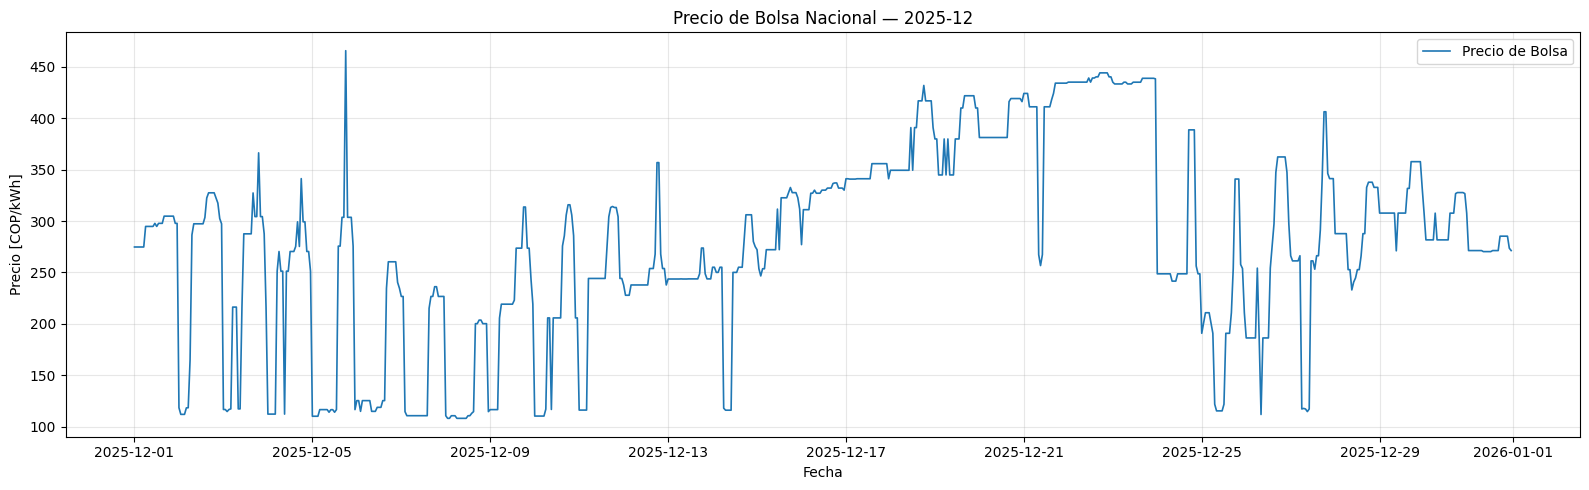


Estadísticos del Precio de Bolsa:


,count,mean,std,min,25%,50%,75%,max
precio_bolsa,744.0,278.47,94.67,108.18,236.19,276.45,341.15,465.65


In [19]:

# ============================================================
# 7.1 PRECIO DE BOLSA — MES DE ANÁLISIS
# ============================================================

mask_mes = (
    (df.index.year == ANIO_GRAFICA)
    &
    (df.index.month == MES_GRAFICA)
)

df_mes = df.loc[mask_mes].copy()

print(
    f"Periodo gráfico: "
    f"{ANIO_GRAFICA}-{MES_GRAFICA:02d}"
)

print(
    "Registros:",
    len(df_mes)
)

if df_mes.empty:

    print(
        f"No hay datos disponibles para "
        f"{ANIO_GRAFICA}-{MES_GRAFICA:02d}"
    )

else:

    # --------------------------------------------------------
    # GRÁFICA DEL PRECIO
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(16,5)
    )

    ax.plot(
        df_mes.index,
        df_mes["precio_bolsa"],
        linewidth=1.2,
        label="Precio de Bolsa"
    )

    ax.set_title(
        f"Precio de Bolsa Nacional — "
        f"{ANIO_GRAFICA}-{MES_GRAFICA:02d}"
    )

    ax.set_xlabel(
        "Fecha"
    )

    ax.set_ylabel(
        "Precio [COP/kWh]"
    )

    ax.legend()

    ax.grid(
        alpha=0.30
    )

    plt.tight_layout()
    plt.show()


    # --------------------------------------------------------
    # ESTADÍSTICOS
    # --------------------------------------------------------

    print(
        "\nEstadísticos del Precio de Bolsa:"
    )

    display(
        df_mes[
            ["precio_bolsa"]
        ]
        .describe()
        .T
        .round(2)
    )

Variables incluidas en la gráfica:
 - precio_bolsa
 - demanda_sin
 - gen_hidraulica_diaria
 - gen_termica_diaria
 - gen_solar_diaria
 - gen_eolica_diaria
 - generacion_total_diaria
 - volumen_util
 - aportes_hidricos


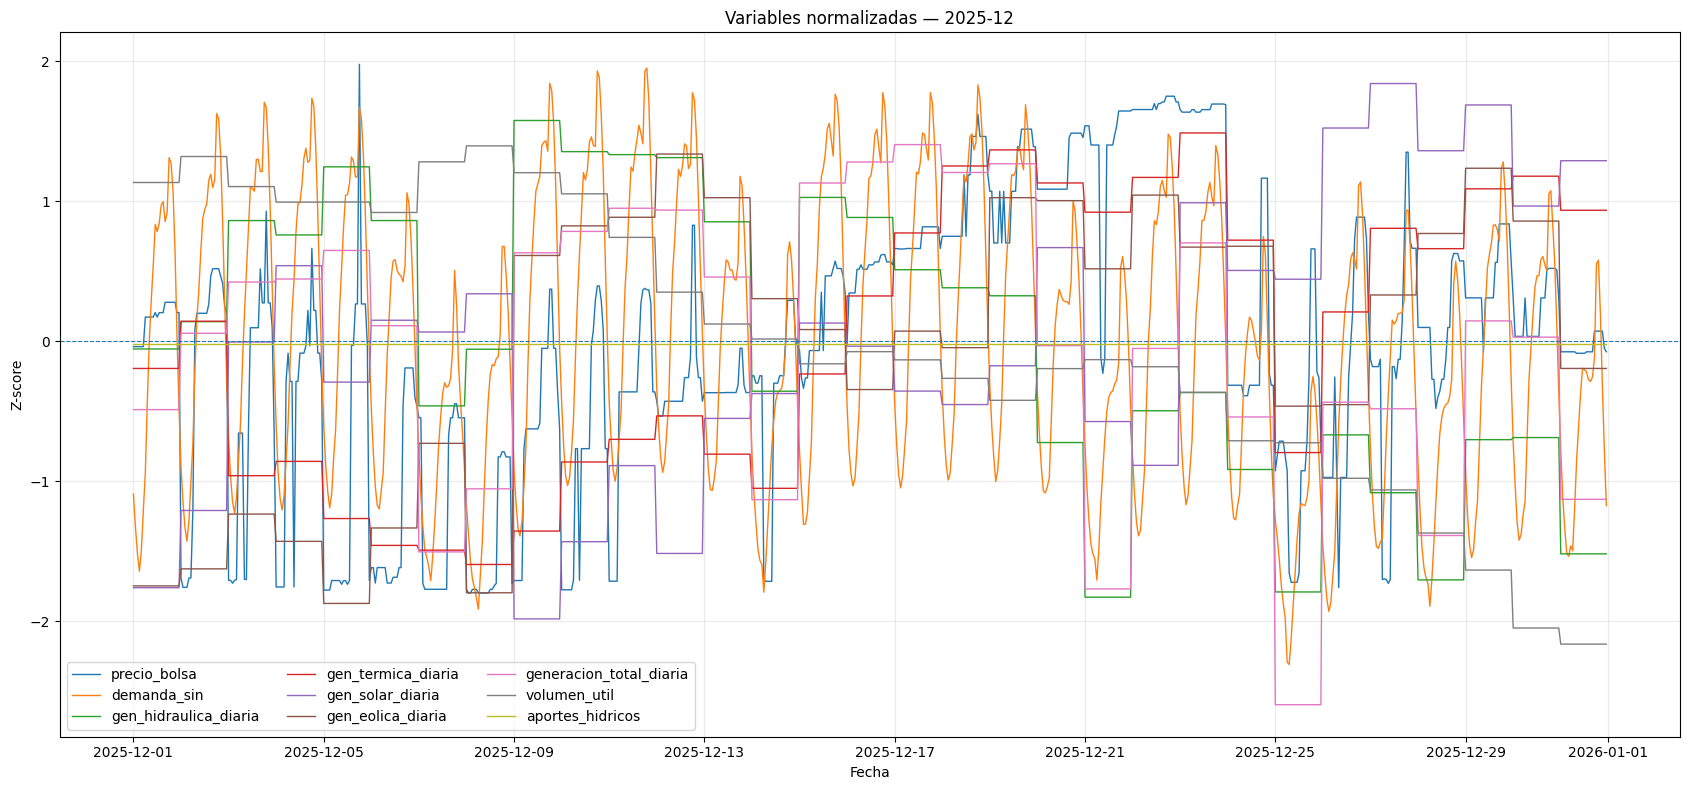

In [20]:

# ============================================================
# 7.2 VARIABLES NORMALIZADAS — Z-SCORE
# ============================================================

if not df_mes.empty:

    variables_grafica = [
        c for c in [

            "precio_bolsa",

            "demanda_sin",

            "gen_hidraulica_diaria",
            "gen_termica_diaria",
            "gen_solar_diaria",
            "gen_eolica_diaria",

            "generacion_total_diaria",

            "volumen_util",
            "aportes_hidricos"

        ]
        if c in df_mes.columns
    ]


    print(
        "Variables incluidas en la gráfica:"
    )

    for c in variables_grafica:
        print(" -", c)


    z = (
        df_mes[
            variables_grafica
        ]
        .copy()
    )


    # --------------------------------------------------------
    # NORMALIZACIÓN Z-SCORE
    #
    # z = (x - media) / desviación estándar
    # --------------------------------------------------------

    medias = z.mean()
    desviaciones = z.std(
        ddof=0
    )

    # Evitar división por cero
    desviaciones = (
        desviaciones
        .replace(
            0,
            np.nan
        )
    )

    z = (
        z - medias
    ) / desviaciones


    # --------------------------------------------------------
    # GRÁFICA
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(17,8)
    )

    for c in z.columns:

        ax.plot(
            z.index,
            z[c],
            label=c,
            linewidth=1
        )


    ax.axhline(
        0,
        linewidth=0.8,
        linestyle="--"
    )


    ax.set_title(
        f"Variables normalizadas — "
        f"{ANIO_GRAFICA}-{MES_GRAFICA:02d}"
    )

    ax.set_xlabel(
        "Fecha"
    )

    ax.set_ylabel(
        "Z-score"
    )

    ax.legend(
        ncol=3
    )

    ax.grid(
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()


CORRELACIÓN CON EL PRECIO DE BOLSA


,Correlación con precio
precio_bolsa,1.0000
gen_termica_diaria,0.7219
demanda_sin,0.1995
gen_otra_diaria,0.1669
generacion_total_diaria,0.0201
aportes_hidricos,-0.1195
gen_solar_diaria,-0.2430
gen_eolica_diaria,-0.2476
volumen_util,-0.4253
gen_hidraulica_diaria,-0.6596


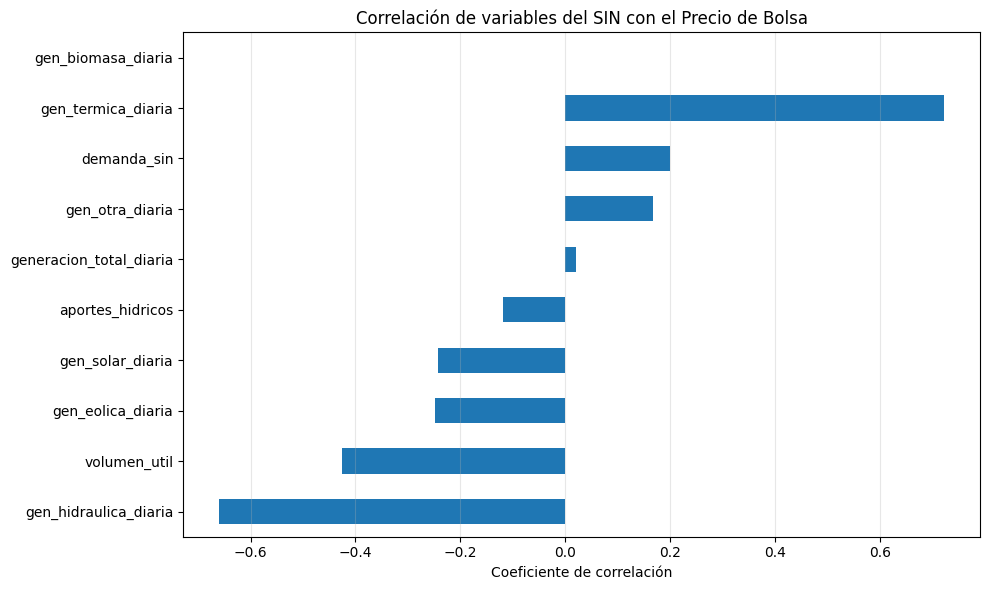

In [21]:
# ============================================================
# 7.3 CORRELACIÓN EXPLORATORIA CON PRECIO DE BOLSA
# ============================================================

variables_correlacion = [
    c for c in [

        "precio_bolsa",

        "demanda_sin",

        "gen_hidraulica_diaria",
        "gen_termica_diaria",
        "gen_solar_diaria",
        "gen_eolica_diaria",
        "gen_biomasa_diaria",
        "gen_otra_diaria",

        "generacion_total_diaria",

        "volumen_util",
        "aportes_hidricos"

    ]
    if c in df.columns
]


df_corr = (
    df[
        variables_correlacion
    ]
    .dropna()
    .copy()
)


correlaciones = (
    df_corr
    .corr()[
        "precio_bolsa"
    ]
    .sort_values(
        ascending=False
    )
)


print(
    "========================================"
)

print(
    "CORRELACIÓN CON EL PRECIO DE BOLSA"
)

print(
    "========================================"
)


display(
    correlaciones
    .to_frame(
        "Correlación con precio"
    )
    .round(4)
)


# ------------------------------------------------------------
# GRÁFICA
# ------------------------------------------------------------

corr_plot = (
    correlaciones
    .drop(
        "precio_bolsa"
    )
    .sort_values()
)

fig, ax = plt.subplots(
    figsize=(10,6)
)

corr_plot.plot(
    kind="barh",
    ax=ax
)

ax.set_title(
    "Correlación de variables del SIN "
    "con el Precio de Bolsa"
)

ax.set_xlabel(
    "Coeficiente de correlación"
)

ax.grid(
    axis="x",
    alpha=0.30
)

plt.tight_layout()
plt.show()


## 8. Feature Engineering — baseline y multivariable

Se mantiene la estructura que ya teníamos:

### Baseline
Precio histórico + calendario.

### Multivariable
Baseline + variables del SIN.

Para que el pronóstico de 24 h sea operativamente válido, las exógenas se incorporan mediante valores **rezagados** (`lag_24` y `lag_168`), en lugar de usar el valor real de la misma hora futura.

Así seguimos usando:

- demanda;
- generación hidráulica;
- generación térmica;
- generación solar;
- generación eólica;
- generación total;
- volumen útil;
- aportes hídricos;

sin introducir fuga de información.


In [22]:

# ============================================================
# 8.1 FEATURE ENGINEERING — PRECIO DE BOLSA
# ============================================================

data = df.copy()


# ------------------------------------------------------------
# 1. LAGS DEL PRECIO
# ------------------------------------------------------------

PRICE_LAGS = [
    1,
    2,
    3,
    6,
    12,
    24,
    48,
    72,
    168,
    336
]

for lag in PRICE_LAGS:

    data[
        f"precio_lag_{lag}"
    ] = (
        data["precio_bolsa"]
        .shift(lag)
    )


# ------------------------------------------------------------
# 2. ESTADÍSTICOS MÓVILES DEL PRECIO
#
# IMPORTANTE:
# shift(1) evita utilizar el precio actual para calcular
# estadísticas usadas para pronosticar ese mismo instante.
# ------------------------------------------------------------

precio_previo = (
    data["precio_bolsa"]
    .shift(1)
)

ROLLING_WINDOWS = [
    6,
    24,
    72,
    168
]


for ventana in ROLLING_WINDOWS:

    data[
        f"precio_mean_{ventana}"
    ] = (
        precio_previo
        .rolling(
            window=ventana,
            min_periods=ventana
        )
        .mean()
    )

    data[
        f"precio_std_{ventana}"
    ] = (
        precio_previo
        .rolling(
            window=ventana,
            min_periods=ventana
        )
        .std()
    )

    data[
        f"precio_min_{ventana}"
    ] = (
        precio_previo
        .rolling(
            window=ventana,
            min_periods=ventana
        )
        .min()
    )

    data[
        f"precio_max_{ventana}"
    ] = (
        precio_previo
        .rolling(
            window=ventana,
            min_periods=ventana
        )
        .max()
    )


# ------------------------------------------------------------
# 3. CAMBIOS DEL PRECIO
# ------------------------------------------------------------

data["precio_diff_1"] = (
    data["precio_bolsa"]
    .shift(1)
    -
    data["precio_bolsa"]
    .shift(2)
)

data["precio_diff_24"] = (
    data["precio_bolsa"]
    .shift(1)
    -
    data["precio_bolsa"]
    .shift(25)
)


# ------------------------------------------------------------
# 4. VARIABLES TEMPORALES
# ------------------------------------------------------------

data["hora"] = (
    data.index.hour
)

data["dia_semana"] = (
    data.index.dayofweek
)

data["mes"] = (
    data.index.month
)

data["dia_ano"] = (
    data.index.dayofyear
)

data["es_fin_semana"] = (
    data["dia_semana"] >= 5
).astype(int)


# ------------------------------------------------------------
# CODIFICACIÓN CÍCLICA
# ------------------------------------------------------------

data["hora_sin"] = np.sin(
    2 * np.pi
    * data["hora"]
    / 24
)

data["hora_cos"] = np.cos(
    2 * np.pi
    * data["hora"]
    / 24
)


data["dow_sin"] = np.sin(
    2 * np.pi
    * data["dia_semana"]
    / 7
)

data["dow_cos"] = np.cos(
    2 * np.pi
    * data["dia_semana"]
    / 7
)


data["mes_sin"] = np.sin(
    2 * np.pi
    * (data["mes"] - 1)
    / 12
)

data["mes_cos"] = np.cos(
    2 * np.pi
    * (data["mes"] - 1)
    / 12
)


data["doy_sin"] = np.sin(
    2 * np.pi
    * data["dia_ano"]
    / 365.25
)

data["doy_cos"] = np.cos(
    2 * np.pi
    * data["dia_ano"]
    / 365.25
)

In [23]:
# ============================================================
# 8.2 VARIABLES EXÓGENAS DEL SIN
# ============================================================

variables_exogenas_raw = [
    c for c in [

        # Demanda
        "demanda_sin",

        # Generación diaria por tecnología
        "gen_hidraulica_diaria",
        "gen_termica_diaria",
        "gen_solar_diaria",
        "gen_eolica_diaria",
        "gen_biomasa_diaria",
        "gen_otra_diaria",

        # Generación agregada
        "generacion_total_diaria",

        # Hidrología
        "volumen_util",
        "aportes_hidricos"

    ]
    if c in data.columns
]


print(
    "Variables exógenas disponibles:"
)

for c in variables_exogenas_raw:
    print(" -", c)


# ------------------------------------------------------------
# LAGS DE VARIABLES EXÓGENAS
#
# 24 h  = condición del día anterior
# 168 h = condición de una semana atrás
#
# De esta manera NO usamos información futura.
# ------------------------------------------------------------

EXOG_LAGS = [
    24,
    168
]

features_exogenas = []


for variable in variables_exogenas_raw:

    for lag in EXOG_LAGS:

        nombre = (
            f"{variable}_lag_{lag}"
        )

        data[nombre] = (
            data[variable]
            .shift(lag)
        )

        features_exogenas.append(
            nombre
        )


print(
    "\nNúmero de features exógenas:",
    len(features_exogenas)
)

print(
    "\nFeatures exógenas generadas:"
)

for c in features_exogenas:
    print(" -", c)

Variables exógenas disponibles:
 - demanda_sin
 - gen_hidraulica_diaria
 - gen_termica_diaria
 - gen_solar_diaria
 - gen_eolica_diaria
 - gen_biomasa_diaria
 - gen_otra_diaria
 - generacion_total_diaria
 - volumen_util
 - aportes_hidricos

Número de features exógenas: 20

Features exógenas generadas:
 - demanda_sin_lag_24
 - demanda_sin_lag_168
 - gen_hidraulica_diaria_lag_24
 - gen_hidraulica_diaria_lag_168
 - gen_termica_diaria_lag_24
 - gen_termica_diaria_lag_168
 - gen_solar_diaria_lag_24
 - gen_solar_diaria_lag_168
 - gen_eolica_diaria_lag_24
 - gen_eolica_diaria_lag_168
 - gen_biomasa_diaria_lag_24
 - gen_biomasa_diaria_lag_168
 - gen_otra_diaria_lag_24
 - gen_otra_diaria_lag_168
 - generacion_total_diaria_lag_24
 - generacion_total_diaria_lag_168
 - volumen_util_lag_24
 - volumen_util_lag_168
 - aportes_hidricos_lag_24
 - aportes_hidricos_lag_168


In [24]:
# ============================================================
# 8.3 DEFINICIÓN DE FEATURES
# ============================================================

# ------------------------------------------------------------
# BASELINE
# Precio histórico + variables temporales
# ------------------------------------------------------------

features_base = (

    [
        f"precio_lag_{lag}"
        for lag in PRICE_LAGS
    ]

    +

    [
        f"precio_mean_{w}"
        for w in ROLLING_WINDOWS
    ]

    +

    [
        f"precio_std_{w}"
        for w in ROLLING_WINDOWS
    ]

    +

    [
        f"precio_min_{w}"
        for w in ROLLING_WINDOWS
    ]

    +

    [
        f"precio_max_{w}"
        for w in ROLLING_WINDOWS
    ]

    +

    [
        "precio_diff_1",
        "precio_diff_24"
    ]

    +

    [
        "hora_sin",
        "hora_cos",

        "dow_sin",
        "dow_cos",

        "mes_sin",
        "mes_cos",

        "doy_sin",
        "doy_cos",

        "es_fin_semana"
    ]
)


# ------------------------------------------------------------
# MULTIVARIABLE
# Baseline + variables del SIN
# ------------------------------------------------------------

features_multi = (
    features_base
    +
    features_exogenas
)


print(
    "========================================"
)

print(
    "CONFIGURACIÓN DE MODELOS"
)

print(
    "========================================"
)

print(
    "\nFeatures baseline:",
    len(features_base)
)

print(
    "Features multivariable:",
    len(features_multi)
)

print(
    "\nVariables adicionales del SIN:",
    len(features_exogenas)
)

CONFIGURACIÓN DE MODELOS

Features baseline: 37
Features multivariable: 57

Variables adicionales del SIN: 20


In [25]:
# ============================================================
# 8.4 DATASET FINAL PARA MACHINE LEARNING
# ============================================================

columnas_modelo = (
    ["precio_bolsa"]
    +
    features_multi
)


model_data = (
    data[
        columnas_modelo
    ]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .dropna()
    .copy()
)


print(
    "========================================"
)

print(
    "DATASET FINAL PARA ML"
)

print(
    "========================================"
)


print(
    "Inicio:",
    model_data.index.min()
)

print(
    "Fin:",
    model_data.index.max()
)

print(
    "Filas:",
    len(model_data)
)

print(
    "Número total de features:",
    len(features_multi)
)


print(
    "\nValores faltantes finales:"
)

print(
    model_data.isna()
    .sum()
    .sum()
)


display(
    model_data.head()
)

DATASET FINAL PARA ML
Inicio: 2024-01-15 00:00:00
Fin: 2025-12-31 23:00:00
Filas: 17208
Número total de features: 57

Valores faltantes finales:
0


,precio_bolsa,precio_lag_1,precio_lag_2,precio_lag_3,precio_lag_6,precio_lag_12,precio_lag_24,precio_lag_48,precio_lag_72,precio_lag_168,precio_lag_336,precio_mean_6,precio_mean_24,precio_mean_72,precio_mean_168,precio_std_6,precio_std_24,precio_std_72,precio_std_168,precio_min_6,precio_min_24,precio_min_72,precio_min_168,precio_max_6,precio_max_24,precio_max_72,precio_max_168,precio_diff_1,precio_diff_24,hora_sin,hora_cos,dow_sin,dow_cos,mes_sin,mes_cos,doy_sin,doy_cos,es_fin_semana,demanda_sin_lag_24,demanda_sin_lag_168,gen_hidraulica_diaria_lag_24,gen_hidraulica_diaria_lag_168,gen_termica_diaria_lag_24,gen_termica_diaria_lag_168,gen_solar_diaria_lag_24,gen_solar_diaria_lag_168,gen_eolica_diaria_lag_24,gen_eolica_diaria_lag_168,gen_biomasa_diaria_lag_24,gen_biomasa_diaria_lag_168,gen_otra_diaria_lag_24,gen_otra_diaria_lag_168,generacion_total_diaria_lag_24,generacion_total_diaria_lag_168,volumen_util_lag_24,volumen_util_lag_168,aportes_hidricos_lag_24,aportes_hidricos_lag_168
datetime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2024-01-15 00:00:00,603.444,619.2323,638.2323,638.2323,638.2323,613.2323,619.2323,646.031,674.0267,649.1596,251.9116,635.065633,613.164300,641.527667,657.437705,7.756718,23.463646,33.159901,38.247017,619.2323,519.2323,519.2323,519.2323,638.2323,638.2323,686.0267,721.1567,-19.0000,-27.7987,0.000000,1.000000,0.0,1.0,0.0,1.0,0.255182,0.966893,0,93062.310227,88365.284205,104613909.3,1.287022e+08,95471430.26,60768334.01,7445066.54,7868787.46,505029.56,706037.28,0.0,0.0,3302819.13,2502433.74,2.113383e+08,2.005478e+08,5.156653e+08,5.288667e+08,6.253778e+06,6.253778e+06
2024-01-15 01:00:00,580.702,603.4440,619.2323,638.2323,638.2323,613.2323,613.2323,618.031,649.0267,649.1596,251.9116,629.267583,612.506454,640.547351,657.165588,14.758245,23.507407,33.228847,38.468253,603.4440,519.2323,519.2323,519.2323,638.2323,638.2323,686.0267,721.1567,-15.7883,-15.7883,0.258819,0.965926,0.0,1.0,0.0,1.0,0.255182,0.966893,0,89176.153864,85186.037500,104613909.3,1.287022e+08,95471430.26,60768334.01,7445066.54,7868787.46,505029.56,706037.28,0.0,0.0,3302819.13,2502433.74,2.113383e+08,2.005478e+08,5.156653e+08,5.288667e+08,6.253778e+06,6.253778e+06
2024-01-15 02:00:00,500.702,580.7020,603.4440,619.2323,638.2323,613.2323,613.2323,607.063,629.3947,625.3756,251.9116,619.679200,611.151025,639.598397,656.758102,23.730386,24.385190,33.951047,38.913567,580.7020,519.2323,519.2323,519.2323,638.2323,638.2323,686.0267,721.1567,-22.7420,-32.5303,0.500000,0.866025,0.0,1.0,0.0,1.0,0.255182,0.966893,0,86448.337386,82907.628636,104613909.3,1.287022e+08,95471430.26,60768334.01,7445066.54,7868787.46,505029.56,706037.28,0.0,0.0,3302819.13,2502433.74,2.113383e+08,2.005478e+08,5.156653e+08,5.288667e+08,6.253778e+06,6.253778e+06
2024-01-15 03:00:00,449.491,500.7020,580.7020,603.4440,638.2323,613.2323,607.9433,607.063,597.9267,579.1596,281.9116,596.757483,606.462263,637.810999,656.015998,51.912585,33.194873,37.678756,40.665018,500.7020,500.7020,500.7020,500.7020,638.2323,638.2323,686.0267,721.1567,-80.0000,-112.5303,0.707107,0.707107,0.0,1.0,0.0,1.0,0.255182,0.966893,0,84277.383977,81117.789205,104613909.3,1.287022e+08,95471430.26,60768334.01,7445066.54,7868787.46,505029.56,706037.28,0.0,0.0,3302819.13,2502433.74,2.113383e+08,2.005478e+08,5.156653e+08,5.288667e+08,6.253778e+06,6.253778e+06
2024-01-15 04:00:00,533.310,449.4910,500.7020,580.7020,638.2323,619.2323,607.9433,607.063,597.9267,579.1596,281.9116,565.300600,599.860083,635.749392,655.244161,74.168222,46.126171,43.502556,43.279075,449.4910,449.4910,449.4910,449.4910,638.2323,638.2323,686.0267,721.1567,-51.2110,-158.4523,0.866025,0.500000,0.0,1.0,0.0,1.0,0.255182,0.966893,0,83321.432841,80559.377273,104613909.3,1.287022e+08,95471430.26,60768334.01,7445066.54,7868787.46,505029.56,706037.28,0.0,0.0,3302819.13,2502433.74,2.113383e+08,2.005478e+08,5.156653e+08,5.288667e+08,6.253778e+06,6.253778e+06


In [26]:
# ============================================================
# 8.5 AUDITORÍA DE VARIABLES
# ============================================================

print(
    "========================================"
)

print(
    "AUDITORÍA DEL MODELO MULTIVARIABLE"
)

print(
    "========================================"
)


print(
    "\nVariable objetivo:"
)

print(
    "precio_bolsa"
)


print(
    "\nVariables históricas del precio:"
)

for c in features_base:
    print(" -", c)


print(
    "\nVariables exógenas rezagadas:"
)

for c in features_exogenas:
    print(" -", c)


# Comprobar que ninguna variable exógena
# contemporánea entre directamente al modelo

leakage_exog = [
    c for c in variables_exogenas_raw
    if c in features_multi
]


print(
    "\nExógenas contemporáneas presentes:",
    leakage_exog
)


if len(leakage_exog) == 0:

    print(
        "\nOK:"
        " no se utilizan variables exógenas "
        "del mismo instante."
    )

else:

    print(
        "\nADVERTENCIA:"
        " revisar posible fuga de información."
    )

AUDITORÍA DEL MODELO MULTIVARIABLE

Variable objetivo:
precio_bolsa

Variables históricas del precio:
 - precio_lag_1
 - precio_lag_2
 - precio_lag_3
 - precio_lag_6
 - precio_lag_12
 - precio_lag_24
 - precio_lag_48
 - precio_lag_72
 - precio_lag_168
 - precio_lag_336
 - precio_mean_6
 - precio_mean_24
 - precio_mean_72
 - precio_mean_168
 - precio_std_6
 - precio_std_24
 - precio_std_72
 - precio_std_168
 - precio_min_6
 - precio_min_24
 - precio_min_72
 - precio_min_168
 - precio_max_6
 - precio_max_24
 - precio_max_72
 - precio_max_168
 - precio_diff_1
 - precio_diff_24
 - hora_sin
 - hora_cos
 - dow_sin
 - dow_cos
 - mes_sin
 - mes_cos
 - doy_sin
 - doy_cos
 - es_fin_semana

Variables exógenas rezagadas:
 - demanda_sin_lag_24
 - demanda_sin_lag_168
 - gen_hidraulica_diaria_lag_24
 - gen_hidraulica_diaria_lag_168
 - gen_termica_diaria_lag_24
 - gen_termica_diaria_lag_168
 - gen_solar_diaria_lag_24
 - gen_solar_diaria_lag_168
 - gen_eolica_diaria_lag_24
 - gen_eolica_diaria_lag_168


## 9. División cronológica 70 / 15 / 15

In [27]:

# ============================================================
# 9.1 DIVISIÓN CRONOLÓGICA
# TRAIN / VALIDATION / TEST
# ============================================================

n_total = len(model_data)

i_train = int(
    n_total * 0.70
)

i_validation = int(
    n_total * 0.85
)


# ------------------------------------------------------------
# DIVISIÓN CRONOLÓGICA
# NO SE UTILIZA SHUFFLE
# ------------------------------------------------------------

train = (
    model_data
    .iloc[
        :i_train
    ]
    .copy()
)

val = (
    model_data
    .iloc[
        i_train:i_validation
    ]
    .copy()
)

test = (
    model_data
    .iloc[
        i_validation:
    ]
    .copy()
)


print(
    "=" * 70
)

print(
    "DIVISIÓN TEMPORAL DEL DATASET"
)

print(
    "=" * 70
)


print(
    "\nTOTAL:"
)

print(
    f"{len(model_data):,} registros"
)


print(
    "\nTRAIN:"
)

print(
    f"{len(train):,} registros"
)

print(
    train.index.min(),
    "->",
    train.index.max()
)


print(
    "\nVALIDATION:"
)

print(
    f"{len(val):,} registros"
)

print(
    val.index.min(),
    "->",
    val.index.max()
)


print(
    "\nTEST:"
)

print(
    f"{len(test):,} registros"
)

print(
    test.index.min(),
    "->",
    test.index.max()
)

DIVISIÓN TEMPORAL DEL DATASET

TOTAL:
17,208 registros

TRAIN:
12,045 registros
2024-01-15 00:00:00 -> 2025-05-30 20:00:00

VALIDATION:
2,581 registros
2025-05-30 21:00:00 -> 2025-09-15 09:00:00

TEST:
2,582 registros
2025-09-15 10:00:00 -> 2025-12-31 23:00:00


In [28]:
# ============================================================
# 9.2 VARIABLES X / OBJETIVO y
# ============================================================

TARGET = "precio_bolsa"


# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

X_train = (
    train[
        features_multi
    ]
    .copy()
)

y_train = (
    train[
        TARGET
    ]
    .copy()
)


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

X_val = (
    val[
        features_multi
    ]
    .copy()
)

y_val = (
    val[
        TARGET
    ]
    .copy()
)


# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

X_test = (
    test[
        features_multi
    ]
    .copy()
)

y_test = (
    test[
        TARGET
    ]
    .copy()
)


print(
    "========================================"
)

print(
    "DIMENSIONES"
)

print(
    "========================================"
)


print(
    "X_train:",
    X_train.shape
)

print(
    "y_train:",
    y_train.shape
)


print(
    "\nX_val:",
    X_val.shape
)

print(
    "y_val:",
    y_val.shape
)


print(
    "\nX_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)


print(
    "\nNúmero de variables del modelo:",
    len(features_multi)
)

DIMENSIONES
X_train: (12045, 57)
y_train: (12045,)

X_val: (2581, 57)
y_val: (2581,)

X_test: (2582, 57)
y_test: (2582,)

Número de variables del modelo: 57


In [29]:
# ============================================================
# 9.3 AUDITORÍA TEMPORAL
# ============================================================

print(
    "=" * 70
)

print(
    "AUDITORÍA TEMPORAL"
)

print(
    "=" * 70
)


print(
    "\nÚltimo registro TRAIN:"
)

print(
    train.index.max()
)


print(
    "\nPrimer registro VALIDATION:"
)

print(
    val.index.min()
)


print(
    "\nÚltimo registro VALIDATION:"
)

print(
    val.index.max()
)


print(
    "\nPrimer registro TEST:"
)

print(
    test.index.min()
)


# ------------------------------------------------------------
# COMPROBACIONES
# ------------------------------------------------------------

assert (
    train.index.max()
    <
    val.index.min()
)

assert (
    val.index.max()
    <
    test.index.min()
)


print(
    "\nOK: no existe solapamiento temporal."
)

print(
    "TRAIN < VALIDATION < TEST"
)

AUDITORÍA TEMPORAL

Último registro TRAIN:
2025-05-30 20:00:00

Primer registro VALIDATION:
2025-05-30 21:00:00

Último registro VALIDATION:
2025-09-15 09:00:00

Primer registro TEST:
2025-09-15 10:00:00

OK: no existe solapamiento temporal.
TRAIN < VALIDATION < TEST


In [30]:
# ============================================================
# 9.4 DISTRIBUCIÓN DEL PRECIO POR CONJUNTO
# ============================================================

estadisticos_split = pd.DataFrame({

    "TRAIN":
        y_train.describe(),

    "VALIDATION":
        y_val.describe(),

    "TEST":
        y_test.describe()

})


print(
    "Precio de Bolsa [COP/kWh]"
)

display(
    estadisticos_split.round(2)
)

Precio de Bolsa [COP/kWh]


,TRAIN,VALIDATION,TEST
count,12045.00,2581.00,2582.00
mean,563.00,172.57,240.90
std,454.46,147.71,142.31
min,96.36,99.61,97.89
25%,211.16,107.22,116.60
50%,505.11,111.81,233.25
75%,728.68,186.44,287.77
max,2675.65,2224.01,1229.18


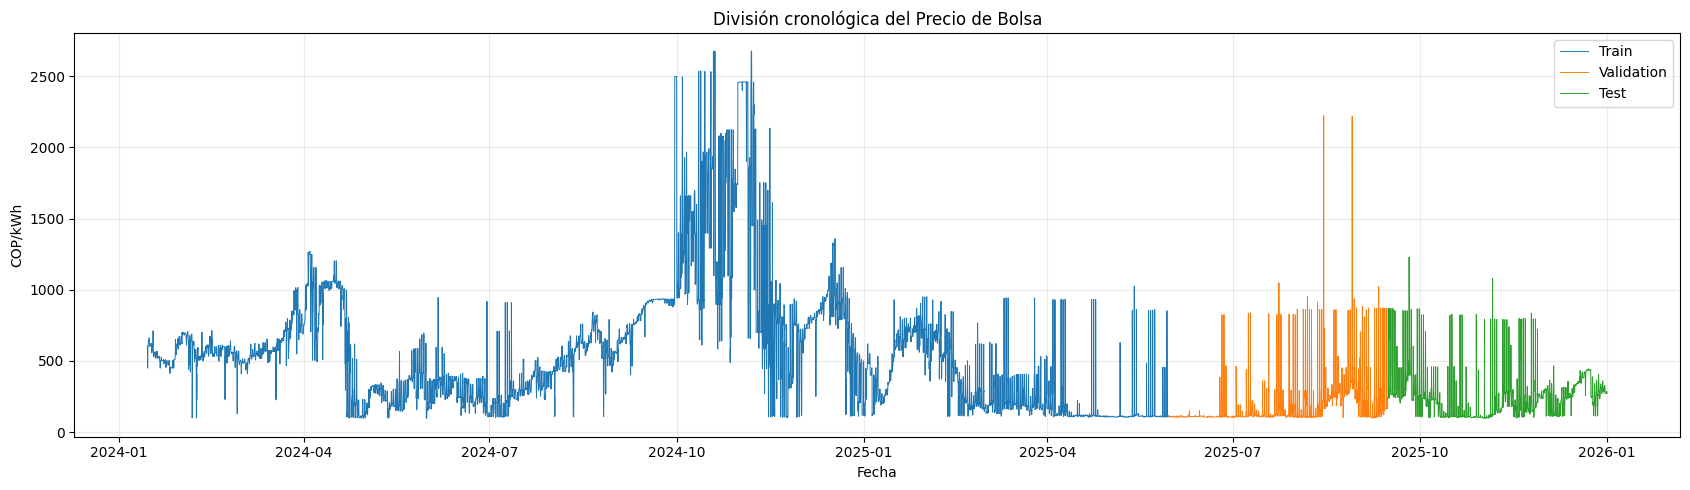

In [31]:
# ============================================================
# 9.5 DISTRIBUCIÓN TEMPORAL DEL SPLIT
# ============================================================

fig, ax = plt.subplots(
    figsize=(17,5)
)


ax.plot(
    train.index,
    y_train,
    label="Train",
    linewidth=.7
)


ax.plot(
    val.index,
    y_val,
    label="Validation",
    linewidth=.7
)


ax.plot(
    test.index,
    y_test,
    label="Test",
    linewidth=.7
)


ax.set_title(
    "División cronológica del Precio de Bolsa"
)

ax.set_ylabel(
    "COP/kWh"
)

ax.set_xlabel(
    "Fecha"
)

ax.legend()

ax.grid(
    alpha=.25
)


plt.tight_layout()
plt.show()


## 10. Comparación de modelos de Machine Learning

Esta sección se restaura como estaba originalmente:

- SVR
- Random Forest
- Gradient Boosting
- XGBoost

Todos reciben exactamente el mismo conjunto multivariable.


In [32]:

# ============================================================
# 10.1 FUNCIÓN DE EVALUACIÓN
# ============================================================

def evaluar_modelo(
    nombre,
    y_real,
    y_pred
):

    y_real = np.asarray(
        y_real,
        dtype=float
    )

    y_pred = np.asarray(
        y_pred,
        dtype=float
    )

    # --------------------------------------------------------
    # MAE
    # --------------------------------------------------------

    mae = mean_absolute_error(
        y_real,
        y_pred
    )

    # --------------------------------------------------------
    # MSE
    # --------------------------------------------------------

    mse = mean_squared_error(
        y_real,
        y_pred
    )

    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------

    rmse = np.sqrt(
        mse
    )

    # --------------------------------------------------------
    # R²
    # --------------------------------------------------------

    r2 = r2_score(
        y_real,
        y_pred
    )

    # --------------------------------------------------------
    # MAPE
    #
    # Evitamos división por cero.
    # --------------------------------------------------------

    mask = (
        np.abs(y_real) > 1e-6
    )

    if mask.sum() > 0:

        mape = (
            np.mean(
                np.abs(
                    (
                        y_real[mask]
                        -
                        y_pred[mask]
                    )
                    /
                    y_real[mask]
                )
            )
            * 100
        )

    else:

        mape = np.nan


    # --------------------------------------------------------
    # NRMSE
    # --------------------------------------------------------

    media_precio = np.mean(
        np.abs(y_real)
    )

    nrmse = (
        rmse
        /
        media_precio
        * 100
        if media_precio > 0
        else np.nan
    )


    return {

        "Modelo": nombre,

        "MAE": mae,

        "MSE": mse,

        "RMSE": rmse,

        "R2": r2,

        "MAPE (%)": mape,

        "NRMSE (%)": nrmse

    }


In [33]:
# ============================================================
# 10.2 ESCALAMIENTO PARA SVR
# ============================================================

scaler_svr = StandardScaler()


X_train_svr = scaler_svr.fit_transform(
    X_train
)

X_val_svr = scaler_svr.transform(
    X_val
)

X_test_svr = scaler_svr.transform(
    X_test
)


print(
    "Dimensiones SVR:"
)

print(
    "Train:",
    X_train_svr.shape
)

print(
    "Validation:",
    X_val_svr.shape
)

print(
    "Test:",
    X_test_svr.shape
)

Dimensiones SVR:
Train: (12045, 57)
Validation: (2581, 57)
Test: (2582, 57)


In [34]:
# ============================================================
# 10.3 ENTRENAMIENTO DE MODELOS
# ============================================================

import time


resultados_tiempo = {}


# ============================================================
# 1. SVR
# ============================================================

print(
    "Entrenando SVR..."
)

inicio = time.time()


svr_model = SVR(

    kernel="rbf",

    C=100,

    epsilon=0.1,

    gamma="scale"
)


svr_model.fit(

    X_train_svr,

    y_train

)


pred_val_svr = svr_model.predict(

    X_val_svr

)


resultados_tiempo[
    "SVR"
] = (
    time.time()
    -
    inicio
)


print(
    f"SVR terminado: "
    f"{resultados_tiempo['SVR']:.1f} s"
)



# ============================================================
# 2. RANDOM FOREST
# ============================================================

print(
    "\nEntrenando Random Forest..."
)

inicio = time.time()


rf_model = RandomForestRegressor(

    n_estimators=300,

    max_depth=None,

    min_samples_split=2,

    min_samples_leaf=2,

    max_features=1.0,

    bootstrap=True,

    random_state=RANDOM_STATE,

    n_jobs=-1

)


rf_model.fit(

    X_train,

    y_train

)


pred_val_rf = rf_model.predict(

    X_val

)


resultados_tiempo[
    "Random Forest"
] = (
    time.time()
    -
    inicio
)


print(
    f"Random Forest terminado: "
    f"{resultados_tiempo['Random Forest']:.1f} s"
)



# ============================================================
# 3. GRADIENT BOOSTING
# ============================================================

print(
    "\nEntrenando Gradient Boosting..."
)

inicio = time.time()


gbm_model = GradientBoostingRegressor(

    n_estimators=300,

    learning_rate=0.05,

    max_depth=4,

    min_samples_split=2,

    min_samples_leaf=2,

    random_state=RANDOM_STATE

)


gbm_model.fit(

    X_train,

    y_train

)


pred_val_gbm = gbm_model.predict(

    X_val

)


resultados_tiempo[
    "Gradient Boosting"
] = (
    time.time()
    -
    inicio
)


print(
    f"Gradient Boosting terminado: "
    f"{resultados_tiempo['Gradient Boosting']:.1f} s"
)



# ============================================================
# 4. XGBOOST
# ============================================================

print(
    "\nEntrenando XGBoost..."
)

inicio = time.time()


xgb_model = XGBRegressor(

    n_estimators=500,

    learning_rate=0.04,

    max_depth=6,

    min_child_weight=1,

    subsample=0.85,

    colsample_bytree=0.85,

    objective="reg:squarederror",

    random_state=RANDOM_STATE,

    n_jobs=-1

)


xgb_model.fit(

    X_train,

    y_train

)


pred_val_xgb = xgb_model.predict(

    X_val

)


resultados_tiempo[
    "XGBoost"
] = (
    time.time()
    -
    inicio
)


print(
    f"XGBoost terminado: "
    f"{resultados_tiempo['XGBoost']:.1f} s"
)


print(
    "\n========================================"
)

print(
    "ENTRENAMIENTO FINALIZADO"
)

print(
    "========================================"
)

Entrenando SVR...
SVR terminado: 24.2 s

Entrenando Random Forest...
Random Forest terminado: 143.7 s

Entrenando Gradient Boosting...
Gradient Boosting terminado: 68.2 s

Entrenando XGBoost...
XGBoost terminado: 7.1 s

ENTRENAMIENTO FINALIZADO


In [35]:
# ============================================================
# 10.4 COMPARACIÓN DE MODELOS — VALIDATION
# ============================================================

resultados_modelos = pd.DataFrame([

    evaluar_modelo(
        "SVR",
        y_val,
        pred_val_svr
    ),

    evaluar_modelo(
        "Random Forest",
        y_val,
        pred_val_rf
    ),

    evaluar_modelo(
        "Gradient Boosting",
        y_val,
        pred_val_gbm
    ),

    evaluar_modelo(
        "XGBoost",
        y_val,
        pred_val_xgb
    )

])


# ------------------------------------------------------------
# TIEMPO DE ENTRENAMIENTO
# ------------------------------------------------------------

resultados_modelos[
    "Tiempo entrenamiento [s]"
] = (
    resultados_modelos[
        "Modelo"
    ]
    .map(
        resultados_tiempo
    )
)


# ------------------------------------------------------------
# ORDENAR POR RMSE
# ------------------------------------------------------------

resultados_modelos = (

    resultados_modelos

    .sort_values(
        "RMSE"
    )

    .reset_index(
        drop=True
    )
)


display(

    resultados_modelos

    .set_index(
        "Modelo"
    )

    .style.format({

        "MAE": "{:.3f}",

        "MSE": "{:.3f}",

        "RMSE": "{:.3f}",

        "R2": "{:.4f}",

        "MAPE (%)": "{:.2f}",

        "NRMSE (%)": "{:.2f}",

        "Tiempo entrenamiento [s]": "{:.1f}"

    })
)

,MAE,MSE,RMSE,R2,MAPE (%),NRMSE (%),Tiempo entrenamiento [s]
Modelo,,,,,,,
Gradient Boosting,45.851,9238.396,96.117,0.5764,25.81,55.70,68.2
Random Forest,44.380,11571.132,107.569,0.4695,23.51,62.33,143.7
XGBoost,60.815,11911.288,109.139,0.4539,36.03,63.24,7.1
SVR,124.513,22851.602,151.167,-0.0477,85.84,87.60,24.2


In [36]:
# ============================================================
# 10.5 SELECCIÓN DEL MEJOR MODELO
# ============================================================

MEJOR_MODELO = (

    resultados_modelos

    .iloc[0][
        "Modelo"
    ]
)


MEJOR_RMSE = (

    resultados_modelos

    .iloc[0][
        "RMSE"
    ]
)


print(
    "========================================"
)

print(
    "MEJOR MODELO EN VALIDATION"
)

print(
    "========================================"
)


print(
    "\nModelo:",
    MEJOR_MODELO
)

print(
    f"RMSE: {MEJOR_RMSE:.3f} COP/kWh"
)

MEJOR MODELO EN VALIDATION

Modelo: Gradient Boosting
RMSE: 96.117 COP/kWh


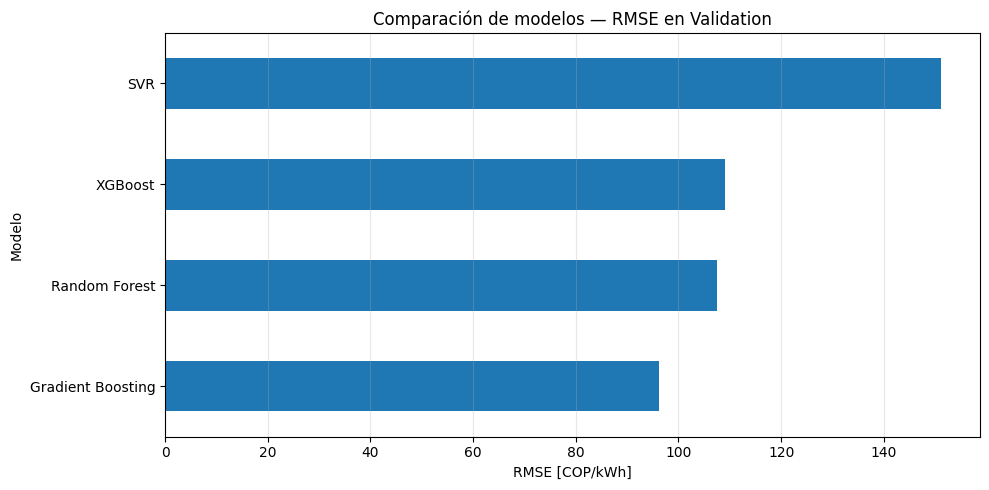

In [37]:
# ============================================================
# 10.6 COMPARACIÓN GRÁFICA — RMSE
# ============================================================

rmse_plot = (

    resultados_modelos

    .set_index(
        "Modelo"
    )[
        "RMSE"
    ]

    .sort_values(
        ascending=True
    )
)


fig, ax = plt.subplots(

    figsize=(10,5)

)


rmse_plot.plot(

    kind="barh",

    ax=ax

)


ax.set_title(

    "Comparación de modelos — RMSE en Validation"

)


ax.set_xlabel(

    "RMSE [COP/kWh]"

)


ax.set_ylabel(

    "Modelo"

)


ax.grid(

    axis="x",

    alpha=0.30

)


plt.tight_layout()

plt.show()

In [38]:
# ============================================================
# 11.1 BASELINE VS MULTIVARIABLE — GRADIENT BOOSTING
# ============================================================

gbm_baseline = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=RANDOM_STATE
)

gbm_baseline.fit(
    train[features_base],
    y_train
)

pred_val_gbm_baseline = gbm_baseline.predict(
    val[features_base]
)


resultado_gbm_baseline = evaluar_modelo(
    "GBM Baseline",
    y_val,
    pred_val_gbm_baseline
)


resultado_gbm_multi = evaluar_modelo(
    "GBM Multivariable",
    y_val,
    pred_val_gbm
)


comparacion_gbm = pd.DataFrame([
    resultado_gbm_baseline,
    resultado_gbm_multi
]).set_index("Modelo")


display(
    comparacion_gbm.style.format({
        "MAE": "{:.3f}",
        "MSE": "{:.3f}",
        "RMSE": "{:.3f}",
        "R2": "{:.4f}",
        "MAPE (%)": "{:.2f}",
        "NRMSE (%)": "{:.2f}"
    })
)


mejora_exogenas = (
    (
        comparacion_gbm.loc[
            "GBM Baseline",
            "RMSE"
        ]
        -
        comparacion_gbm.loc[
            "GBM Multivariable",
            "RMSE"
        ]
    )
    /
    comparacion_gbm.loc[
        "GBM Baseline",
        "RMSE"
    ]
    * 100
)


print(
    f"Mejora del RMSE al añadir variables del SIN: "
    f"{mejora_exogenas:.2f}%"
)

,MAE,MSE,RMSE,R2,MAPE (%),NRMSE (%)
Modelo,,,,,,
GBM Baseline,46.622,9662.944,98.300,0.5570,27.10,56.96
GBM Multivariable,45.851,9238.396,96.117,0.5764,25.81,55.70


Mejora del RMSE al añadir variables del SIN: 2.22%


In [40]:
# ============================================================
# 11.2 TUNING RÁPIDO — GRADIENT BOOSTING
# ============================================================

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.ensemble import GradientBoostingRegressor
import time

print("Iniciando tuning rápido de Gradient Boosting...")

inicio_tuning = time.time()

# Validación temporal más ligera
tscv_gbm = TimeSeriesSplit(
    n_splits=3
)

# Modelo
gbm_tuning = GradientBoostingRegressor(
    random_state=RANDOM_STATE
)

# Espacio concentrado alrededor de la configuración
# que ya está funcionando razonablemente bien
parametros_gbm = {

    "n_estimators": [
        200,
        300,
        400,
        500
    ],

    "learning_rate": [
        0.03,
        0.05,
        0.07
    ],

    "max_depth": [
        3,
        4,
        5
    ],

    "min_samples_split": [
        2,
        5,
        10
    ],

    "min_samples_leaf": [
        1,
        2,
        4,
        6
    ],

    "subsample": [
        0.8,
        0.9,
        1.0
    ],

    "max_features": [
        0.8,
        1.0
    ]
}


search_gbm = RandomizedSearchCV(

    estimator=gbm_tuning,

    param_distributions=parametros_gbm,

    n_iter=12,

    scoring="neg_root_mean_squared_error",

    cv=tscv_gbm,

    random_state=RANDOM_STATE,

    n_jobs=-1,

    verbose=2
)


search_gbm.fit(
    X_train,
    y_train
)


tiempo_tuning = (
    time.time()
    -
    inicio_tuning
)


print("\n")
print("=" * 60)
print("TUNING FINALIZADO")
print("=" * 60)

print(
    f"Tiempo total: "
    f"{tiempo_tuning/60:.2f} minutos"
)


print("\nMejores hiperparámetros:")

for k, v in (
    search_gbm
    .best_params_
    .items()
):

    print(
        f"{k}: {v}"
    )


print(
    "\nRMSE promedio en CV temporal:"
)

print(
    round(
        -search_gbm.best_score_,
        3
    ),
    "COP/kWh"
)

Iniciando tuning rápido de Gradient Boosting...
Fitting 3 folds for each of 12 candidates, totalling 36 fits


TUNING FINALIZADO
Tiempo total: 17.21 minutos

Mejores hiperparámetros:
subsample: 1.0
n_estimators: 200
min_samples_split: 5
min_samples_leaf: 6
max_features: 1.0
max_depth: 3
learning_rate: 0.05

RMSE promedio en CV temporal:
183.167 COP/kWh


In [41]:
# ============================================================
# 11.3 EVALUACIÓN — GBM AJUSTADO
# ============================================================

gbm_ajustado = (
    search_gbm.best_estimator_
)


pred_val_gbm_ajustado = (
    gbm_ajustado.predict(
        X_val
    )
)


resultado_gbm_ajustado = (
    evaluar_modelo(

        "Gradient Boosting ajustado",

        y_val,

        pred_val_gbm_ajustado
    )
)


resultado_gbm_original = (
    evaluar_modelo(

        "Gradient Boosting original",

        y_val,

        pred_val_gbm
    )
)


comparacion_gbm_tuning = (
    pd.DataFrame([

        resultado_gbm_original,

        resultado_gbm_ajustado

    ])
    .set_index(
        "Modelo"
    )
)


display(

    comparacion_gbm_tuning

    .style.format({

        "MAE": "{:.3f}",

        "MSE": "{:.3f}",

        "RMSE": "{:.3f}",

        "R2": "{:.4f}",

        "MAPE (%)": "{:.2f}",

        "NRMSE (%)": "{:.2f}"

    })
)


rmse_original = (
    comparacion_gbm_tuning.loc[
        "Gradient Boosting original",
        "RMSE"
    ]
)


rmse_ajustado = (
    comparacion_gbm_tuning.loc[
        "Gradient Boosting ajustado",
        "RMSE"
    ]
)


mejora_tuning = (

    (
        rmse_original
        -
        rmse_ajustado
    )

    /

    rmse_original

    * 100
)


print(
    f"\nMejora del RMSE con tuning: "
    f"{mejora_tuning:.2f}%"
)

,MAE,MSE,RMSE,R2,MAPE (%),NRMSE (%)
Modelo,,,,,,
Gradient Boosting original,45.851,9238.396,96.117,0.5764,25.81,55.70
Gradient Boosting ajustado,34.069,8823.124,93.931,0.5955,16.22,54.43



Mejora del RMSE con tuning: 2.27%


In [42]:
# ============================================================
# 11.4 MODELO FINAL — TRAIN + VALIDATION
# ============================================================

print("=" * 70)
print("ENTRENAMIENTO DEL MODELO FINAL")
print("=" * 70)

# ------------------------------------------------------------
# Unimos Train + Validation
# ------------------------------------------------------------

train_val = pd.concat(
    [
        train,
        val
    ]
).sort_index()


X_train_val = (
    train_val[
        features_multi
    ]
    .copy()
)

y_train_val = (
    train_val[
        "precio_bolsa"
    ]
    .copy()
)


print(
    "Train + Validation:",
    X_train_val.shape
)

print(
    "Test:",
    X_test.shape
)


# ------------------------------------------------------------
# Recuperamos los mejores parámetros encontrados
# ------------------------------------------------------------

mejores_parametros_gbm = (
    search_gbm.best_params_
)


print("\nMejores hiperparámetros utilizados:")

for k, v in mejores_parametros_gbm.items():

    print(
        f"{k}: {v}"
    )


# ------------------------------------------------------------
# MODELO FINAL
# ------------------------------------------------------------

gbm_final = GradientBoostingRegressor(

    random_state=RANDOM_STATE,

    **mejores_parametros_gbm

)


gbm_final.fit(

    X_train_val,

    y_train_val

)


print(
    "\nModelo final entrenado correctamente."
)

ENTRENAMIENTO DEL MODELO FINAL
Train + Validation: (14626, 57)
Test: (2582, 57)

Mejores hiperparámetros utilizados:
subsample: 1.0
n_estimators: 200
min_samples_split: 5
min_samples_leaf: 6
max_features: 1.0
max_depth: 3
learning_rate: 0.05

Modelo final entrenado correctamente.


In [43]:
# ============================================================
# 11.5 EVALUACIÓN FINAL SOBRE TEST
# ============================================================

pred_test_gbm = gbm_final.predict(
    X_test
)


resultado_test_gbm = evaluar_modelo(

    "Gradient Boosting final — TEST",

    y_test,

    pred_test_gbm

)


resultado_test_df = pd.DataFrame(
    [
        resultado_test_gbm
    ]
).set_index(
    "Modelo"
)


print("=" * 70)
print("RESULTADO FINAL — TEST")
print("=" * 70)


display(

    resultado_test_df

    .style.format({

        "MAE": "{:.3f}",

        "MSE": "{:.3f}",

        "RMSE": "{:.3f}",

        "R2": "{:.4f}",

        "MAPE (%)": "{:.2f}",

        "NRMSE (%)": "{:.2f}"

    })

)

RESULTADO FINAL — TEST


,MAE,MSE,RMSE,R2,MAPE (%),NRMSE (%)
Modelo,,,,,,
Gradient Boosting final — TEST,33.110,5157.434,71.815,0.7452,13.98,29.81


In [44]:
# ============================================================
# 11.6 EVOLUCIÓN DEL MODELO
# ============================================================

resumen_evolucion = pd.DataFrame([

    resultado_gbm_baseline,

    resultado_gbm_multi,

    resultado_gbm_ajustado,

    resultado_test_gbm

]).set_index(
    "Modelo"
)


print("=" * 70)
print("EVOLUCIÓN DEL MODELO DE PRECIO")
print("=" * 70)


display(

    resumen_evolucion

    .style.format({

        "MAE": "{:.3f}",

        "MSE": "{:.3f}",

        "RMSE": "{:.3f}",

        "R2": "{:.4f}",

        "MAPE (%)": "{:.2f}",

        "NRMSE (%)": "{:.2f}"

    })

)

EVOLUCIÓN DEL MODELO DE PRECIO


,MAE,MSE,RMSE,R2,MAPE (%),NRMSE (%)
Modelo,,,,,,
GBM Baseline,46.622,9662.944,98.300,0.5570,27.10,56.96
GBM Multivariable,45.851,9238.396,96.117,0.5764,25.81,55.70
Gradient Boosting ajustado,34.069,8823.124,93.931,0.5955,16.22,54.43
Gradient Boosting final — TEST,33.110,5157.434,71.815,0.7452,13.98,29.81


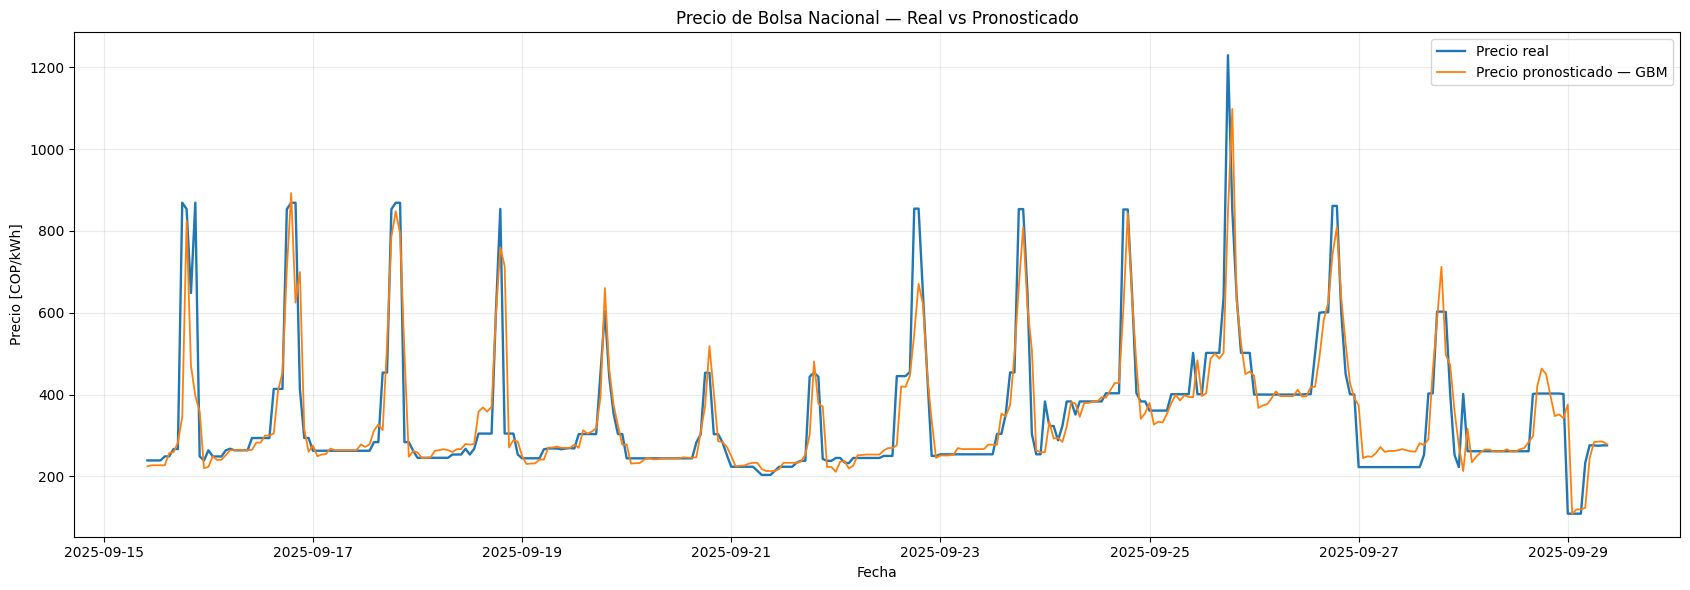

In [45]:
# ============================================================
# 11.7 PRECIO REAL VS PRONOSTICADO — TEST
# ============================================================

N_GRAFICA_TEST = min(
    336,
    len(test)
)


fig, ax = plt.subplots(
    figsize=(17,6)
)


ax.plot(

    test.index[
        :N_GRAFICA_TEST
    ],

    y_test.iloc[
        :N_GRAFICA_TEST
    ],

    label="Precio real",

    linewidth=1.7

)


ax.plot(

    test.index[
        :N_GRAFICA_TEST
    ],

    pred_test_gbm[
        :N_GRAFICA_TEST
    ],

    label="Precio pronosticado — GBM",

    linewidth=1.3

)


ax.set_title(
    "Precio de Bolsa Nacional — Real vs Pronosticado"
)


ax.set_xlabel(
    "Fecha"
)


ax.set_ylabel(
    "Precio [COP/kWh]"
)


ax.legend()

ax.grid(
    alpha=0.25
)


plt.tight_layout()

plt.show()

Residuo medio: -7.404 COP/kWh
Desviación estándar de residuos: 71.433 COP/kWh


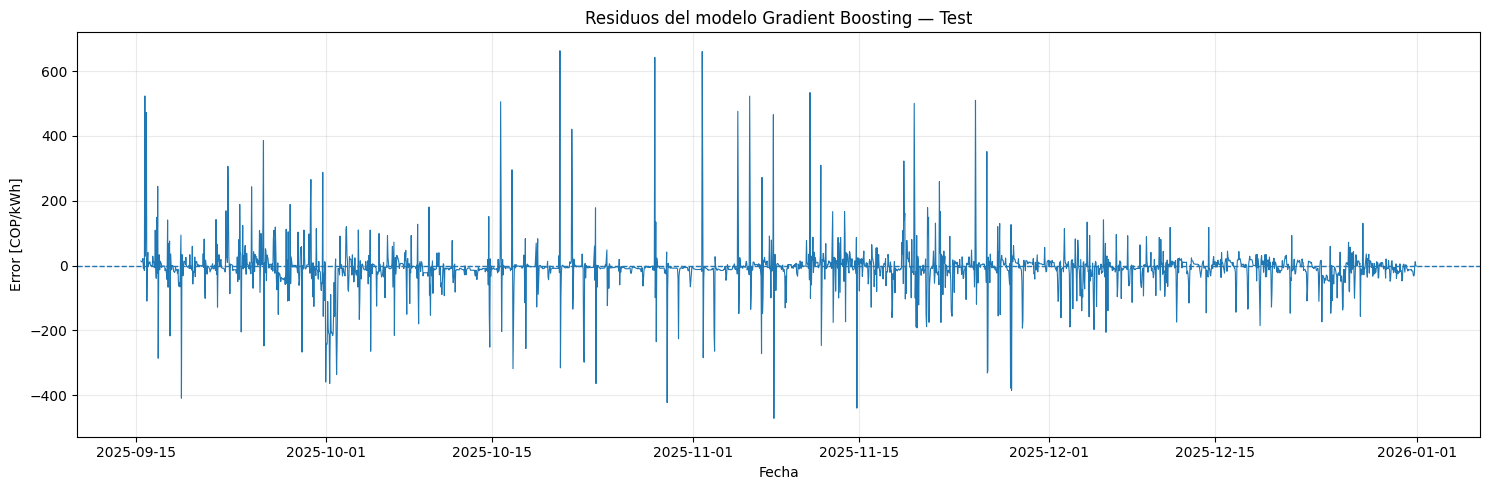

In [46]:
# ============================================================
# 11.8 ANÁLISIS DE RESIDUOS
# ============================================================

residuos_test = (

    y_test.values

    -

    pred_test_gbm

)


print(
    "Residuo medio:",
    round(
        residuos_test.mean(),
        3
    ),
    "COP/kWh"
)


print(
    "Desviación estándar de residuos:",
    round(
        residuos_test.std(),
        3
    ),
    "COP/kWh"
)


fig, ax = plt.subplots(
    figsize=(15,5)
)


ax.plot(

    test.index,

    residuos_test,

    linewidth=0.8

)


ax.axhline(
    0,
    linestyle="--",
    linewidth=1
)


ax.set_title(
    "Residuos del modelo Gradient Boosting — Test"
)


ax.set_ylabel(
    "Error [COP/kWh]"
)


ax.set_xlabel(
    "Fecha"
)


ax.grid(
    alpha=0.25
)


plt.tight_layout()

plt.show()

In [47]:
# ============================================================
# 11.9 IMPORTANCIA DE VARIABLES — MODELO FINAL
# ============================================================

importancias_gbm = pd.Series(

    gbm_final.feature_importances_,

    index=features_multi

).sort_values(

    ascending=False

)


print("=" * 70)
print("VARIABLES MÁS IMPORTANTES")
print("=" * 70)


display(

    importancias_gbm

    .head(30)

    .to_frame(
        "Importancia"
    )

    .round(4)

)

VARIABLES MÁS IMPORTANTES


,Importancia
precio_lag_1,0.5887
precio_mean_6,0.1892
precio_lag_24,0.1310
precio_mean_24,0.0475
precio_min_6,0.0149
precio_lag_2,0.0045
precio_lag_72,0.0042
hora_cos,0.0030
demanda_sin_lag_168,0.0022
precio_diff_24,0.0020


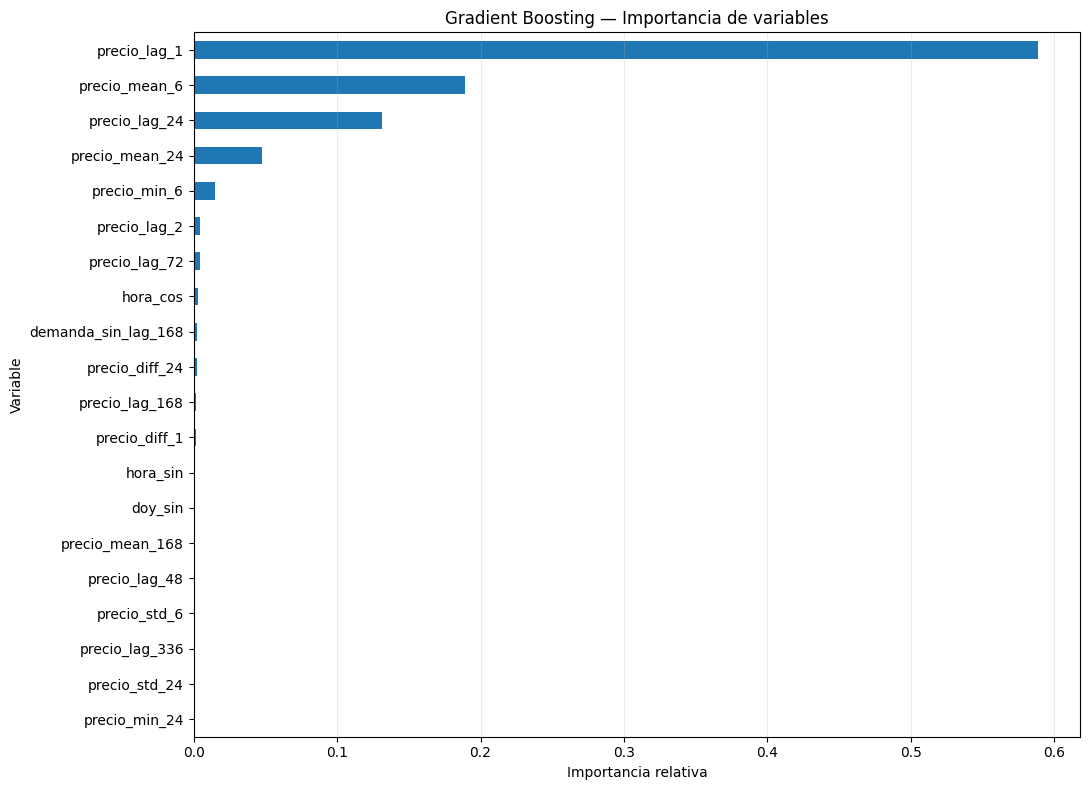

In [48]:
# ============================================================
# GRÁFICA DE IMPORTANCIA
# ============================================================

TOP_FEATURES = 20


fig, ax = plt.subplots(
    figsize=(11,8)
)


importancias_gbm.head(
    TOP_FEATURES
).sort_values().plot(

    kind="barh",

    ax=ax

)


ax.set_title(
    "Gradient Boosting — Importancia de variables"
)


ax.set_xlabel(
    "Importancia relativa"
)


ax.set_ylabel(
    "Variable"
)


ax.grid(
    axis="x",
    alpha=0.25
)


plt.tight_layout()

plt.show()

In [49]:
# ============================================================
# 11.10 GUARDAR MODELO FINAL
# ============================================================

modelo_precio_path = (

    OUTPUT_DIR

    /

    "modelo_precio_GBM_final.joblib"

)


joblib.dump(

    {

        "modelo":
            gbm_final,

        "features":
            features_multi,

        "features_base":
            features_base,

        "features_exogenas":
            features_exogenas,

        "hiperparametros":
            mejores_parametros_gbm,

        "metricas_validation":
            resultado_gbm_ajustado,

        "metricas_test":
            resultado_test_gbm,

        "fecha_inicio":
            str(
                model_data.index.min()
            ),

        "fecha_fin":
            str(
                model_data.index.max()
            )

    },

    modelo_precio_path

)


print(
    "Modelo guardado en:"
)

print(
    modelo_precio_path
)

Modelo guardado en:
outputs_tesis_ems/modelo_precio_GBM_final.joblib



# PARTE II — Módulo de pronóstico solar CNN–LSTM

Se toma la parte de modelación del notebook `Copia_de_TESIS_ESTABLE_DEF`.

Se conserva:

- descarga NASA POWER;
- preprocesamiento físico;
- ventana histórica de 120 h;
- horizonte de 24 h;
- arquitectura CNN–LSTM;
- evaluación contra referencias.

Se cambia únicamente la ubicación de **Manaure** a **Parque Solar El Paso, Cesar** y se deja 2025 disponible para integración con el EMS.


## 16. Descarga NASA POWER

In [50]:

# ============================================================
# 16. DESCARGA NASA POWER — PARQUE SOLAR EL PASO
# ============================================================

NASA_PARAMS = [
    "ALLSKY_SFC_SW_DWN",       # GHI
    "CLRSKY_SFC_SW_DWN",       # GHI cielo despejado
    "ALLSKY_SFC_SW_DIFF",      # DHI
    "ALLSKY_SFC_SW_DNI",       # DNI
    "T2M",                     # Temperatura ambiente [°C]
    "RH2M",                    # Humedad relativa [%]
    "WS10M",                   # Velocidad del viento [m/s]
    "PS"                       # Presión superficial
]


def descargar_nasa_anio(
    lat,
    lon,
    year,
    variables
):

    # --------------------------------------------------------
    # CACHE LOCAL
    # --------------------------------------------------------

    cache = (
        CACHE_DIR
        /
        f"NASA_POWER_{lat}_{lon}_{year}.csv"
    )

    if cache.exists():

        print(
            f"{year}: cargando desde caché"
        )

        return (
            pd.read_csv(
                cache,
                index_col=0,
                parse_dates=True
            )
            .sort_index()
        )


    # --------------------------------------------------------
    # CONSULTA NASA POWER
    # --------------------------------------------------------

    variables_str = ",".join(
        variables
    )


    url = (

        "https://power.larc.nasa.gov/api/temporal/hourly/point?"

        f"parameters={variables_str}"

        "&community=RE"

        f"&longitude={lon}"

        f"&latitude={lat}"

        f"&start={year}0101"

        f"&end={year}1231"

        "&time-standard=UTC"

        "&format=JSON"

    )


    print(
        f"{year}: descargando NASA POWER..."
    )


    ultimo_error = None


    # --------------------------------------------------------
    # REINTENTOS
    # --------------------------------------------------------

    for intento in range(4):

        try:

            response = requests.get(
                url,
                timeout=180
            )

            response.raise_for_status()

            data_json = response.json()


            parametros = (
                data_json[
                    "properties"
                ][
                    "parameter"
                ]
            )


            d = pd.DataFrame(
                parametros
            )


            # ------------------------------------------------
            # ÍNDICE TEMPORAL
            # ------------------------------------------------

            d.index = pd.to_datetime(

                d.index,

                format="%Y%m%d%H",

                utc=True

            )


            # UTC -> Colombia

            d.index = (

                d.index

                .tz_convert(
                    UBICACION[
                        "zona_horaria"
                    ]
                )

                .tz_localize(None)

            )


            # ------------------------------------------------
            # DATOS FALTANTES NASA
            # ------------------------------------------------

            d = d.replace(
                -999,
                np.nan
            )


            d = d.sort_index()


            # ------------------------------------------------
            # GUARDAR CACHE
            # ------------------------------------------------

            d.to_csv(
                cache
            )


            print(
                f"{year}: OK — "
                f"{len(d):,} registros"
            )


            return d


        except Exception as e:

            ultimo_error = e

            espera = 2 ** intento

            print(
                f"Intento {intento+1}/4 falló."
            )

            print(
                "Error:",
                e
            )

            print(
                f"Reintentando en {espera} s..."
            )

            time.sleep(
                espera
            )


    raise ultimo_error

In [51]:
# ============================================================
# 16.1 DESCARGA DEL PERÍODO COMPLETO
# ============================================================

partes_nasa = []


print(
    "=" * 70
)

print(
    "DESCARGA NASA POWER"
)

print(
    UBICACION["nombre"]
)

print(
    "Lat:",
    UBICACION["lat"],
    "| Lon:",
    UBICACION["lon"]
)

print(
    "=" * 70
)


for year in range(
    SOLAR_START_YEAR,
    SOLAR_END_YEAR + 1
):

    try:

        datos_year = descargar_nasa_anio(

            UBICACION["lat"],

            UBICACION["lon"],

            year,

            NASA_PARAMS

        )


        partes_nasa.append(
            datos_year
        )


    except Exception as e:

        print(
            f"\nERROR en {year}:"
        )

        print(
            e
        )


if len(partes_nasa) == 0:

    raise RuntimeError(
        "No fue posible descargar datos NASA POWER."
    )


# ------------------------------------------------------------
# UNIR TODOS LOS AÑOS
# ------------------------------------------------------------

datos_solares = (

    pd.concat(
        partes_nasa
    )

    .sort_index()

)


# Eliminar timestamps duplicados

datos_solares = datos_solares[

    ~datos_solares.index.duplicated(
        keep="first"
    )

]


print("\n")
print("=" * 70)
print("NASA POWER — DATASET COMPLETO")
print("=" * 70)


print(
    "Inicio:",
    datos_solares.index.min()
)

print(
    "Fin:",
    datos_solares.index.max()
)

print(
    "Registros:",
    f"{len(datos_solares):,}"
)


print(
    "\nColumnas:"
)

for c in datos_solares.columns:

    print(
        " -",
        c
    )


print(
    "\nDatos faltantes:"
)

display(

    datos_solares

    .isna()

    .sum()

    .to_frame(
        "NaN"
    )

)


display(
    datos_solares.head()
)

DESCARGA NASA POWER
Parque Solar El Paso, Cesar
Lat: 9.65 | Lon: -73.75
2005: descargando NASA POWER...
2005: OK — 8,760 registros
2006: descargando NASA POWER...
2006: OK — 8,760 registros
2007: descargando NASA POWER...
2007: OK — 8,760 registros
2008: descargando NASA POWER...
2008: OK — 8,784 registros
2009: descargando NASA POWER...
2009: OK — 8,760 registros
2010: descargando NASA POWER...
2010: OK — 8,760 registros
2011: descargando NASA POWER...
2011: OK — 8,760 registros
2012: descargando NASA POWER...
2012: OK — 8,784 registros
2013: descargando NASA POWER...
2013: OK — 8,760 registros
2014: descargando NASA POWER...
2014: OK — 8,760 registros
2015: descargando NASA POWER...
2015: OK — 8,760 registros
2016: descargando NASA POWER...
2016: OK — 8,784 registros
2017: descargando NASA POWER...
2017: OK — 8,760 registros
2018: descargando NASA POWER...
2018: OK — 8,760 registros
2019: descargando NASA POWER...
2019: OK — 8,760 registros
2020: descargando NASA POWER...
2020: OK — 

,NaN
ALLSKY_SFC_SW_DWN,0
CLRSKY_SFC_SW_DWN,0
ALLSKY_SFC_SW_DIFF,0
ALLSKY_SFC_SW_DNI,0
T2M,0
RH2M,0
WS10M,0
PS,0


,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DIFF,ALLSKY_SFC_SW_DNI,T2M,RH2M,WS10M,PS
2004-12-31 19:00:00,0.0,0.0,0.0,0.0,30.03,45.66,1.54,99.20
2004-12-31 20:00:00,0.0,0.0,0.0,0.0,29.10,48.50,1.50,99.31
2004-12-31 21:00:00,0.0,0.0,0.0,0.0,28.25,51.51,1.40,99.37
2004-12-31 22:00:00,0.0,0.0,0.0,0.0,27.49,54.63,1.29,99.39
2004-12-31 23:00:00,0.0,0.0,0.0,0.0,26.87,57.54,1.27,99.38


## 17. Preprocesamiento físico y Feature Engineering solar

In [52]:

# ============================================================
# 17. PREPROCESAMIENTO DE VARIABLES SOLARES
# ============================================================

def limpiar_datos_solares(df):

    d = df.copy()


    # --------------------------------------------------------
    # 1. MALLA HORARIA COMPLETA
    # --------------------------------------------------------

    indice_completo = pd.date_range(

        start=d.index.min(),

        end=d.index.max(),

        freq="h"

    )


    d = d.reindex(
        indice_completo
    )


    d.index.name = "datetime"


    # --------------------------------------------------------
    # 2. VARIABLES DE RADIACIÓN
    # --------------------------------------------------------

    solar_cols = [

        "ALLSKY_SFC_SW_DWN",

        "CLRSKY_SFC_SW_DWN",

        "ALLSKY_SFC_SW_DIFF",

        "ALLSKY_SFC_SW_DNI"

    ]


    for c in solar_cols:

        if c not in d.columns:

            continue


        d[c] = pd.to_numeric(

            d[c],

            errors="coerce"

        )


        # No puede existir irradiancia negativa

        d[c] = d[c].clip(
            lower=0
        )


        # ----------------------------------------------------
        # NOCHE
        #
        # Solo reemplazamos NaN nocturnos.
        # No alteramos valores válidos suministrados por NASA.
        # ----------------------------------------------------

        mask_nocturno = (

            (d.index.hour >= 19)

            |

            (d.index.hour <= 5)

        )


        d.loc[

            mask_nocturno

            &

            d[c].isna(),

            c

        ] = 0


        # ----------------------------------------------------
        # PEQUEÑOS HUECOS
        # Máximo 2 horas
        # ----------------------------------------------------

        d[c] = (

            d[c]

            .interpolate(
                limit=2
            )

        )


    # --------------------------------------------------------
    # 3. VARIABLES METEOROLÓGICAS
    # --------------------------------------------------------

    meteorologicas = [

        "T2M",

        "RH2M",

        "WS10M",

        "PS"

    ]


    for c in meteorologicas:

        if c not in d.columns:

            continue


        d[c] = pd.to_numeric(

            d[c],

            errors="coerce"

        )


        # Interpolación solamente para huecos pequeños

        d[c] = (

            d[c]

            .interpolate(
                limit=6
            )

            .ffill(
                limit=6
            )

            .bfill(
                limit=6
            )

        )


    # --------------------------------------------------------
    # 4. VARIABLES TEMPORALES
    # --------------------------------------------------------

    d["hora"] = (
        d.index.hour
    )

    d["dia_ano"] = (
        d.index.dayofyear
    )

    d["mes"] = (
        d.index.month
    )


    # Hora cíclica

    d["hora_sin"] = np.sin(

        2 * np.pi

        * d["hora"]

        / 24

    )


    d["hora_cos"] = np.cos(

        2 * np.pi

        * d["hora"]

        / 24

    )


    # Día del año

    d["doy_sin"] = np.sin(

        2 * np.pi

        * d["dia_ano"]

        / 365.25

    )


    d["doy_cos"] = np.cos(

        2 * np.pi

        * d["dia_ano"]

        / 365.25

    )


    # Mes

    d["mes_sin"] = np.sin(

        2 * np.pi

        * (d["mes"] - 1)

        / 12

    )


    d["mes_cos"] = np.cos(

        2 * np.pi

        * (d["mes"] - 1)

        / 12

    )


    # --------------------------------------------------------
    # 5. CLEARNESS INDEX
    # --------------------------------------------------------

    if (

        "ALLSKY_SFC_SW_DWN"
        in d.columns

        and

        "CLRSKY_SFC_SW_DWN"
        in d.columns

    ):


        cielo_claro = (

            d[
                "CLRSKY_SFC_SW_DWN"
            ]

            .replace(
                0,
                np.nan
            )

        )


        d[
            "clearness_index"
        ] = (

            d[
                "ALLSKY_SFC_SW_DWN"
            ]

            /

            cielo_claro

        )


        d[
            "clearness_index"
        ] = (

            d[
                "clearness_index"
            ]

            .clip(
                0,
                1.5
            )

            .fillna(0)

        )


    # --------------------------------------------------------
    # 6. FRACCIÓN DIFUSA
    # --------------------------------------------------------

    if (

        "ALLSKY_SFC_SW_DIFF"
        in d.columns

        and

        "ALLSKY_SFC_SW_DWN"
        in d.columns

    ):


        ghi_no_cero = (

            d[
                "ALLSKY_SFC_SW_DWN"
            ]

            .replace(
                0,
                np.nan
            )

        )


        d[
            "fraction_diffuse"
        ] = (

            d[
                "ALLSKY_SFC_SW_DIFF"
            ]

            /

            ghi_no_cero

        )


        d[
            "fraction_diffuse"
        ] = (

            d[
                "fraction_diffuse"
            ]

            .clip(
                0,
                1.5
            )

            .fillna(0)

        )


    return d

In [53]:
# ============================================================
# 17.1 DATASET SOLAR PROCESADO
# ============================================================

datos_procesados = limpiar_datos_solares(
    datos_solares
)


# ------------------------------------------------------------
# OBJETIVO
# ------------------------------------------------------------

TARGET_SOLAR = (
    "ALLSKY_SFC_SW_DWN"
)


# ------------------------------------------------------------
# VARIABLES DEL MODELO
# ------------------------------------------------------------

FEATURES_SOLAR = [

    c for c in [

        # Irradiancia histórica
        "ALLSKY_SFC_SW_DWN",

        "CLRSKY_SFC_SW_DWN",

        "ALLSKY_SFC_SW_DIFF",

        "ALLSKY_SFC_SW_DNI",


        # Clima
        "T2M",

        "RH2M",

        "WS10M",

        "PS",


        # Variables derivadas
        "clearness_index",

        "fraction_diffuse",


        # Tiempo
        "hora_sin",

        "hora_cos",

        "doy_sin",

        "doy_cos",

        "mes_sin",

        "mes_cos"

    ]

    if c
    in datos_procesados.columns

]


print(
    "=" * 70
)

print(
    "VARIABLES DEL MODELO SOLAR"
)

print(
    "=" * 70
)


print(
    "\nVariable objetivo:"
)

print(
    TARGET_SOLAR
)


print(
    "\nFeatures:"
)


for c in FEATURES_SOLAR:

    print(
        " -",
        c
    )


print(
    "\nNúmero total:",
    len(FEATURES_SOLAR)
)


print(
    "\nNaN restantes:"
)


display(

    datos_procesados[
        FEATURES_SOLAR
    ]

    .isna()

    .sum()

    .to_frame(
        "NaN"
    )

)

VARIABLES DEL MODELO SOLAR

Variable objetivo:
ALLSKY_SFC_SW_DWN

Features:
 - ALLSKY_SFC_SW_DWN
 - CLRSKY_SFC_SW_DWN
 - ALLSKY_SFC_SW_DIFF
 - ALLSKY_SFC_SW_DNI
 - T2M
 - RH2M
 - WS10M
 - PS
 - clearness_index
 - fraction_diffuse
 - hora_sin
 - hora_cos
 - doy_sin
 - doy_cos
 - mes_sin
 - mes_cos

Número total: 16

NaN restantes:


,NaN
ALLSKY_SFC_SW_DWN,0
CLRSKY_SFC_SW_DWN,0
ALLSKY_SFC_SW_DIFF,0
ALLSKY_SFC_SW_DNI,0
T2M,0
RH2M,0
WS10M,0
PS,0
clearness_index,0
fraction_diffuse,0


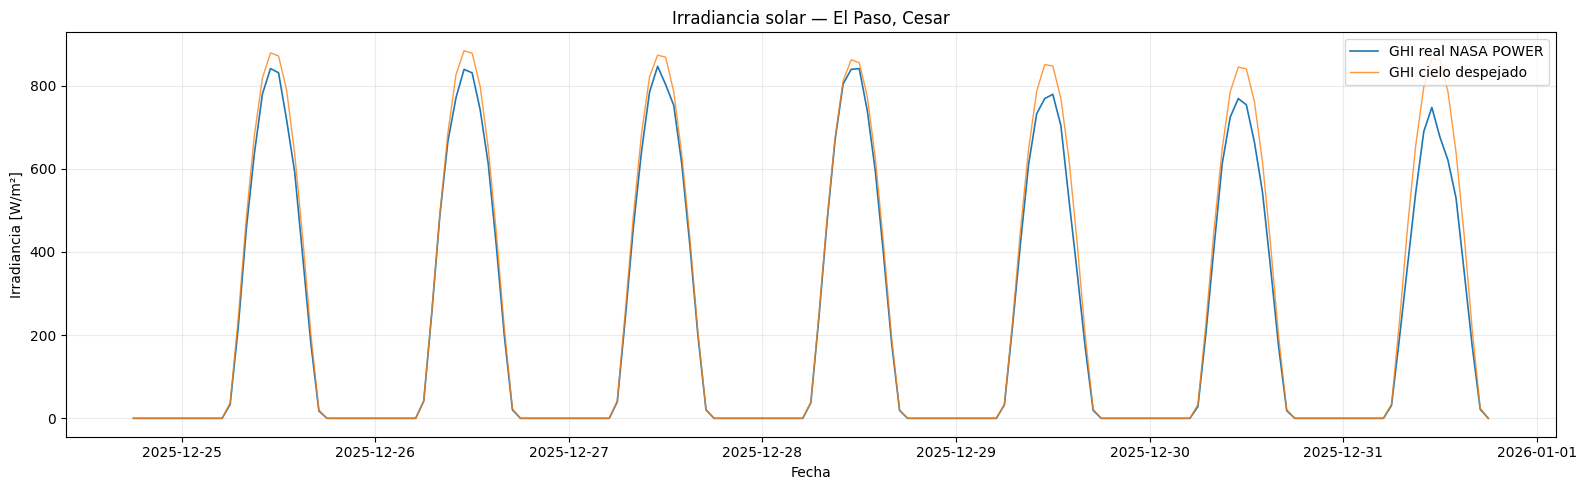

In [54]:
# ============================================================
# 17.2 REVISIÓN VISUAL — UNA SEMANA
# ============================================================

fecha_inicio_grafica = (
    datos_procesados.index.max()
    -
    pd.Timedelta(
        days=7
    )
)


solar_semana = (
    datos_procesados.loc[
        fecha_inicio_grafica:
    ]
)


fig, ax = plt.subplots(
    figsize=(16,5)
)


ax.plot(

    solar_semana.index,

    solar_semana[
        "ALLSKY_SFC_SW_DWN"
    ],

    label="GHI real NASA POWER",

    linewidth=1.2

)


ax.plot(

    solar_semana.index,

    solar_semana[
        "CLRSKY_SFC_SW_DWN"
    ],

    label="GHI cielo despejado",

    linewidth=1,

    alpha=.8

)


ax.set_title(
    "Irradiancia solar — El Paso, Cesar"
)


ax.set_ylabel(
    "Irradiancia [W/m²]"
)


ax.set_xlabel(
    "Fecha"
)


ax.legend()

ax.grid(
    alpha=.25
)


plt.tight_layout()

plt.show()

## 18. Data set limpio y división cronológica

In [55]:

# ============================================================
# 18.1 DATASET SOLAR PARA MACHINE LEARNING
# ============================================================

solar_ml = (
    datos_procesados[
        FEATURES_SOLAR
    ]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .dropna()
    .copy()
)


print("=" * 70)
print("DATASET SOLAR")
print("=" * 70)

print(
    "Inicio:",
    solar_ml.index.min()
)

print(
    "Fin:",
    solar_ml.index.max()
)

print(
    "Registros:",
    f"{len(solar_ml):,}"
)

print(
    "Features:",
    len(FEATURES_SOLAR)
)


# ------------------------------------------------------------
# DIVISIÓN CRONOLÓGICA 60 / 20 / 20
# ------------------------------------------------------------

n_solar = len(solar_ml)

i_train_solar = int(
    n_solar * 0.60
)

i_val_solar = int(
    n_solar * 0.80
)


fecha_corte_train = (
    solar_ml.index[
        i_train_solar
    ]
)

fecha_corte_val = (
    solar_ml.index[
        i_val_solar
    ]
)


print("\nCortes temporales:")

print(
    "Train termina antes de:",
    fecha_corte_train
)

print(
    "Validation termina antes de:",
    fecha_corte_val
)

print(
    "Test termina en:",
    solar_ml.index.max()
)


DATASET SOLAR
Inicio: 2004-12-31 19:00:00
Fin: 2025-12-31 18:00:00
Registros: 184,080
Features: 16

Cortes temporales:
Train termina antes de: 2017-08-07 19:00:00
Validation termina antes de: 2021-10-19 19:00:00
Test termina en: 2025-12-31 18:00:00


In [56]:
# ============================================================
# 18.2 ESCALADO — SOLO CON TRAIN
# ============================================================

from sklearn.preprocessing import StandardScaler


scaler_X_solar = StandardScaler()

scaler_y_solar = StandardScaler()


# ------------------------------------------------------------
# DATOS UTILIZADOS PARA AJUSTAR LOS SCALERS
# ------------------------------------------------------------

train_rows_solar = (
    solar_ml.loc[
        solar_ml.index
        <
        fecha_corte_train
    ]
)


# ------------------------------------------------------------
# SCALER DE FEATURES
# ------------------------------------------------------------

scaler_X_solar.fit(
    train_rows_solar[
        FEATURES_SOLAR
    ]
)


# ------------------------------------------------------------
# SCALER DE VARIABLE OBJETIVO — GHI
# ------------------------------------------------------------

scaler_y_solar.fit(
    train_rows_solar[
        [TARGET_SOLAR]
    ]
)


# ------------------------------------------------------------
# TRANSFORMAR TODO EL DATASET
# ------------------------------------------------------------

X_solar_scaled = (
    scaler_X_solar
    .transform(
        solar_ml[
            FEATURES_SOLAR
        ]
    )
)


y_solar_scaled = (
    scaler_y_solar
    .transform(
        solar_ml[
            [TARGET_SOLAR]
        ]
    )
    .reshape(-1)
)


indice_solar = (
    solar_ml.index
)


print(
    "X escalado:",
    X_solar_scaled.shape
)

print(
    "y escalado:",
    y_solar_scaled.shape
)


print(
    "\nMedia aproximada Train X:"
)

print(
    np.round(
        X_solar_scaled[
            :i_train_solar
        ].mean(axis=0)[:5],
        3
    )
)

X escalado: (184080, 16)
y escalado: (184080,)

Media aproximada Train X:
[ 0.  0. -0. -0.  0.]


In [57]:
# ============================================================
# 18.3 CONSTRUCCIÓN DE SECUENCIAS
# ============================================================

SEQUENCE_LENGTH = 120

FORECAST_HORIZON = 24


def crear_secuencias_solares(
    X,
    y,
    indice,
    sequence_length=120,
    forecast_horizon=24
):

    X_seq = []

    y_seq = []

    origenes = []

    target_inicio = []

    target_fin = []


    for i in range(
        sequence_length,
        len(indice)
        -
        forecast_horizon
        +
        1
    ):

        # ----------------------------------------------------
        # VERIFICACIÓN DE CONTINUIDAD TEMPORAL
        # ----------------------------------------------------

        inicio_hist = (
            indice[
                i-sequence_length
            ]
        )

        fin_forecast = (
            indice[
                i
                +
                forecast_horizon
                -
                1
            ]
        )


        horas_esperadas = (
            sequence_length
            +
            forecast_horizon
            -
            1
        )


        if (
            fin_forecast
            -
            inicio_hist
        ) != pd.Timedelta(
            hours=horas_esperadas
        ):

            continue


        # ----------------------------------------------------
        # ENTRADA
        # Últimas 120 horas
        # ----------------------------------------------------

        X_seq.append(

            X[
                i-sequence_length:i
            ]

        )


        # ----------------------------------------------------
        # OBJETIVO
        # Próximas 24 horas de GHI
        # ----------------------------------------------------

        y_seq.append(

            y[
                i:
                i+forecast_horizon
            ]

        )


        # Última hora conocida

        origenes.append(
            indice[i-1]
        )


        target_inicio.append(
            indice[i]
        )


        target_fin.append(
            indice[
                i
                +
                forecast_horizon
                -
                1
            ]
        )


    return (

        np.asarray(
            X_seq,
            dtype=np.float32
        ),

        np.asarray(
            y_seq,
            dtype=np.float32
        ),

        pd.DatetimeIndex(
            origenes
        ),

        pd.DatetimeIndex(
            target_inicio
        ),

        pd.DatetimeIndex(
            target_fin
        )

    )


(
    X_seq_solar,
    y_seq_solar,
    origenes_solar,
    target_inicio_solar,
    target_fin_solar

) = crear_secuencias_solares(

    X_solar_scaled,

    y_solar_scaled,

    indice_solar,

    SEQUENCE_LENGTH,

    FORECAST_HORIZON

)


print(
    "X secuencias:",
    X_seq_solar.shape
)

print(
    "y secuencias:",
    y_seq_solar.shape
)

X secuencias: (183937, 120, 16)
y secuencias: (183937, 24)


In [58]:
# ============================================================
# 18.4 SPLIT TEMPORAL DE LAS SECUENCIAS
# ============================================================

# ------------------------------------------------------------
# TRAIN
#
# El horizonte completo debe terminar antes
# del inicio de Validation.
# ------------------------------------------------------------

mask_train_solar = (

    target_fin_solar

    <

    fecha_corte_train

)


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

mask_val_solar = (

    (
        target_inicio_solar
        >=
        fecha_corte_train
    )

    &

    (
        target_fin_solar
        <
        fecha_corte_val
    )

)


# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

mask_test_solar = (

    target_inicio_solar

    >=

    fecha_corte_val

)


# ------------------------------------------------------------
# EXTRAER CONJUNTOS
# ------------------------------------------------------------

X_train_solar = (
    X_seq_solar[
        mask_train_solar
    ]
)

y_train_solar = (
    y_seq_solar[
        mask_train_solar
    ]
)


X_val_solar = (
    X_seq_solar[
        mask_val_solar
    ]
)

y_val_solar = (
    y_seq_solar[
        mask_val_solar
    ]
)


X_test_solar = (
    X_seq_solar[
        mask_test_solar
    ]
)

y_test_solar = (
    y_seq_solar[
        mask_test_solar
    ]
)


origenes_train_solar = (
    origenes_solar[
        mask_train_solar
    ]
)

origenes_val_solar = (
    origenes_solar[
        mask_val_solar
    ]
)

origenes_test_solar = (
    origenes_solar[
        mask_test_solar
    ]
)


print("=" * 70)
print("SECUENCIAS SOLARES")
print("=" * 70)


print(
    "\nTRAIN:"
)

print(
    X_train_solar.shape,
    y_train_solar.shape
)

print(
    origenes_train_solar.min(),
    "->",
    origenes_train_solar.max()
)


print(
    "\nVALIDATION:"
)

print(
    X_val_solar.shape,
    y_val_solar.shape
)

print(
    origenes_val_solar.min(),
    "->",
    origenes_val_solar.max()
)


print(
    "\nTEST:"
)

print(
    X_test_solar.shape,
    y_test_solar.shape
)

print(
    origenes_test_solar.min(),
    "->",
    origenes_test_solar.max()
)

SECUENCIAS SOLARES

TRAIN:
(110305, 120, 16) (110305, 24)
2005-01-05 18:00:00 -> 2017-08-06 18:00:00

VALIDATION:
(36793, 120, 16) (36793, 24)
2017-08-07 18:00:00 -> 2021-10-18 18:00:00

TEST:
(36793, 120, 16) (36793, 24)
2021-10-19 18:00:00 -> 2025-12-30 18:00:00


In [59]:
# ============================================================
# 18.5 MODO RÁPIDO
# ============================================================

if MODO_RAPIDO:

    print(
        "MODO_RAPIDO activo."
    )

    print(
        "Se utilizará 1 de cada 3 "
        "secuencias de Train."
    )


    X_train_solar = (
        X_train_solar[
            ::3
        ]
    )


    y_train_solar = (
        y_train_solar[
            ::3
        ]
    )


    origenes_train_solar = (
        origenes_train_solar[
            ::3
        ]
    )


print(
    "\nTrain definitivo:"
)

print(
    X_train_solar.shape,
    y_train_solar.shape
)

MODO_RAPIDO activo.
Se utilizará 1 de cada 3 secuencias de Train.

Train definitivo:
(36769, 120, 16) (36769, 24)


In [60]:
# ============================================================
# 18.6 AUDITORÍA TEMPORAL
# ============================================================

print("=" * 70)
print("AUDITORÍA DE DATA LEAKAGE")
print("=" * 70)


print(
    "\nÚltimo origen Train:"
)

print(
    origenes_train_solar.max()
)


print(
    "\nPrimer origen Validation:"
)

print(
    origenes_val_solar.min()
)


print(
    "\nÚltimo origen Validation:"
)

print(
    origenes_val_solar.max()
)


print(
    "\nPrimer origen Test:"
)

print(
    origenes_test_solar.min()
)


assert (

    origenes_train_solar.max()

    <

    origenes_val_solar.min()

)


assert (

    origenes_val_solar.max()

    <

    origenes_test_solar.min()

)


print(
    "\nOK: Train < Validation < Test."
)

print(
    "No existe mezcla temporal entre conjuntos."
)

AUDITORÍA DE DATA LEAKAGE

Último origen Train:
2017-08-06 18:00:00

Primer origen Validation:
2017-08-07 18:00:00

Último origen Validation:
2021-10-18 18:00:00

Primer origen Test:
2021-10-19 18:00:00

OK: Train < Validation < Test.
No existe mezcla temporal entre conjuntos.


## 19. Arquitectura CNN–LSTM

In [61]:

# ============================================================
# 19.1 ARQUITECTURA CNN-LSTM
# Pronóstico GHI 24 horas
# ============================================================

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam


# ------------------------------------------------------------
# LIMPIAR SESIÓN ANTERIOR
# ------------------------------------------------------------

tf.keras.backend.clear_session()


# ------------------------------------------------------------
# REPRODUCIBILIDAD
# ------------------------------------------------------------

np.random.seed(
    RANDOM_STATE
)

tf.random.set_seed(
    RANDOM_STATE
)


# ------------------------------------------------------------
# FUNCIÓN DE CONSTRUCCIÓN
# ------------------------------------------------------------

def construir_modelo_cnn_lstm(
    sequence_length,
    n_features,
    forecast_horizon
):

    modelo = Sequential(
        name="CNN_LSTM_GHI_24h"
    )


    # ========================================================
    # ENTRADA
    # 120 horas históricas × número de variables
    # ========================================================

    modelo.add(

        Input(

            shape=(
                sequence_length,
                n_features
            )

        )

    )


    # ========================================================
    # BLOQUE CNN 1
    # ========================================================

    modelo.add(

        Conv1D(

            filters=64,

            kernel_size=5,

            activation="relu",

            padding="same",

            kernel_regularizer=
                tf.keras.regularizers.l2(
                    1e-6
                )

        )

    )


    modelo.add(

        Dropout(
            0.03
        )

    )


    # ========================================================
    # BLOQUE CNN 2
    # ========================================================

    modelo.add(

        Conv1D(

            filters=32,

            kernel_size=3,

            activation="relu",

            padding="same",

            kernel_regularizer=
                tf.keras.regularizers.l2(
                    1e-6
                )

        )

    )


    modelo.add(

        MaxPooling1D(
            pool_size=2
        )

    )


    modelo.add(

        Dropout(
            0.03
        )

    )


    # ========================================================
    # BLOQUE CNN 3
    # ========================================================

    modelo.add(

        Conv1D(

            filters=16,

            kernel_size=3,

            activation="relu",

            padding="same"

        )

    )


    # ========================================================
    # BLOQUE LSTM 1
    # ========================================================

    modelo.add(

        LSTM(

            units=128,

            return_sequences=True,

            dropout=0.05,

            recurrent_dropout=0

        )

    )


    # ========================================================
    # BLOQUE LSTM 2
    # ========================================================

    modelo.add(

        LSTM(

            units=64,

            return_sequences=False,

            dropout=0.05,

            recurrent_dropout=0

        )

    )


    # ========================================================
    # CAPA DENSA
    # ========================================================

    modelo.add(

        Dense(

            units=64,

            activation="relu"

        )

    )


    modelo.add(

        Dropout(
            0.05
        )

    )


    # ========================================================
    # SALIDA
    #
    # 24 neuronas =
    # GHI t+1 ... t+24
    # ========================================================

    modelo.add(

        Dense(

            units=forecast_horizon,

            activation="linear"

        )

    )


    # ========================================================
    # COMPILACIÓN
    # ========================================================

    modelo.compile(

        optimizer=Adam(

            learning_rate=2e-4

        ),

        loss="mse",

        metrics=[
            "mae"
        ]

    )


    return modelo


In [62]:
# ============================================================
# 19.2 CREAR MODELO
# ============================================================

N_FEATURES_SOLAR = len(
    FEATURES_SOLAR
)


modelo_solar = construir_modelo_cnn_lstm(

    sequence_length=
        SEQUENCE_LENGTH,

    n_features=
        N_FEATURES_SOLAR,

    forecast_horizon=
        FORECAST_HORIZON

)


print(
    "=" * 70
)

print(
    "MODELO CNN-LSTM SOLAR"
)

print(
    "=" * 70
)


print(
    "\nEntrada:"
)

print(
    f"{SEQUENCE_LENGTH} horas "
    f"× {N_FEATURES_SOLAR} variables"
)


print(
    "\nSalida:"
)

print(
    f"{FORECAST_HORIZON} horas de GHI"
)


print(
    "\nArquitectura:"
)


modelo_solar.summary()

MODELO CNN-LSTM SOLAR

Entrada:
120 horas × 16 variables

Salida:
24 horas de GHI

Arquitectura:


Model: "CNN_LSTM_GHI_24h"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 120, 64)        │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 120, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 120, 32)        │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 60, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 60, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 60, 16)         │         1,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 60, 128)        │        74,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 142,280 (555.78 KB)

 Trainable params: 142,280 (555.78 KB)

 Non-trainable params: 0 (0.00 B)

In [63]:
# ============================================================
# 19.3 VERIFICACIÓN GPU
# ============================================================

gpus = tf.config.list_physical_devices(
    "GPU"
)


print(
    "GPU detectadas:",
    gpus
)


if len(gpus) > 0:

    print(
        "\nOK: TensorFlow utilizará GPU "
        "durante el entrenamiento."
    )

else:

    print(
        "\nADVERTENCIA: TensorFlow no detecta GPU."
    )

GPU detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

OK: TensorFlow utilizará GPU durante el entrenamiento.


In [64]:
# ============================================================
# 19.4 PRUEBA DE FORWARD PASS
# ============================================================

muestra_prueba = (
    X_train_solar[
        :2
    ]
)


salida_prueba = modelo_solar.predict(

    muestra_prueba,

    verbose=0

)


print(
    "Entrada de prueba:",
    muestra_prueba.shape
)


print(
    "Salida del modelo:",
    salida_prueba.shape
)


assert (
    salida_prueba.shape[1]
    ==
    FORECAST_HORIZON
)


print(
    "\nOK: arquitectura compatible con "
    "pronóstico de 24 horas."
)

Entrada de prueba: (2, 120, 16)
Salida del modelo: (2, 24)

OK: arquitectura compatible con pronóstico de 24 horas.


## 20. Callbacks y entrenamiento

---



In [65]:

# ============================================================
# 20.1 ENTRENAMIENTO CNN-LSTM
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# ------------------------------------------------------------
# RUTA PARA GUARDAR EL MEJOR MODELO
# ------------------------------------------------------------

ruta_mejor_modelo_solar = (
    OUTPUT_DIR
    /
    "mejor_modelo_solar_CNN_LSTM.keras"
)


# ------------------------------------------------------------
# CALLBACKS
# ------------------------------------------------------------

callbacks_solar = [

    # Detiene entrenamiento si Validation deja de mejorar
    EarlyStopping(

        monitor="val_loss",

        patience=8 if MODO_RAPIDO else 20,

        restore_best_weights=True,

        min_delta=1e-4,

        verbose=1

    ),


    # Reduce learning rate si se estanca
    ReduceLROnPlateau(

        monitor="val_loss",

        patience=4,

        factor=0.5,

        min_lr=1e-6,

        verbose=1

    ),


    # Guarda únicamente el mejor modelo
    ModelCheckpoint(

        filepath=ruta_mejor_modelo_solar,

        monitor="val_loss",

        save_best_only=True,

        verbose=1

    )

]


# ------------------------------------------------------------
# ENTRENAMIENTO
# ------------------------------------------------------------

print("=" * 70)
print("ENTRENAMIENTO CNN-LSTM SOLAR")
print("=" * 70)

print(
    "Train:",
    X_train_solar.shape,
    y_train_solar.shape
)

print(
    "Validation:",
    X_val_solar.shape,
    y_val_solar.shape
)

print(
    "Épocas máximas:",
    SOLAR_EPOCHS
)

print(
    "Batch size:",
    SOLAR_BATCH
)


history_solar = modelo_solar.fit(

    X_train_solar,

    y_train_solar,

    validation_data=(

        X_val_solar,

        y_val_solar

    ),

    epochs=SOLAR_EPOCHS,

    batch_size=SOLAR_BATCH,

    shuffle=False,

    callbacks=callbacks_solar,

    verbose=1

)


ENTRENAMIENTO CNN-LSTM SOLAR
Train: (36769, 120, 16) (36769, 24)
Validation: (36793, 120, 16) (36793, 24)
Épocas máximas: 15
Batch size: 128
Epoch 1/15
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6759 - mae: 0.6639
Epoch 1: val_loss improved from None to 0.20660, saving model to outputs_tesis_ems/mejor_modelo_solar_CNN_LSTM.keras

Epoch 1: finished saving model to outputs_tesis_ems/mejor_modelo_solar_CNN_LSTM.keras
288/288 ━━━━━━━━━━━━━━━━━━━━ 19s 28ms/step - loss: 0.3887 - mae: 0.4652 - val_loss: 0.2066 - val_mae: 0.3105 - learning_rate: 2.0000e-04
Epoch 2/15
285/288 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.1345 - mae: 0.2612
Epoch 2: val_loss improved from 0.20660 to 0.05717, saving model to outputs_tesis_ems/mejor_modelo_solar_CNN_LSTM.keras

Epoch 2: finished saving model to outputs_tesis_ems/mejor_modelo_solar_CNN_LSTM.keras
288/288 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - loss: 0.1021 - mae: 0.2268 - val_loss: 0.0572 - val_mae: 0.1544 - learning_rate: 2.0000e-04
Epoch 3/15


In [66]:
# ============================================================
# 20.2 CARGAR MEJOR MODELO
# ============================================================

modelo_solar = tf.keras.models.load_model(
    ruta_mejor_modelo_solar
)

print(
    "Mejor modelo solar cargado correctamente."
)

Mejor modelo solar cargado correctamente.


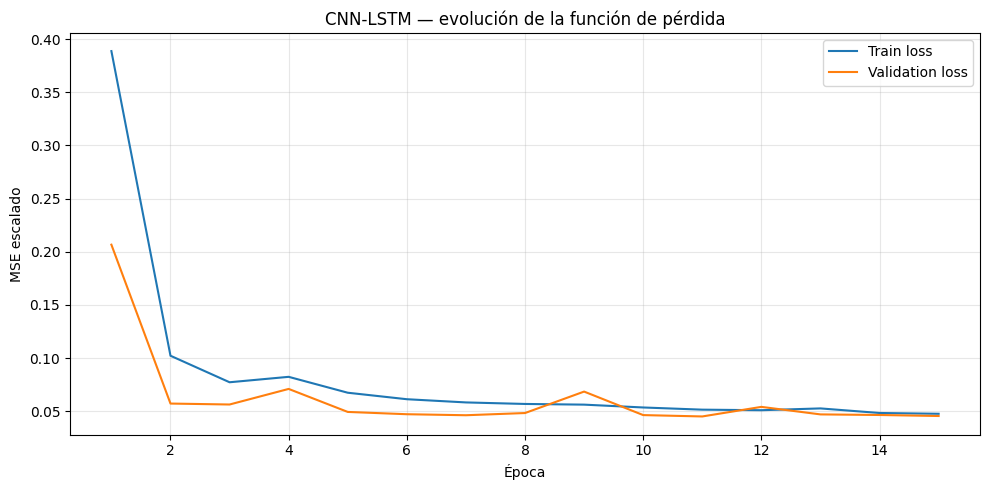

In [67]:
# ============================================================
# 20.3 CURVAS DE ENTRENAMIENTO
# ============================================================

historial = pd.DataFrame(
    history_solar.history
)


fig, ax = plt.subplots(
    figsize=(10,5)
)


ax.plot(

    historial.index + 1,

    historial["loss"],

    label="Train loss"

)


ax.plot(

    historial.index + 1,

    historial["val_loss"],

    label="Validation loss"

)


ax.set_title(
    "CNN-LSTM — evolución de la función de pérdida"
)

ax.set_xlabel(
    "Época"
)

ax.set_ylabel(
    "MSE escalado"
)

ax.legend()

ax.grid(
    alpha=.3
)


plt.tight_layout()

plt.show()

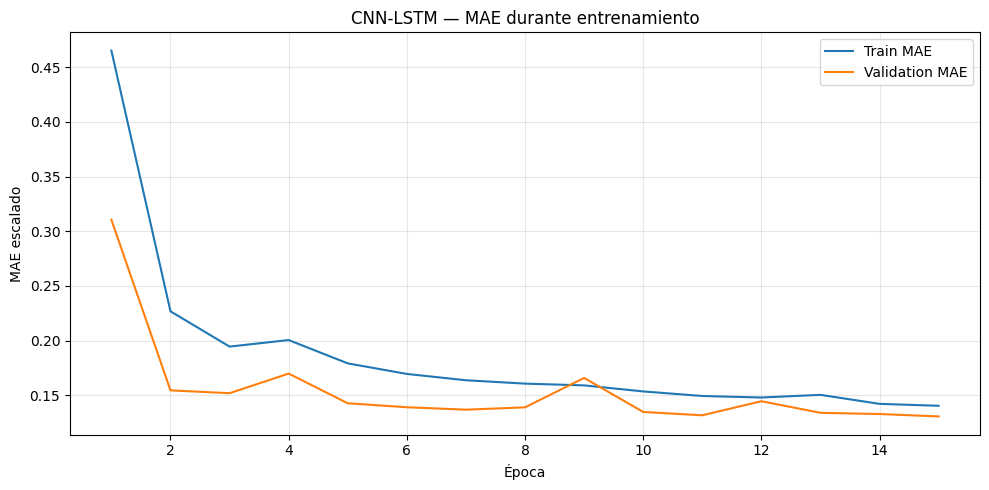

In [68]:
# ============================================================
# 20.4 CURVA MAE
# ============================================================

fig, ax = plt.subplots(
    figsize=(10,5)
)


ax.plot(

    historial.index + 1,

    historial["mae"],

    label="Train MAE"

)


ax.plot(

    historial.index + 1,

    historial["val_mae"],

    label="Validation MAE"

)


ax.set_title(
    "CNN-LSTM — MAE durante entrenamiento"
)

ax.set_xlabel(
    "Época"
)

ax.set_ylabel(
    "MAE escalado"
)

ax.legend()

ax.grid(
    alpha=.3
)


plt.tight_layout()

plt.show()

## 21. Evaluación del CNN-LSTM solar

In [69]:

# ============================================================
# 21.1 PREDICCIÓN SOBRE TEST
# ============================================================

print("=" * 70)
print("EVALUACIÓN CNN-LSTM — TEST")
print("=" * 70)


# ------------------------------------------------------------
# PREDICCIÓN NORMALIZADA
# ------------------------------------------------------------

pred_solar_scaled = modelo_solar.predict(

    X_test_solar,

    batch_size=256,

    verbose=1

)


print(
    "\nPredicciones escaladas:",
    pred_solar_scaled.shape
)


# ------------------------------------------------------------
# DESNORMALIZAR PREDICCIONES
# ------------------------------------------------------------

pred_solar = (

    scaler_y_solar

    .inverse_transform(

        pred_solar_scaled.reshape(
            -1,
            1
        )

    )

    .reshape(
        pred_solar_scaled.shape
    )

)


# ------------------------------------------------------------
# DESNORMALIZAR VALORES REALES
# ------------------------------------------------------------

real_solar = (

    scaler_y_solar

    .inverse_transform(

        y_test_solar.reshape(
            -1,
            1
        )

    )

    .reshape(
        y_test_solar.shape
    )

)


# ------------------------------------------------------------
# RESTRICCIÓN FÍSICA
#
# GHI no puede ser negativo
# ------------------------------------------------------------

pred_solar = np.maximum(
    pred_solar,
    0
)


print(
    "\nReal:",
    real_solar.shape
)

print(
    "Predicción:",
    pred_solar.shape
)


print(
    "\nGHI real:"
)

print(
    "mín:",
    round(
        real_solar.min(),
        2
    )
)

print(
    "máx:",
    round(
        real_solar.max(),
        2
    )
)


print(
    "\nGHI pronosticado:"
)

print(
    "mín:",
    round(
        pred_solar.min(),
        2
    )
)

print(
    "máx:",
    round(
        pred_solar.max(),
        2
    )
)

EVALUACIÓN CNN-LSTM — TEST
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step

Predicciones escaladas: (36793, 24)

Real: (36793, 24)
Predicción: (36793, 24)

GHI real:
mín: -0.0
máx: 1001.83

GHI pronosticado:
mín: 0.0
máx: 912.6


In [70]:
# ============================================================
# 21.2 MÉTRICAS GLOBALES
# ============================================================

real_flat = real_solar.flatten()

pred_flat = pred_solar.flatten()


# ------------------------------------------------------------
# MAE
# ------------------------------------------------------------

mae_solar = mean_absolute_error(

    real_flat,

    pred_flat

)


# ------------------------------------------------------------
# RMSE
# ------------------------------------------------------------

mse_solar = mean_squared_error(

    real_flat,

    pred_flat

)

rmse_solar = np.sqrt(
    mse_solar
)


# ------------------------------------------------------------
# R²
# ------------------------------------------------------------

r2_solar = r2_score(

    real_flat,

    pred_flat

)


# ------------------------------------------------------------
# NRMSE
#
# normalizado respecto a la media absoluta del GHI
# ------------------------------------------------------------

media_ghi = np.mean(
    np.abs(
        real_flat
    )
)


nrmse_solar = (

    rmse_solar

    /

    media_ghi

    * 100

)


# ------------------------------------------------------------
# MAPE DIURNO
# Solo GHI > 50 W/m²
# ------------------------------------------------------------

mask_dia = (

    real_flat
    >
    50
)


mape_solar_dia = (

    np.mean(

        np.abs(

            (
                real_flat[
                    mask_dia
                ]

                -

                pred_flat[
                    mask_dia
                ]
            )

            /

            real_flat[
                mask_dia
            ]

        )

    )

    * 100

)


resultado_solar = pd.DataFrame({

    "MAE [W/m²]": [
        mae_solar
    ],

    "RMSE [W/m²]": [
        rmse_solar
    ],

    "R2": [
        r2_solar
    ],

    "MAPE diurno [%]": [
        mape_solar_dia
    ],

    "NRMSE [%]": [
        nrmse_solar
    ]

},
index=[
    "CNN-LSTM — TEST"
])


display(

    resultado_solar.style.format({

        "MAE [W/m²]":
            "{:.2f}",

        "RMSE [W/m²]":
            "{:.2f}",

        "R2":
            "{:.4f}",

        "MAPE diurno [%]":
            "{:.2f}",

        "NRMSE [%]":
            "{:.2f}"

    })

)

,MAE [W/m²],RMSE [W/m²],R2,MAPE diurno [%],NRMSE [%]
CNN-LSTM — TEST,34.59,60.37,0.9571,21.02,27.41


In [71]:
# ============================================================
# 21.3 BENCHMARK — PERSISTENCIA 24H
# ============================================================

pred_persistencia = []


for origen in origenes_test_solar:

    fechas_futuras = pd.date_range(

        origen
        +
        pd.Timedelta(
            hours=1
        ),

        periods=FORECAST_HORIZON,

        freq="h"

    )


    valores = []


    for fecha in fechas_futuras:

        fecha_anterior = (

            fecha

            -

            pd.Timedelta(
                hours=24
            )

        )


        if (

            fecha_anterior

            in

            datos_procesados.index

        ):

            valor = datos_procesados.loc[

                fecha_anterior,

                TARGET_SOLAR

            ]


            if pd.isna(
                valor
            ):

                valor = 0


        else:

            valor = 0


        valores.append(
            float(valor)
        )


    pred_persistencia.append(
        valores
    )


pred_persistencia = np.asarray(
    pred_persistencia
)


print(
    "Persistencia:",
    pred_persistencia.shape
)

Persistencia: (36793, 24)


In [72]:
# ============================================================
# 21.4 CNN-LSTM VS PERSISTENCIA
# ============================================================

persist_flat = (
    pred_persistencia.flatten()
)


# ------------------------------------------------------------
# PERSISTENCIA
# ------------------------------------------------------------

mae_persist = mean_absolute_error(

    real_flat,

    persist_flat

)


rmse_persist = np.sqrt(

    mean_squared_error(

        real_flat,

        persist_flat

    )

)


r2_persist = r2_score(

    real_flat,

    persist_flat

)


mape_persist_dia = (

    np.mean(

        np.abs(

            (
                real_flat[
                    mask_dia
                ]

                -

                persist_flat[
                    mask_dia
                ]
            )

            /

            real_flat[
                mask_dia
            ]

        )

    )

    * 100

)


comparacion_solar = pd.DataFrame({

    "Modelo": [

        "Persistencia 24h",

        "CNN-LSTM"

    ],

    "MAE [W/m²]": [

        mae_persist,

        mae_solar

    ],

    "RMSE [W/m²]": [

        rmse_persist,

        rmse_solar

    ],

    "R2": [

        r2_persist,

        r2_solar

    ],

    "MAPE diurno [%]": [

        mape_persist_dia,

        mape_solar_dia

    ]

})


display(

    comparacion_solar

    .set_index(
        "Modelo"
    )

    .style.format({

        "MAE [W/m²]":
            "{:.2f}",

        "RMSE [W/m²]":
            "{:.2f}",

        "R2":
            "{:.4f}",

        "MAPE diurno [%]":
            "{:.2f}"

    })

)

,MAE [W/m²],RMSE [W/m²],R2,MAPE diurno [%]
Modelo,,,,
Persistencia 24h,31.97,68.20,0.9452,18.53
CNN-LSTM,34.59,60.37,0.9571,21.02


In [73]:
mejora_rmse_solar = (

    (
        rmse_persist

        -

        rmse_solar
    )

    /

    rmse_persist

    * 100

)


print(

    f"Mejora de RMSE del CNN-LSTM "
    f"frente a persistencia: "
    f"{mejora_rmse_solar:.2f}%"

)

Mejora de RMSE del CNN-LSTM frente a persistencia: 11.47%


In [74]:
# ============================================================
# 21.5 ERROR POR HORIZONTE
# ============================================================

metricas_horizonte = []


for h in range(
    FORECAST_HORIZON
):

    y_real_h = (
        real_solar[
            :,
            h
        ]
    )

    y_pred_h = (
        pred_solar[
            :,
            h
        ]
    )


    mae_h = mean_absolute_error(

        y_real_h,

        y_pred_h

    )


    rmse_h = np.sqrt(

        mean_squared_error(

            y_real_h,

            y_pred_h

        )

    )


    r2_h = r2_score(

        y_real_h,

        y_pred_h

    )


    metricas_horizonte.append({

        "Horizonte":
            h + 1,

        "MAE":
            mae_h,

        "RMSE":
            rmse_h,

        "R2":
            r2_h

    })


metricas_horizonte_solar = (
    pd.DataFrame(
        metricas_horizonte
    )
)


display(

    metricas_horizonte_solar

    .style.format({

        "MAE":
            "{:.2f}",

        "RMSE":
            "{:.2f}",

        "R2":
            "{:.4f}"

    })

)

,Horizonte,MAE,RMSE,R2
0,1,32.34,53.03,0.9669
1,2,28.62,52.67,0.9673
2,3,30.97,54.90,0.9645
3,4,36.16,60.34,0.9571
4,5,32.55,58.03,0.9603
5,6,34.21,59.46,0.9583
6,7,38.84,63.59,0.9524
7,8,32.64,59.87,0.9578
8,9,35.65,61.39,0.9556
9,10,39.93,65.23,0.9499


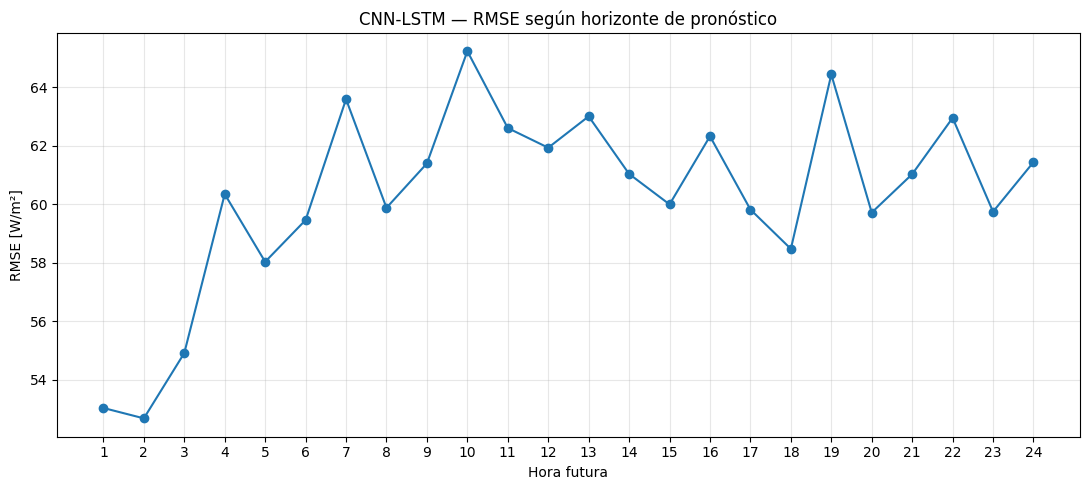

In [75]:
fig, ax = plt.subplots(
    figsize=(11,5)
)


ax.plot(

    metricas_horizonte_solar[
        "Horizonte"
    ],

    metricas_horizonte_solar[
        "RMSE"
    ],

    marker="o"

)


ax.set_title(
    "CNN-LSTM — RMSE según horizonte de pronóstico"
)


ax.set_xlabel(
    "Hora futura"
)


ax.set_ylabel(
    "RMSE [W/m²]"
)


ax.set_xticks(
    range(
        1,
        25
    )
)


ax.grid(
    alpha=.3
)


plt.tight_layout()

plt.show()

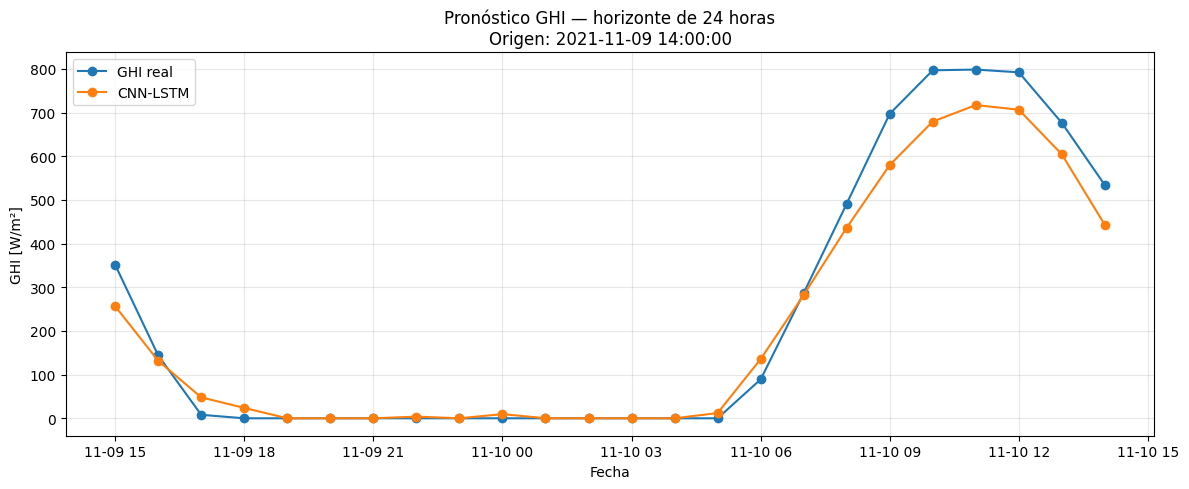

In [76]:
# ============================================================
# 21.6 EJEMPLO DE PRONÓSTICO DE 24 HORAS
# ============================================================

ejemplo = min(
    500,
    len(
        real_solar
    )
    -
    1
)


origen_ejemplo = (

    origenes_test_solar[
        ejemplo
    ]

)


fechas_ejemplo = pd.date_range(

    origen_ejemplo

    +

    pd.Timedelta(
        hours=1
    ),

    periods=FORECAST_HORIZON,

    freq="h"

)


fig, ax = plt.subplots(
    figsize=(12,5)
)


ax.plot(

    fechas_ejemplo,

    real_solar[
        ejemplo
    ],

    marker="o",

    label="GHI real"

)


ax.plot(

    fechas_ejemplo,

    pred_solar[
        ejemplo
    ],

    marker="o",

    label="CNN-LSTM"

)


ax.set_title(

    "Pronóstico GHI — horizonte de 24 horas\n"

    +

    f"Origen: {origen_ejemplo}"

)


ax.set_ylabel(
    "GHI [W/m²]"
)


ax.set_xlabel(
    "Fecha"
)


ax.legend()

ax.grid(
    alpha=.3
)


plt.tight_layout()

plt.show()


## 22. Conversión GHI → potencia fotovoltaica




In [78]:

# ============================================================
# 22.1 MODELO GHI -> POTENCIA FOTOVOLTAICA
# Parque Solar El Paso
# ============================================================

def potencia_pv_desde_ghi(
    ghi,
    temperatura_ambiente,
    factor_calibracion=1.0
):
    """
    Conversión simplificada de GHI [W/m²]
    a potencia AC de planta [MW].

    Considera:
    - Potencia DC instalada
    - Temperatura de celda mediante NOCT
    - Coeficiente térmico
    - Factor global de calibración
    - Límite AC del parque
    """

    ghi = np.asarray(
        ghi,
        dtype=float
    )

    temperatura_ambiente = np.asarray(
        temperatura_ambiente,
        dtype=float
    )


    # --------------------------------------------------------
    # TEMPERATURA APROXIMADA DE LA CELDA
    # --------------------------------------------------------

    temperatura_celda = (

        temperatura_ambiente

        +

        (
            (PV_NOCT_C - 20.0)
            /
            800.0
        )

        * ghi

    )


    # --------------------------------------------------------
    # CORRECCIÓN POR TEMPERATURA
    # --------------------------------------------------------

    factor_temperatura = (

        1

        +

        PV_GAMMA_PCT_C

        *

        (
            temperatura_celda
            -
            25
        )

    )


    factor_temperatura = np.clip(

        factor_temperatura,

        0.70,

        1.10

    )


    # --------------------------------------------------------
    # POTENCIA DC
    # --------------------------------------------------------

    potencia_dc = (

        PV_DC_MW

        *

        factor_calibracion

        *

        (
            ghi
            /
            1000.0
        )

        *

        factor_temperatura

    )


    # --------------------------------------------------------
    # CLIPPING AC
    # --------------------------------------------------------

    potencia_ac = np.clip(

        potencia_dc,

        0,

        PV_AC_MW

    )


    return potencia_ac


In [79]:
# ============================================================
# 22.2 CALIBRACIÓN DEL MODELO PV
# ============================================================

def energia_anual_media_pv(
    factor,
    datos
):

    potencia = potencia_pv_desde_ghi(

        datos[
            "ALLSKY_SFC_SW_DWN"
        ].values,

        datos[
            "T2M"
        ].values,

        factor

    )


    serie_potencia = pd.Series(

        potencia,

        index=datos.index

    )


    energia_anual = (

        serie_potencia

        .groupby(
            serie_potencia.index.year
        )

        .sum()

    )


    return (

        energia_anual.mean(),

        energia_anual

    )


def calibrar_factor_pv(
    datos,
    energia_objetivo_mwh
):

    inferior = 0.10

    superior = 5.0


    for _ in range(60):

        medio = (

            inferior

            +

            superior

        ) / 2


        energia_media, _ = (
            energia_anual_media_pv(
                medio,
                datos
            )
        )


        if (
            energia_media
            <
            energia_objetivo_mwh
        ):

            inferior = medio

        else:

            superior = medio


    return (

        inferior

        +

        superior

    ) / 2

In [80]:
# ============================================================
# 22.3 CALIBRAR CON HISTÓRICO PRE-TEST
# ============================================================

fecha_inicio_test_solar = (
    origenes_test_solar.min()
)


datos_calibracion_pv = (

    datos_procesados.loc[
        :
        fecha_inicio_test_solar
    ][
        [
            "ALLSKY_SFC_SW_DWN",
            "T2M"
        ]
    ]

    .dropna()

)


PV_FACTOR = calibrar_factor_pv(

    datos_calibracion_pv,

    PV_ANNUAL_TARGET_MWH

)


energia_media_calibrada, energia_por_anio = (
    energia_anual_media_pv(

        PV_FACTOR,

        datos_calibracion_pv

    )
)


print("=" * 70)
print("CALIBRACIÓN DEL MODELO FOTOVOLTAICO")
print("=" * 70)


print(
    f"Factor de calibración: "
    f"{PV_FACTOR:.4f}"
)


print(
    f"Energía anual media modelada: "
    f"{energia_media_calibrada:,.1f} MWh/año"
)


print(
    f"Objetivo de referencia: "
    f"{PV_ANNUAL_TARGET_MWH:,.1f} MWh/año"
)


print(
    f"Potencia DC: "
    f"{PV_DC_MW:.2f} MW"
)


print(
    f"Potencia AC máxima: "
    f"{PV_AC_MW:.2f} MW"
)

CALIBRACIÓN DEL MODELO FOTOVOLTAICO
Factor de calibración: 1.6262
Energía anual media modelada: 203,500.0 MWh/año
Objetivo de referencia: 203,500.0 MWh/año
Potencia DC: 99.50 MW
Potencia AC máxima: 67.92 MW


In [81]:
# ============================================================
# 22.4 GENERACIÓN PV MODELADA
# ============================================================

datos_procesados[
    "pv_real_modelado_MW"
] = np.nan


mask_pv = (

    datos_procesados[
        "ALLSKY_SFC_SW_DWN"
    ].notna()

    &

    datos_procesados[
        "T2M"
    ].notna()

)


datos_procesados.loc[
    mask_pv,
    "pv_real_modelado_MW"
] = potencia_pv_desde_ghi(

    datos_procesados.loc[
        mask_pv,
        "ALLSKY_SFC_SW_DWN"
    ],

    datos_procesados.loc[
        mask_pv,
        "T2M"
    ],

    PV_FACTOR

)


print(
    datos_procesados[
        "pv_real_modelado_MW"
    ]
    .describe()
    .round(3)
)

count    184080.000
mean         24.853
std          29.874
min           0.000
25%           0.000
50%           0.863
75%          67.920
max          67.920
Name: pv_real_modelado_MW, dtype: float64


In [82]:
# ============================================================
# 22.5 GHI PRONOSTICADO -> POTENCIA PV PRONOSTICADA
# ============================================================

def pronostico_pv_24h(
    origen,
    ghi_predicho
):

    origen = pd.Timestamp(
        origen
    )


    fechas_futuras = pd.date_range(

        origen
        +
        pd.Timedelta(
            hours=1
        ),

        periods=len(
            ghi_predicho
        ),

        freq="h"

    )


    # --------------------------------------------------------
    # TEMPERATURA FUTURA
    #
    # Para esta versión utilizamos persistencia 24 h.
    # Posteriormente puede reemplazarse por un pronóstico
    # meteorológico específico.
    # --------------------------------------------------------

    temperaturas = []


    for fecha in fechas_futuras:

        fecha_hist = (

            fecha

            -

            pd.Timedelta(
                hours=24
            )

        )


        if (

            fecha_hist
            in
            datos_procesados.index

            and

            pd.notna(

                datos_procesados.loc[
                    fecha_hist,
                    "T2M"
                ]

            )

        ):

            temp = float(

                datos_procesados.loc[
                    fecha_hist,
                    "T2M"
                ]

            )


        else:

            temp = float(

                datos_procesados.loc[
                    :origen,
                    "T2M"
                ]

                .dropna()

                .iloc[-1]

            )


        temperaturas.append(
            temp
        )


    # --------------------------------------------------------
    # POTENCIA PV
    # --------------------------------------------------------

    pv_predicho = potencia_pv_desde_ghi(

        ghi_predicho,

        temperaturas,

        PV_FACTOR

    )


    return pd.DataFrame({

        "GHI_pred_Wm2":
            ghi_predicho,

        "Temp_pred_C":
            temperaturas,

        "PV_pred_MW":
            pv_predicho

    },
    index=fechas_futuras)


# PARTE III — Optimización PV–BESS y Rolling Horizon


## 23. Optimización de arbitraje

In [83]:

# ============================================================
# 23.1 PARÁMETROS DEL OPTIMIZADOR PV-BESS
# ============================================================

DELTA_T = 1.0            # [h]

BESS_POWER_MW = 30.0
BESS_ENERGY_MWH = 60.0

SOC_MIN = 0.10
SOC_MAX = 0.90
SOC_INITIAL = 0.50

ETA_C = 0.96
ETA_D = 0.96

# Límite AC utilizado para la inyección del sistema híbrido
EXPORT_LIMIT_MW = PV_AC_MW

# Rampa documentada: 10 MW/min
RAMP_MAX_MW_MIN = 10.0

# En resolución horaria:
RAMP_MAX_MW_H = (
    RAMP_MAX_MW_MIN
    * 60
)

# Como el BESS solo puede entregar 30 MW,
# a resolución de 1 h esta restricción no será vinculante.
print("=" * 70)
print("PARÁMETROS PV-BESS")
print("=" * 70)

print(
    f"BESS: {BESS_POWER_MW:.1f} MW / "
    f"{BESS_ENERGY_MWH:.1f} MWh"
)

print(
    f"SoC: {SOC_MIN*100:.0f}% "
    f"-> {SOC_MAX*100:.0f}%"
)

print(
    f"Eficiencia carga: {ETA_C:.2%}"
)

print(
    f"Eficiencia descarga: {ETA_D:.2%}"
)

print(
    f"Eficiencia round-trip aproximada: "
    f"{ETA_C*ETA_D:.2%}"
)

print(
    f"Límite de exportación: "
    f"{EXPORT_LIMIT_MW:.2f} MW"
)

print(
    f"Rampa equivalente horaria: "
    f"{RAMP_MAX_MW_H:.1f} MW/h"
)

PARÁMETROS PV-BESS
BESS: 30.0 MW / 60.0 MWh
SoC: 10% -> 90%
Eficiencia carga: 96.00%
Eficiencia descarga: 96.00%
Eficiencia round-trip aproximada: 92.16%
Límite de exportación: 67.92 MW
Rampa equivalente horaria: 600.0 MW/h


In [84]:
# ============================================================
# 23.2 OPTIMIZACIÓN MILP PV-BESS — PYOMO
# ============================================================

def optimizar_pv_bess_24h(
    precios_cop_kwh,
    pv_pred_mw,
    soc_inicial_mwh,
    costo_degradacion_cop_mwh=0.0,
    mantener_soc_final=True
):

    precios = np.asarray(
        precios_cop_kwh,
        dtype=float
    )

    pv = np.asarray(
        pv_pred_mw,
        dtype=float
    )

    H = len(precios)

    # --------------------------------------------------------
    # VALIDACIONES
    # --------------------------------------------------------

    if len(pv) != H:
        raise ValueError(
            "Precio y PV deben tener "
            "la misma longitud."
        )

    if H != 24:
        print(
            f"Advertencia: horizonte = {H} h "
            "en lugar de 24 h."
        )

    # --------------------------------------------------------
    # LÍMITES EN MWh
    # --------------------------------------------------------

    E_MIN = (
        SOC_MIN
        *
        BESS_ENERGY_MWH
    )

    E_MAX = (
        SOC_MAX
        *
        BESS_ENERGY_MWH
    )

    if not (
        E_MIN
        <= soc_inicial_mwh
        <= E_MAX
    ):
        raise ValueError(
            "SoC inicial fuera "
            "de límites."
        )

    # ========================================================
    # MODELO
    # ========================================================

    m = pyo.ConcreteModel(
        name="EMS_PV_BESS"
    )

    m.T = pyo.RangeSet(
        0,
        H - 1
    )

    # ========================================================
    # VARIABLES CONTINUAS
    # ========================================================

    # PV enviada directamente a red
    m.pv_grid = pyo.Var(
        m.T,
        domain=pyo.NonNegativeReals
    )

    # Potencia de carga BESS
    m.charge = pyo.Var(
        m.T,
        domain=pyo.NonNegativeReals,
        bounds=(0, BESS_POWER_MW)
    )

    # Potencia de descarga BESS
    m.discharge = pyo.Var(
        m.T,
        domain=pyo.NonNegativeReals,
        bounds=(0, BESS_POWER_MW)
    )

    # Curtailment PV
    m.curtail = pyo.Var(
        m.T,
        domain=pyo.NonNegativeReals
    )

    # Energía almacenada
    m.energy = pyo.Var(
        m.T,
        domain=pyo.NonNegativeReals,
        bounds=(E_MIN, E_MAX)
    )

    # ========================================================
    # VARIABLES BINARIAS
    # ========================================================

    m.u_charge = pyo.Var(
        m.T,
        domain=pyo.Binary
    )

    m.u_discharge = pyo.Var(
        m.T,
        domain=pyo.Binary
    )

    # ========================================================
    # 1. BALANCE DE POTENCIA PV
    #
    # PV disponible =
    # PV a red + carga BESS + curtailment
    #
    # No permitimos cargar desde la red.
    # ========================================================

    def balance_pv_rule(
        mm,
        t
    ):

        return (

            mm.pv_grid[t]

            +

            mm.charge[t]

            +

            mm.curtail[t]

            ==

            float(
                pv[t]
            )

        )


    m.balance_pv = pyo.Constraint(
        m.T,
        rule=balance_pv_rule
    )

    # ========================================================
    # 2. LÍMITE DE POTENCIA DE CARGA
    # ========================================================

    def limite_carga_rule(
        mm,
        t
    ):

        return (

            mm.charge[t]

            <=

            BESS_POWER_MW
            *
            mm.u_charge[t]

        )


    m.limite_carga = pyo.Constraint(
        m.T,
        rule=limite_carga_rule
    )

    # ========================================================
    # 3. LÍMITE DE POTENCIA DE DESCARGA
    # ========================================================

    def limite_descarga_rule(
        mm,
        t
    ):

        return (

            mm.discharge[t]

            <=

            BESS_POWER_MW
            *
            mm.u_discharge[t]

        )


    m.limite_descarga = pyo.Constraint(
        m.T,
        rule=limite_descarga_rule
    )

    # ========================================================
    # 4. EXCLUSIVIDAD CARGA / DESCARGA
    # ========================================================

    def exclusividad_rule(
        mm,
        t
    ):

        return (

            mm.u_charge[t]

            +

            mm.u_discharge[t]

            <= 1

        )


    m.exclusividad = pyo.Constraint(
        m.T,
        rule=exclusividad_rule
    )

    # ========================================================
    # 5. BALANCE DE ENERGÍA DEL BESS
    #
    # E(t) =
    # E(t-1)
    # + eta_c Pc dt
    # - Pd dt / eta_d
    # ========================================================

    def energy_balance_rule(
        mm,
        t
    ):

        energia_anterior = (

            soc_inicial_mwh

            if t == 0

            else mm.energy[
                t - 1
            ]

        )

        return (

            mm.energy[t]

            ==

            energia_anterior

            +

            ETA_C
            *
            mm.charge[t]
            *
            DELTA_T

            -

            (
                mm.discharge[t]
                *
                DELTA_T
                /
                ETA_D
            )

        )


    m.energy_balance = pyo.Constraint(
        m.T,
        rule=energy_balance_rule
    )

    # ========================================================
    # 6. LÍMITE DE INYECCIÓN
    #
    # PV directa + descarga BESS
    # no puede superar capacidad AC.
    # ========================================================

    def export_limit_rule(
        mm,
        t
    ):

        return (

            mm.pv_grid[t]

            +

            mm.discharge[t]

            <=

            EXPORT_LIMIT_MW

        )


    m.export_limit = pyo.Constraint(
        m.T,
        rule=export_limit_rule
    )

    # ========================================================
    # 7. RAMPA DEL BESS
    #
    # Potencia neta:
    # P_BESS = descarga - carga
    # ========================================================

    def ramp_up_rule(
        mm,
        t
    ):

        if t == 0:
            return pyo.Constraint.Skip

        p_actual = (
            mm.discharge[t]
            -
            mm.charge[t]
        )

        p_anterior = (
            mm.discharge[t-1]
            -
            mm.charge[t-1]
        )

        return (

            p_actual
            -
            p_anterior

            <=

            RAMP_MAX_MW_H

        )


    def ramp_down_rule(
        mm,
        t
    ):

        if t == 0:
            return pyo.Constraint.Skip

        p_actual = (
            mm.discharge[t]
            -
            mm.charge[t]
        )

        p_anterior = (
            mm.discharge[t-1]
            -
            mm.charge[t-1]
        )

        return (

            p_anterior
            -
            p_actual

            <=

            RAMP_MAX_MW_H

        )


    m.ramp_up = pyo.Constraint(
        m.T,
        rule=ramp_up_rule
    )

    m.ramp_down = pyo.Constraint(
        m.T,
        rule=ramp_down_rule
    )

    # ========================================================
    # 8. CONDICIÓN TERMINAL
    #
    # Evita que el optimizador "haga trampa"
    # vaciando la batería al final del horizonte.
    # ========================================================

    if mantener_soc_final:

        m.soc_terminal = pyo.Constraint(

            expr=

            m.energy[
                H - 1
            ]

            ==

            soc_inicial_mwh

        )

    # ========================================================
    # FUNCIÓN OBJETIVO
    #
    # MAX:
    # ingresos por energía exportada
    # -
    # costo de degradación del BESS
    # ========================================================

    ingresos = sum(

        float(
            precios[t]
        )

        *

        1000.0

        *

        (
            m.pv_grid[t]

            +

            m.discharge[t]
        )

        *

        DELTA_T

        for t in range(H)

    )


    costo_degradacion = sum(

        costo_degradacion_cop_mwh

        *

        (
            m.charge[t]

            +

            m.discharge[t]
        )

        *

        DELTA_T

        for t in range(H)

    )


    m.obj = pyo.Objective(

        expr=

        ingresos

        -

        costo_degradacion,

        sense=pyo.maximize

    )

    # ========================================================
    # SOLVER
    # ========================================================

    solver = pyo.SolverFactory(
        "appsi_highs"
    )

    if not solver.available(
        False
    ):

        solver = pyo.SolverFactory(
            "highs"
        )


    resultado_solver = solver.solve(
        m
    )

    # ========================================================
    # EXTRAER RESULTADOS
    # ========================================================

    resultados = []

    for t in range(H):

        pv_grid = pyo.value(
            m.pv_grid[t]
        )

        charge = pyo.value(
            m.charge[t]
        )

        discharge = pyo.value(
            m.discharge[t]
        )

        energy = pyo.value(
            m.energy[t]
        )

        curtail = pyo.value(
            m.curtail[t]
        )


        exportacion = (
            pv_grid
            +
            discharge
        )


        resultados.append({

            "h":
                t + 1,

            "precio_COP_kWh":
                precios[t],

            "pv_pred_MW":
                pv[t],

            "pv_grid_MW":
                pv_grid,

            "charge_MW":
                charge,

            "discharge_MW":
                discharge,

            "curtail_MW":
                curtail,

            "energy_MWh":
                energy,

            "SoC_pct":
                (
                    energy
                    /
                    BESS_ENERGY_MWH
                    *
                    100
                ),

            "export_MW":
                exportacion,

            "revenue_COP":
                (
                    precios[t]
                    *
                    exportacion
                    *
                    1000
                    *
                    DELTA_T
                )

        })


    resultados = pd.DataFrame(
        resultados
    )


    return (
        resultados,
        resultado_solver,
        m
    )

In [85]:
# ============================================================
# 23.3 PRUEBA CONTROLADA DEL OPTIMIZADOR
# ============================================================

precios_demo = np.array([

    250, 240, 230, 220, 210, 220,
    250, 300, 350, 400, 450, 420,
    380, 350, 330, 350, 400, 500,
    650, 800, 700, 550, 400, 300

], dtype=float)


pv_demo = np.array([

    0, 0, 0, 0, 0, 0,
    2, 10, 25, 45, 60, 67,
    67, 65, 55, 40, 20, 5,
    0, 0, 0, 0, 0, 0

], dtype=float)


soc_demo = (
    SOC_INITIAL
    *
    BESS_ENERGY_MWH
)


resultado_demo, solver_demo, modelo_demo = (
    optimizar_pv_bess_24h(

        precios_demo,

        pv_demo,

        soc_demo,

        costo_degradacion_cop_mwh=0.0,

        mantener_soc_final=True

    )
)


display(
    resultado_demo.round(3)
)

,h,precio_COP_kWh,pv_pred_MW,pv_grid_MW,charge_MW,discharge_MW,curtail_MW,energy_MWh,SoC_pct,export_MW,revenue_COP
0,1,250.0,0.0,0.00,0.00,0.00,0.0,30.000,50.000,0.00,0.000000e+00
1,2,240.0,0.0,0.00,0.00,0.00,0.0,30.000,50.000,0.00,0.000000e+00
2,3,230.0,0.0,0.00,0.00,0.00,0.0,30.000,50.000,0.00,0.000000e+00
3,4,220.0,0.0,0.00,0.00,0.00,0.0,30.000,50.000,0.00,0.000000e+00
4,5,210.0,0.0,0.00,0.00,0.00,0.0,30.000,50.000,0.00,0.000000e+00
5,6,220.0,0.0,0.00,0.00,0.00,0.0,30.000,50.000,0.00,0.000000e+00
6,7,250.0,2.0,-0.00,2.00,0.00,0.0,31.920,53.200,-0.00,-0.000000e+00
7,8,300.0,10.0,0.00,10.00,0.00,0.0,41.520,69.200,0.00,0.000000e+00
8,9,350.0,25.0,12.00,13.00,0.00,0.0,54.000,90.000,12.00,4.200000e+06
9,10,400.0,45.0,45.00,0.00,22.92,0.0,30.125,50.208,67.92,2.716800e+07


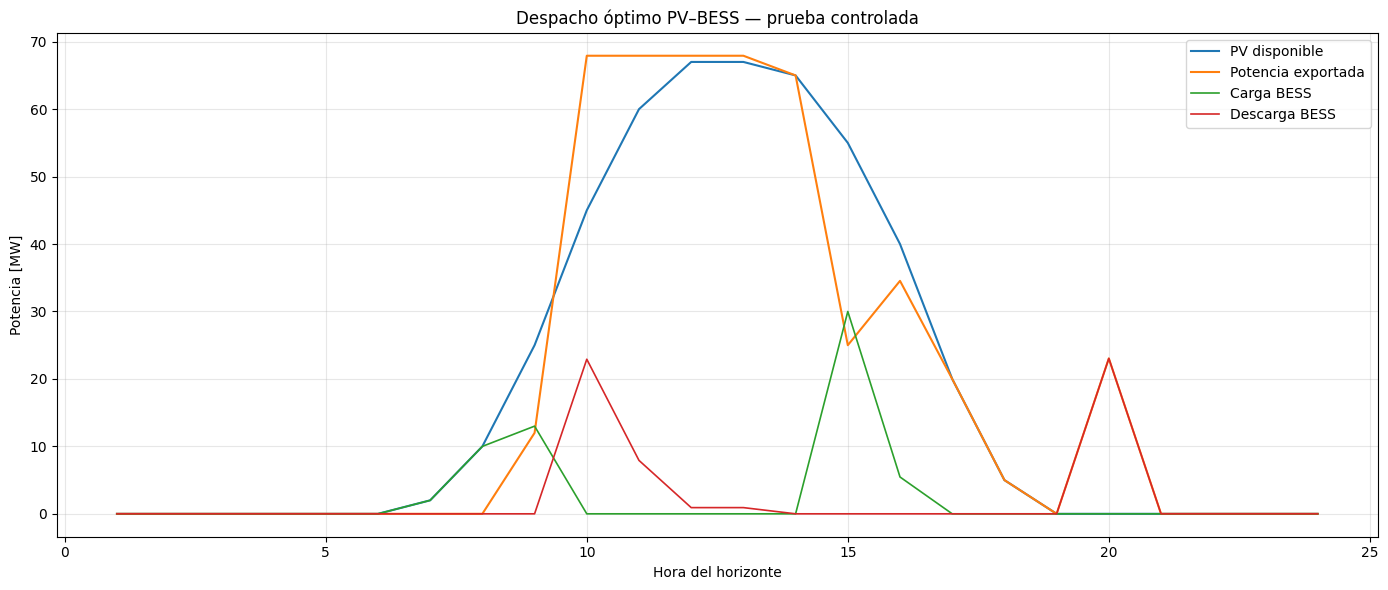

In [86]:
# ============================================================
# 23.4 VISUALIZACIÓN DEL DESPACHO
# ============================================================

fig, ax = plt.subplots(
    figsize=(14,6)
)


ax.plot(

    resultado_demo["h"],

    resultado_demo["pv_pred_MW"],

    label="PV disponible",

    linewidth=1.5

)


ax.plot(

    resultado_demo["h"],

    resultado_demo["export_MW"],

    label="Potencia exportada",

    linewidth=1.5

)


ax.plot(

    resultado_demo["h"],

    resultado_demo["charge_MW"],

    label="Carga BESS",

    linewidth=1.2

)


ax.plot(

    resultado_demo["h"],

    resultado_demo["discharge_MW"],

    label="Descarga BESS",

    linewidth=1.2

)


ax.set_xlabel(
    "Hora del horizonte"
)

ax.set_ylabel(
    "Potencia [MW]"
)

ax.set_title(
    "Despacho óptimo PV–BESS — prueba controlada"
)

ax.legend()

ax.grid(
    alpha=.3
)

plt.tight_layout()

plt.show()

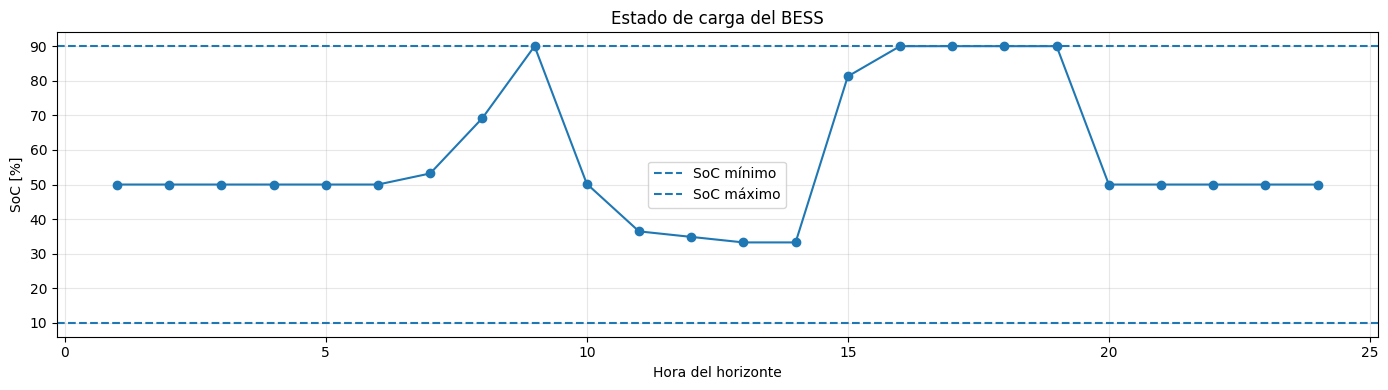

In [87]:
fig, ax = plt.subplots(
    figsize=(14,4)
)


ax.plot(

    resultado_demo["h"],

    resultado_demo["SoC_pct"],

    marker="o"

)


ax.axhline(
    SOC_MIN * 100,
    linestyle="--",
    label="SoC mínimo"
)


ax.axhline(
    SOC_MAX * 100,
    linestyle="--",
    label="SoC máximo"
)


ax.set_xlabel(
    "Hora del horizonte"
)

ax.set_ylabel(
    "SoC [%]"
)

ax.set_title(
    "Estado de carga del BESS"
)

ax.legend()

ax.grid(
    alpha=.3
)

plt.tight_layout()

plt.show()

In [88]:

# ============================================================
# 24.1 ORIGEN COMÚN — PRECIO + SOLAR
# ============================================================

# Orígenes disponibles del módulo solar en TEST
origenes_solar_disponibles = pd.DatetimeIndex(
    origenes_test_solar
)

# Fechas disponibles en el módulo de precio
origenes_precio_disponibles = pd.DatetimeIndex(
    test.index
)

# Intersección
origenes_comunes = (
    origenes_solar_disponibles
    .intersection(
        origenes_precio_disponibles
    )
)

# Necesitamos 24 horas futuras completas
limite_final = min(
    data.index.max(),
    datos_procesados.index.max()
) - pd.Timedelta(hours=24)

origenes_comunes = origenes_comunes[
    origenes_comunes <= limite_final
]


if len(origenes_comunes) == 0:
    raise RuntimeError(
        "No se encontraron fechas comunes entre "
        "los módulos de precio y solar."
    )


# Elegimos una fecha relativamente reciente,
# pero no necesariamente la última.
ORIGEN_EMS = origenes_comunes[
    int(
        len(origenes_comunes) * 0.70
    )
]


print("=" * 70)
print("ORIGEN DE PRONÓSTICO DEL EMS")
print("=" * 70)

print(
    "Origen:",
    ORIGEN_EMS
)

print(
    "Horizonte:",
    ORIGEN_EMS + pd.Timedelta(hours=1),
    "->",
    ORIGEN_EMS + pd.Timedelta(hours=24)
)

print(
    "Orígenes comunes disponibles:",
    len(origenes_comunes)
)


ORIGEN DE PRONÓSTICO DEL EMS
Origen: 2025-11-28 21:00:00
Horizonte: 2025-11-28 22:00:00 -> 2025-11-29 21:00:00
Orígenes comunes disponibles: 2553


In [89]:
# ============================================================
# 24.2 PRONÓSTICO DE PRECIO — 24 HORAS
# GRADIENT BOOSTING FINAL
# ============================================================

def construir_features_precio_hora(
    fecha_objetivo,
    historial_precio,
    datos_contexto,
    features_modelo
):

    fecha_objetivo = pd.Timestamp(
        fecha_objetivo
    )

    row = {}


    # ========================================================
    # PRECIO — LAGS
    # ========================================================

    for lag in PRICE_LAGS:

        nombre = f"precio_lag_{lag}"

        fecha_lag = (
            fecha_objetivo
            -
            pd.Timedelta(
                hours=lag
            )
        )

        if fecha_lag not in historial_precio.index:

            raise ValueError(
                f"Falta histórico para {nombre}: "
                f"{fecha_lag}"
            )

        row[nombre] = float(
            historial_precio.loc[
                fecha_lag
            ]
        )


    # ========================================================
    # ROLLING FEATURES
    #
    # En entrenamiento se construyeron sobre shift(1),
    # por lo tanto terminan en t-1.
    # ========================================================

    for ventana in ROLLING_WINDOWS:

        fechas_roll = pd.date_range(

            end=
                fecha_objetivo
                -
                pd.Timedelta(hours=1),

            periods=ventana,

            freq="h"

        )

        serie_roll = (
            historial_precio
            .reindex(
                fechas_roll
            )
        )

        if serie_roll.isna().any():

            raise ValueError(
                f"Histórico incompleto para "
                f"rolling {ventana} h."
            )


        row[
            f"precio_mean_{ventana}"
        ] = float(
            serie_roll.mean()
        )

        row[
            f"precio_std_{ventana}"
        ] = float(
            serie_roll.std()
        )

        row[
            f"precio_min_{ventana}"
        ] = float(
            serie_roll.min()
        )

        row[
            f"precio_max_{ventana}"
        ] = float(
            serie_roll.max()
        )


    # ========================================================
    # DIFERENCIAS
    # ========================================================

    row["precio_diff_1"] = (

        historial_precio.loc[
            fecha_objetivo
            -
            pd.Timedelta(hours=1)
        ]

        -

        historial_precio.loc[
            fecha_objetivo
            -
            pd.Timedelta(hours=2)
        ]

    )


    row["precio_diff_24"] = (

        historial_precio.loc[
            fecha_objetivo
            -
            pd.Timedelta(hours=1)
        ]

        -

        historial_precio.loc[
            fecha_objetivo
            -
            pd.Timedelta(hours=25)
        ]

    )


    # ========================================================
    # CALENDARIO
    # ========================================================

    hora = fecha_objetivo.hour

    dow = fecha_objetivo.dayofweek

    mes = fecha_objetivo.month

    doy = fecha_objetivo.dayofyear


    row["hora_sin"] = np.sin(
        2 * np.pi * hora / 24
    )

    row["hora_cos"] = np.cos(
        2 * np.pi * hora / 24
    )


    row["dow_sin"] = np.sin(
        2 * np.pi * dow / 7
    )

    row["dow_cos"] = np.cos(
        2 * np.pi * dow / 7
    )


    row["mes_sin"] = np.sin(
        2 * np.pi * (mes - 1) / 12
    )

    row["mes_cos"] = np.cos(
        2 * np.pi * (mes - 1) / 12
    )


    row["doy_sin"] = np.sin(
        2 * np.pi * doy / 365.25
    )

    row["doy_cos"] = np.cos(
        2 * np.pi * doy / 365.25
    )


    row["es_fin_semana"] = int(
        dow >= 5
    )


    # ========================================================
    # VARIABLES EXÓGENAS REZAGADAS
    #
    # Ejemplo:
    # demanda_sin_lag_24
    # se toma realmente de t-24.
    #
    # Toda esa información está disponible al momento k
    # para un horizonte máximo de 24 h.
    # ========================================================

    for feature in features_exogenas:

        if "_lag_" not in feature:
            continue

        variable_base, lag_txt = (
            feature.rsplit(
                "_lag_",
                1
            )
        )

        lag = int(
            lag_txt
        )

        fecha_exog = (
            fecha_objetivo
            -
            pd.Timedelta(
                hours=lag
            )
        )


        if (
            variable_base
            not in datos_contexto.columns
        ):

            raise ValueError(
                f"No existe {variable_base} "
                "en data."
            )


        if fecha_exog not in datos_contexto.index:

            raise ValueError(
                f"Fecha faltante para {feature}: "
                f"{fecha_exog}"
            )


        valor = datos_contexto.loc[
            fecha_exog,
            variable_base
        ]


        if pd.isna(valor):

            raise ValueError(
                f"NaN en {feature} "
                f"para {fecha_exog}"
            )


        row[feature] = float(
            valor
        )


    # ========================================================
    # CONSTRUIR DATAFRAME EXACTAMENTE EN EL ORDEN DEL MODELO
    # ========================================================

    faltantes = [
        f
        for f in features_modelo
        if f not in row
    ]


    if faltantes:

        raise ValueError(
            "No fue posible construir features: "
            + str(faltantes)
        )


    X = pd.DataFrame(
        [row],
        index=[fecha_objetivo]
    )


    X = X[
        features_modelo
    ]


    return X

In [90]:
# ============================================================
# 24.3 FORECAST RECURSIVO GBM
# ============================================================

def pronosticar_precio_24h(
    origen
):

    origen = pd.Timestamp(
        origen
    )


    # --------------------------------------------------------
    # HISTÓRICO REAL DISPONIBLE HASTA k
    # --------------------------------------------------------

    historial = (

        data.loc[
            :origen,
            "precio_bolsa"
        ]

        .dropna()

        .copy()

    )


    predicciones = []

    fechas = []


    # --------------------------------------------------------
    # PRONÓSTICO RECURSIVO
    # --------------------------------------------------------

    for h in range(
        1,
        25
    ):

        fecha = (
            origen
            +
            pd.Timedelta(
                hours=h
            )
        )


        X_h = construir_features_precio_hora(

            fecha_objetivo=fecha,

            historial_precio=historial,

            datos_contexto=data,

            features_modelo=features_multi

        )


        precio_pred = float(

            gbm_final.predict(
                X_h
            )[0]

        )


        # Precio no negativo para esta implementación
        precio_pred = max(
            precio_pred,
            0
        )


        # Añadir predicción al historial
        # para construir h+2, h+3, etc.
        historial.loc[
            fecha
        ] = precio_pred


        predicciones.append(
            precio_pred
        )

        fechas.append(
            fecha
        )


    return pd.Series(

        predicciones,

        index=pd.DatetimeIndex(
            fechas
        ),

        name="precio_pred_COP_kWh"

    )

In [91]:
# ============================================================
# 24.3 FORECAST RECURSIVO GBM
# ============================================================

def pronosticar_precio_24h(
    origen
):

    origen = pd.Timestamp(
        origen
    )


    # --------------------------------------------------------
    # HISTÓRICO REAL DISPONIBLE HASTA k
    # --------------------------------------------------------

    historial = (

        data.loc[
            :origen,
            "precio_bolsa"
        ]

        .dropna()

        .copy()

    )


    predicciones = []

    fechas = []


    # --------------------------------------------------------
    # PRONÓSTICO RECURSIVO
    # --------------------------------------------------------

    for h in range(
        1,
        25
    ):

        fecha = (
            origen
            +
            pd.Timedelta(
                hours=h
            )
        )


        X_h = construir_features_precio_hora(

            fecha_objetivo=fecha,

            historial_precio=historial,

            datos_contexto=data,

            features_modelo=features_multi

        )


        precio_pred = float(

            gbm_final.predict(
                X_h
            )[0]

        )


        # Precio no negativo para esta implementación
        precio_pred = max(
            precio_pred,
            0
        )


        # Añadir predicción al historial
        # para construir h+2, h+3, etc.
        historial.loc[
            fecha
        ] = precio_pred


        predicciones.append(
            precio_pred
        )

        fechas.append(
            fecha
        )


    return pd.Series(

        predicciones,

        index=pd.DatetimeIndex(
            fechas
        ),

        name="precio_pred_COP_kWh"

    )

In [92]:
precio_pred_24h = pronosticar_precio_24h(
    ORIGEN_EMS
)


display(
    precio_pred_24h.to_frame().round(2)
)

,precio_pred_COP_kWh
2025-11-28 22:00:00,250.36
2025-11-28 23:00:00,247.98
2025-11-29 00:00:00,254.95
2025-11-29 01:00:00,254.62
2025-11-29 02:00:00,254.62
2025-11-29 03:00:00,255.03
2025-11-29 04:00:00,257.79
2025-11-29 05:00:00,264.29
2025-11-29 06:00:00,261.78
2025-11-29 07:00:00,261.78


In [93]:
# ============================================================
# 24.4 CNN-LSTM — PRONÓSTICO SOLAR 24 H
# ============================================================

posiciones = np.where(
    origenes_test_solar
    ==
    ORIGEN_EMS
)[0]


if len(posiciones) == 0:

    raise RuntimeError(
        "El origen seleccionado no existe "
        "en X_test_solar."
    )


idx_solar_ems = posiciones[0]


X_ems_solar = (
    X_test_solar[
        idx_solar_ems:
        idx_solar_ems + 1
    ]
)


ghi_pred_scaled = modelo_solar.predict(

    X_ems_solar,

    verbose=0

)


ghi_pred_24h = (

    scaler_y_solar

    .inverse_transform(

        ghi_pred_scaled.reshape(
            -1,
            1
        )

    )

    .reshape(-1)

)


# Restricción física
ghi_pred_24h = np.maximum(
    ghi_pred_24h,
    0
)


print(
    "GHI pronosticado:"
)

print(
    np.round(
        ghi_pred_24h,
        1
    )
)

GHI pronosticado:
[  0.    7.3  18.9   0.    0.   23.8  17.9   0.   76.3 217.  379.  510.4
 602.6 669.2 657.2 606.  460.5 328.2 147.6  57.9   7.    6.9  14.2   5. ]


In [94]:
# ============================================================
# 24.5 GHI -> POTENCIA PV
# ============================================================

pv_pred_24h = pronostico_pv_24h(

    ORIGEN_EMS,

    ghi_pred_24h

)


display(
    pv_pred_24h.round(2)
)

,GHI_pred_Wm2,Temp_pred_C,PV_pred_MW
2025-11-28 22:00:00,0.000000,26.04,0.00
2025-11-28 23:00:00,7.290000,25.55,1.18
2025-11-29 00:00:00,18.910000,25.23,3.05
2025-11-29 01:00:00,0.000000,24.95,0.00
2025-11-29 02:00:00,0.000000,24.71,0.00
2025-11-29 03:00:00,23.770000,24.42,3.84
2025-11-29 04:00:00,17.920000,24.16,2.90
2025-11-29 05:00:00,0.000000,24.06,0.00
2025-11-29 06:00:00,76.300003,24.30,12.26
2025-11-29 07:00:00,217.009995,25.57,34.08


In [95]:
# ============================================================
# 24.6 ENTRADAS REALES DEL OPTIMIZADOR
# ============================================================

inputs_ems_24h = pd.DataFrame({

    "precio_pred_COP_kWh":
        precio_pred_24h.values,

    "GHI_pred_Wm2":
        pv_pred_24h[
            "GHI_pred_Wm2"
        ].values,

    "PV_pred_MW":
        pv_pred_24h[
            "PV_pred_MW"
        ].values

},
index=precio_pred_24h.index)


inputs_ems_24h.index.name = (
    "datetime"
)


print("=" * 70)
print("ENTRADAS DEL EMS — HORIZONTE 24 H")
print("=" * 70)


display(
    inputs_ems_24h.round(2)
)

ENTRADAS DEL EMS — HORIZONTE 24 H


,precio_pred_COP_kWh,GHI_pred_Wm2,PV_pred_MW
datetime,,,
2025-11-28 22:00:00,250.36,0.000000,0.00
2025-11-28 23:00:00,247.98,7.290000,1.18
2025-11-29 00:00:00,254.95,18.910000,3.05
2025-11-29 01:00:00,254.62,0.000000,0.00
2025-11-29 02:00:00,254.62,0.000000,0.00
2025-11-29 03:00:00,255.03,23.770000,3.84
2025-11-29 04:00:00,257.79,17.920000,2.90
2025-11-29 05:00:00,264.29,0.000000,0.00
2025-11-29 06:00:00,261.78,76.300003,12.26


In [96]:
# ============================================================
# 24.7 OPTIMIZACIÓN CON PRONÓSTICOS DE IA
# ============================================================

soc_inicial_ems_mwh = (

    SOC_INITIAL

    *

    BESS_ENERGY_MWH

)


resultado_ems_24h, solver_ems, modelo_ems = (
    optimizar_pv_bess_24h(

        precios_cop_kwh=
            inputs_ems_24h[
                "precio_pred_COP_kWh"
            ].values,

        pv_pred_mw=
            inputs_ems_24h[
                "PV_pred_MW"
            ].values,

        soc_inicial_mwh=
            soc_inicial_ems_mwh,

        costo_degradacion_cop_mwh=
            0.0,

        mantener_soc_final=
            True

    )
)


resultado_ems_24h.index = (
    inputs_ems_24h.index
)


display(
    resultado_ems_24h.round(3)
)

,h,precio_COP_kWh,pv_pred_MW,pv_grid_MW,charge_MW,discharge_MW,curtail_MW,energy_MWh,SoC_pct,export_MW,revenue_COP
datetime,,,,,,,,,,,
2025-11-28 22:00:00,1,250.365,0.000,0.000,0.000,0.000,0.0,30.000,50.000,0.000,0.000000e+00
2025-11-28 23:00:00,2,247.977,1.176,0.000,1.176,0.000,0.0,31.129,51.882,0.000,0.000000e+00
2025-11-29 00:00:00,3,254.950,3.049,0.000,3.049,0.000,0.0,34.056,56.761,0.000,0.000000e+00
2025-11-29 01:00:00,4,254.620,0.000,0.000,0.000,0.000,0.0,34.056,56.761,0.000,0.000000e+00
2025-11-29 02:00:00,5,254.620,0.000,0.000,0.000,0.000,0.0,34.056,56.761,0.000,0.000000e+00
2025-11-29 03:00:00,6,255.029,3.843,0.000,3.843,0.000,0.0,37.746,62.909,0.000,0.000000e+00
2025-11-29 04:00:00,7,257.793,2.902,0.000,2.902,0.000,0.0,40.532,67.553,0.000,0.000000e+00
2025-11-29 05:00:00,8,264.290,0.000,0.000,0.000,0.000,0.0,40.532,67.553,0.000,0.000000e+00
2025-11-29 06:00:00,9,261.777,12.263,12.263,0.000,0.000,0.0,40.532,67.553,12.263,3.210295e+06


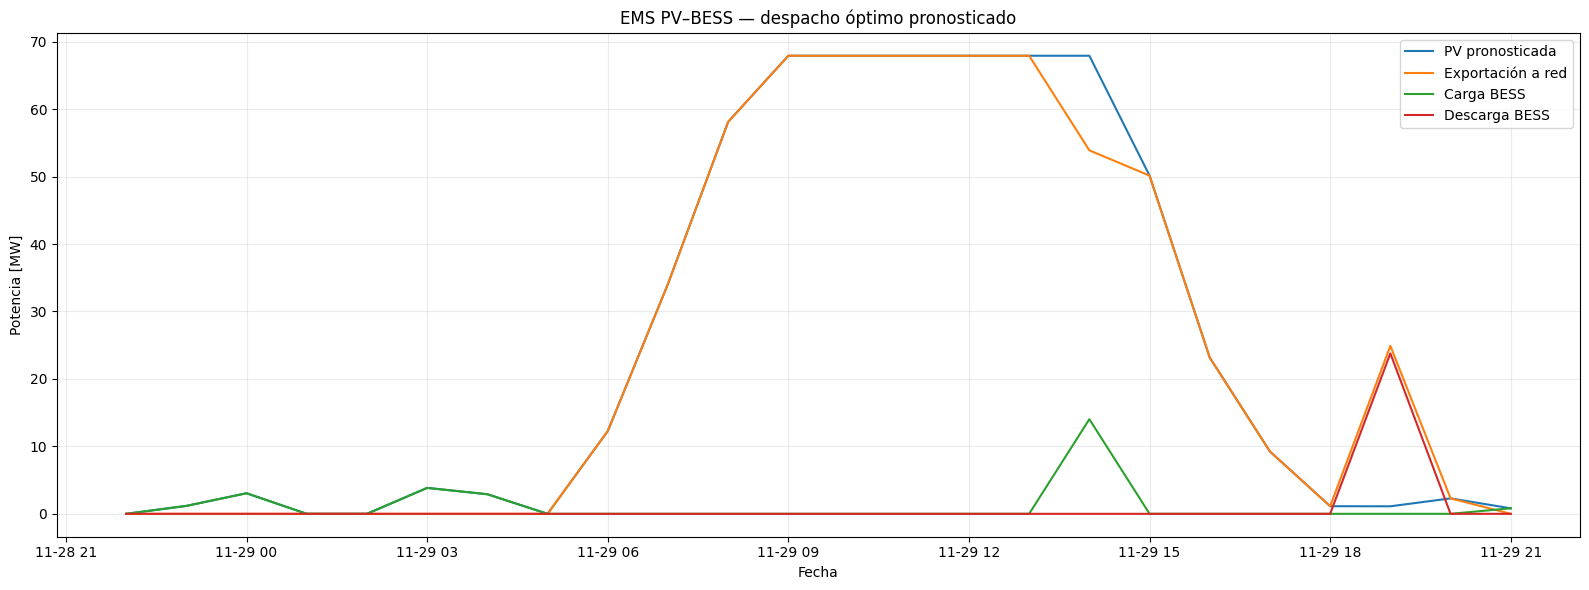

In [97]:
# ============================================================
# 24.8 DESPACHO DEL EMS — HORIZONTE REAL
# ============================================================

fig, ax = plt.subplots(
    figsize=(16,6)
)


ax.plot(

    resultado_ems_24h.index,

    resultado_ems_24h[
        "pv_pred_MW"
    ],

    label="PV pronosticada",

    linewidth=1.5

)


ax.plot(

    resultado_ems_24h.index,

    resultado_ems_24h[
        "export_MW"
    ],

    label="Exportación a red",

    linewidth=1.5

)


ax.plot(

    resultado_ems_24h.index,

    resultado_ems_24h[
        "charge_MW"
    ],

    label="Carga BESS"

)


ax.plot(

    resultado_ems_24h.index,

    resultado_ems_24h[
        "discharge_MW"
    ],

    label="Descarga BESS"

)


ax.set_title(
    "EMS PV–BESS — despacho óptimo pronosticado"
)

ax.set_ylabel(
    "Potencia [MW]"
)

ax.set_xlabel(
    "Fecha"
)

ax.legend()

ax.grid(
    alpha=.25
)

plt.tight_layout()

plt.show()

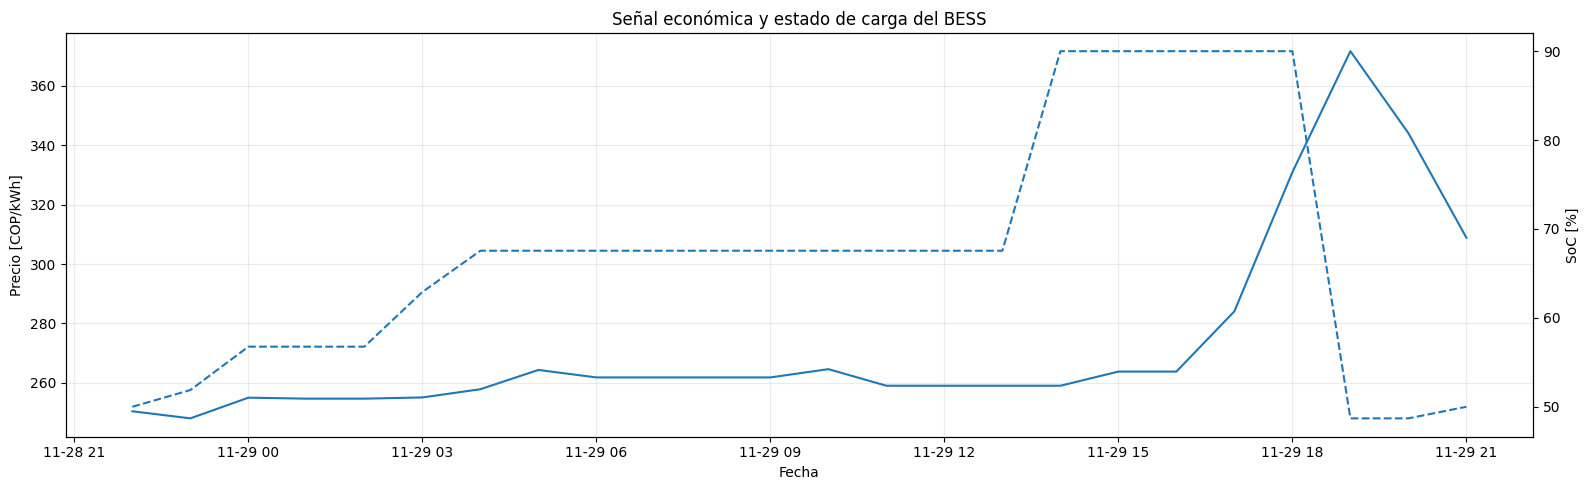

In [98]:
# ============================================================
# 24.9 PRECIO Y SOC
# ============================================================

fig, ax1 = plt.subplots(
    figsize=(16,5)
)


ax1.plot(

    resultado_ems_24h.index,

    resultado_ems_24h[
        "precio_COP_kWh"
    ],

    label="Precio pronosticado",

    linewidth=1.5

)


ax1.set_ylabel(
    "Precio [COP/kWh]"
)

ax1.set_xlabel(
    "Fecha"
)


ax2 = ax1.twinx()


ax2.plot(

    resultado_ems_24h.index,

    resultado_ems_24h[
        "SoC_pct"
    ],

    label="SoC",

    linestyle="--",

    linewidth=1.5

)


ax2.set_ylabel(
    "SoC [%]"
)


ax1.set_title(
    "Señal económica y estado de carga del BESS"
)


ax1.grid(
    alpha=.25
)


plt.tight_layout()

plt.show()

In [99]:
# ============================================================
# 24.10 PRONÓSTICO VS REALIDAD
# ============================================================

fechas_horizonte = (
    inputs_ems_24h.index
)


precio_real_24h = (

    df[
        "precio_bolsa"
    ]

    .reindex(
        fechas_horizonte
    )

)


pv_real_24h = (

    datos_procesados[
        "pv_real_modelado_MW"
    ]

    .reindex(
        fechas_horizonte
    )

)


comparacion_forecast = pd.DataFrame({

    "precio_real":
        precio_real_24h,

    "precio_pred":
        inputs_ems_24h[
            "precio_pred_COP_kWh"
        ],

    "PV_real_modelado_MW":
        pv_real_24h,

    "PV_pred_MW":
        inputs_ems_24h[
            "PV_pred_MW"
        ]

})


display(
    comparacion_forecast.round(2)
)

,precio_real,precio_pred,PV_real_modelado_MW,PV_pred_MW
datetime,,,,
2025-11-28 22:00:00,248.87,250.36,0.00,0.00
2025-11-28 23:00:00,248.87,247.98,0.00,1.18
2025-11-29 00:00:00,238.86,254.95,0.00,3.05
2025-11-29 01:00:00,238.86,254.62,0.00,0.00
2025-11-29 02:00:00,238.86,254.62,0.00,0.00
2025-11-29 03:00:00,238.86,255.03,0.00,3.84
2025-11-29 04:00:00,238.86,257.79,0.00,2.90
2025-11-29 05:00:00,238.86,264.29,0.00,0.00
2025-11-29 06:00:00,238.86,261.78,5.02,12.26


In [100]:
# ============================================================
# 24.11 ERROR DEL HORIZONTE EMS
# ============================================================

mask_precio = (
    comparacion_forecast[
        "precio_real"
    ].notna()
)


rmse_precio_horizonte = np.sqrt(

    mean_squared_error(

        comparacion_forecast.loc[
            mask_precio,
            "precio_real"
        ],

        comparacion_forecast.loc[
            mask_precio,
            "precio_pred"
        ]

    )

)


mask_pv = (
    comparacion_forecast[
        "PV_real_modelado_MW"
    ].notna()
)


rmse_pv_horizonte = np.sqrt(

    mean_squared_error(

        comparacion_forecast.loc[
            mask_pv,
            "PV_real_modelado_MW"
        ],

        comparacion_forecast.loc[
            mask_pv,
            "PV_pred_MW"
        ]

    )

)


print("=" * 70)
print("ERROR DEL HORIZONTE DE OPERACIÓN")
print("=" * 70)

print(
    f"RMSE precio: "
    f"{rmse_precio_horizonte:.2f} COP/kWh"
)

print(
    f"RMSE PV: "
    f"{rmse_pv_horizonte:.2f} MW"
)

ERROR DEL HORIZONTE DE OPERACIÓN
RMSE precio: 30.66 COP/kWh
RMSE PV: 8.18 MW


In [101]:
# ============================================================
# 24.12 ARBITRAJE ESPERADO — 24 H
# ============================================================

# ------------------------------------------------------------
# SIN BESS
# ------------------------------------------------------------

export_sin_bess = np.minimum(

    inputs_ems_24h[
        "PV_pred_MW"
    ].values,

    EXPORT_LIMIT_MW

)


ingreso_sin_bess = np.sum(

    inputs_ems_24h[
        "precio_pred_COP_kWh"
    ].values

    *

    export_sin_bess

    *

    1000

    *

    DELTA_T

)


# ------------------------------------------------------------
# CON EMS PV-BESS
# ------------------------------------------------------------

ingreso_con_bess = (

    resultado_ems_24h[
        "revenue_COP"
    ]
    .sum()

)


beneficio_arbitraje = (

    ingreso_con_bess

    -

    ingreso_sin_bess

)


mejora_pct = (

    beneficio_arbitraje

    /

    ingreso_sin_bess

    *

    100

    if ingreso_sin_bess > 0

    else np.nan

)


print("=" * 70)
print("RESULTADO ECONÓMICO ESPERADO — 24 H")
print("=" * 70)


print(
    f"Ingreso PV sin BESS: "
    f"${ingreso_sin_bess:,.0f} COP"
)


print(
    f"Ingreso PV-BESS optimizado: "
    f"${ingreso_con_bess:,.0f} COP"
)


print(
    f"Valor adicional por arbitraje: "
    f"${beneficio_arbitraje:,.0f} COP"
)


print(
    f"Incremento relativo: "
    f"{mejora_pct:.2f}%"
)

RESULTADO ECONÓMICO ESPERADO — 24 H
Ingreso PV sin BESS: $160,034,174 COP
Ingreso PV-BESS optimizado: $162,195,711 COP
Valor adicional por arbitraje: $2,161,537 COP
Incremento relativo: 1.35%


25.  **Rolling horizon del EMS **

In [102]:
# ============================================================
# 25.1 PRONÓSTICO SOLAR PARA UN ORIGEN CUALQUIERA
# ============================================================

def pronosticar_pv_24h_desde_origen(
    origen
):

    origen = pd.Timestamp(
        origen
    )

    posiciones = np.where(
        origenes_test_solar
        ==
        origen
    )[0]


    if len(posiciones) == 0:

        raise ValueError(
            f"No existe secuencia solar "
            f"para el origen {origen}"
        )


    idx = posiciones[0]


    X_origen = (
        X_test_solar[
            idx:idx+1
        ]
    )


    # --------------------------------------------------------
    # CNN-LSTM
    # --------------------------------------------------------

    ghi_scaled = modelo_solar.predict(

        X_origen,

        verbose=0

    )


    # --------------------------------------------------------
    # DESNORMALIZAR
    # --------------------------------------------------------

    ghi_pred = (

        scaler_y_solar

        .inverse_transform(

            ghi_scaled.reshape(
                -1,
                1
            )

        )

        .reshape(-1)

    )


    # Restricción física
    ghi_pred = np.maximum(
        ghi_pred,
        0
    )


    # --------------------------------------------------------
    # GHI -> POTENCIA PV
    # --------------------------------------------------------

    pv_pred = pronostico_pv_24h(

        origen,

        ghi_pred

    )


    return pv_pred

In [103]:
# ============================================================
# 25.2 EJECUCIÓN DE LA PRIMERA DECISIÓN
# BAJO CONDICIONES REALIZADAS
# ============================================================

def ejecutar_decision_real(
    decision,
    pv_real_mw,
    energia_actual_mwh
):

    pv_real_mw = max(
        float(pv_real_mw),
        0.0
    )


    carga_plan = max(
        float(
            decision["charge_MW"]
        ),
        0.0
    )


    descarga_plan = max(
        float(
            decision["discharge_MW"]
        ),
        0.0
    )


    E_MIN = (
        SOC_MIN
        *
        BESS_ENERGY_MWH
    )

    E_MAX = (
        SOC_MAX
        *
        BESS_ENERGY_MWH
    )


    # ========================================================
    # CASO 1 — CARGA
    # ========================================================

    if carga_plan > 1e-6:

        # Máxima carga posible por energía disponible
        carga_por_soc = (

            (
                E_MAX
                -
                energia_actual_mwh
            )

            /

            (
                ETA_C
                *
                DELTA_T
            )

        )


        carga_real = min(

            carga_plan,

            pv_real_mw,

            BESS_POWER_MW,

            max(
                carga_por_soc,
                0.0
            )

        )


        descarga_real = 0.0


        pv_restante = (

            pv_real_mw

            -

            carga_real

        )


        pv_grid_real = min(

            pv_restante,

            EXPORT_LIMIT_MW

        )


        curtail_real = max(

            pv_restante

            -

            pv_grid_real,

            0.0

        )


    # ========================================================
    # CASO 2 — DESCARGA
    # ========================================================

    elif descarga_plan > 1e-6:

        carga_real = 0.0


        # Prioridad de exportación al PV realizado
        pv_grid_real = min(

            pv_real_mw,

            EXPORT_LIMIT_MW

        )


        curtail_real = max(

            pv_real_mw

            -

            pv_grid_real,

            0.0

        )


        # Energía disponible para descargar
        descarga_por_soc = (

            (
                energia_actual_mwh
                -
                E_MIN
            )

            *
            ETA_D

            /

            DELTA_T

        )


        # Espacio disponible en el punto de conexión
        headroom_red = max(

            EXPORT_LIMIT_MW

            -

            pv_grid_real,

            0.0

        )


        descarga_real = min(

            descarga_plan,

            BESS_POWER_MW,

            max(
                descarga_por_soc,
                0.0
            ),

            headroom_red

        )


    # ========================================================
    # CASO 3 — STANDBY
    # ========================================================

    else:

        carga_real = 0.0

        descarga_real = 0.0


        pv_grid_real = min(

            pv_real_mw,

            EXPORT_LIMIT_MW

        )


        curtail_real = max(

            pv_real_mw

            -

            pv_grid_real,

            0.0

        )


    # ========================================================
    # ACTUALIZACIÓN REAL DE ENERGÍA
    # ========================================================

    energia_nueva = (

        energia_actual_mwh

        +

        ETA_C
        *
        carga_real
        *
        DELTA_T

        -

        descarga_real
        *
        DELTA_T
        /
        ETA_D

    )


    energia_nueva = np.clip(

        energia_nueva,

        E_MIN,

        E_MAX

    )


    export_real = (

        pv_grid_real

        +

        descarga_real

    )


    return {

        "charge_real_MW":
            carga_real,

        "discharge_real_MW":
            descarga_real,

        "pv_grid_real_MW":
            pv_grid_real,

        "curtail_real_MW":
            curtail_real,

        "export_real_MW":
            export_real,

        "energy_next_MWh":
            energia_nueva,

        "SoC_next_pct":
            (
                energia_nueva
                /
                BESS_ENERGY_MWH
                *
                100
            )

    }

In [104]:
# ============================================================
# 25.3 CONFIGURACIÓN ROLLING HORIZON
# ============================================================

ROLLING_DAYS = (
    7
    if MODO_RAPIDO
    else 30
)


ROLLING_HOURS = (
    ROLLING_DAYS
    *
    24
)


# ------------------------------------------------------------
# ORIGEN INICIAL
# ------------------------------------------------------------

ORIGEN_ROLLING = ORIGEN_EMS


print("=" * 70)
print("ROLLING HORIZON")
print("=" * 70)


print(
    "Origen:",
    ORIGEN_ROLLING
)

print(
    "Duración:",
    ROLLING_DAYS,
    "días"
)

print(
    "Iteraciones máximas:",
    ROLLING_HOURS
)

ROLLING HORIZON
Origen: 2025-11-28 21:00:00
Duración: 7 días
Iteraciones máximas: 168


In [105]:
# ============================================================
# 25.4 EMS — ROLLING HORIZON
# ============================================================

def ejecutar_rolling_horizon(
    origen_inicial,
    numero_horas
):

    origen_actual = pd.Timestamp(
        origen_inicial
    )


    energia_actual = (

        SOC_INITIAL

        *

        BESS_ENERGY_MWH

    )


    registros = []


    print(
        "Iniciando Rolling Horizon..."
    )


    for paso in range(
        numero_horas
    ):

        # ====================================================
        # HORA QUE REALMENTE SE VA A EJECUTAR
        # ====================================================

        hora_ejecucion = (

            origen_actual

            +

            pd.Timedelta(
                hours=1
            )

        )


        # ----------------------------------------------------
        # VERIFICAR INFORMACIÓN REAL DISPONIBLE
        # ----------------------------------------------------

        if (
            hora_ejecucion
            not in df.index
        ):

            print(
                "Fin: no existe precio real para",
                hora_ejecucion
            )

            break


        if (
            hora_ejecucion
            not in datos_procesados.index
        ):

            print(
                "Fin: no existe PV realizado para",
                hora_ejecucion
            )

            break


        if (
            pd.isna(
                df.loc[
                    hora_ejecucion,
                    "precio_bolsa"
                ]
            )
        ):

            print(
                "Fin: precio real NaN."
            )

            break


        if (
            pd.isna(
                datos_procesados.loc[
                    hora_ejecucion,
                    "pv_real_modelado_MW"
                ]
            )
        ):

            print(
                "Fin: PV realizado NaN."
            )

            break


        # ====================================================
        # 1. PRONÓSTICO DE PRECIO 24 H
        # ====================================================

        try:

            precio_pred = (
                pronosticar_precio_24h(
                    origen_actual
                )
            )

        except Exception as e:

            print(
                "Error pronóstico precio:",
                origen_actual
            )

            print(e)

            break


        # ====================================================
        # 2. PRONÓSTICO SOLAR 24 H
        # ====================================================

        try:

            pv_forecast = (
                pronosticar_pv_24h_desde_origen(
                    origen_actual
                )
            )

        except Exception as e:

            print(
                "Error pronóstico solar:",
                origen_actual
            )

            print(e)

            break


        # ====================================================
        # 3. OPTIMIZACIÓN MILP 24 H
        # ====================================================

        resultado_opt, _, _ = (
            optimizar_pv_bess_24h(

                precios_cop_kwh=
                    precio_pred.values,

                pv_pred_mw=
                    pv_forecast[
                        "PV_pred_MW"
                    ].values,

                soc_inicial_mwh=
                    energia_actual,

                costo_degradacion_cop_mwh=
                    0.0,

                mantener_soc_final=
                    True

            )
        )


        # ====================================================
        # 4. EJECUTAR SOLO PRIMERA DECISIÓN
        # ====================================================

        decision = (
            resultado_opt.iloc[0]
        )


        # ====================================================
        # 5. OBSERVAR VALORES REALIZADOS
        # ====================================================

        precio_real = float(

            df.loc[
                hora_ejecucion,
                "precio_bolsa"
            ]

        )


        pv_real = float(

            datos_procesados.loc[
                hora_ejecucion,
                "pv_real_modelado_MW"
            ]

        )


        # ====================================================
        # 6. APLICAR DECISIÓN A CONDICIONES REALES
        # ====================================================

        ejecucion = (
            ejecutar_decision_real(

                decision,

                pv_real,

                energia_actual

            )
        )


        # ====================================================
        # 7. INGRESO REAL EMS
        # ====================================================

        ingreso_ems_real = (

            precio_real

            *

            ejecucion[
                "export_real_MW"
            ]

            *

            1000

            *

            DELTA_T

        )


        # ====================================================
        # 8. BASELINE — PV SIN BESS
        # ====================================================

        export_sin_bess = min(

            pv_real,

            EXPORT_LIMIT_MW

        )


        ingreso_sin_bess = (

            precio_real

            *

            export_sin_bess

            *

            1000

            *

            DELTA_T

        )


        # ====================================================
        # 9. REGISTRAR
        # ====================================================

        registros.append({

            "datetime":
                hora_ejecucion,

            "origen_forecast":
                origen_actual,

            # Pronósticos primera hora
            "precio_pred":
                float(
                    precio_pred.iloc[0]
                ),

            "precio_real":
                precio_real,

            "PV_pred_MW":
                float(
                    pv_forecast[
                        "PV_pred_MW"
                    ].iloc[0]
                ),

            "PV_real_MW":
                pv_real,

            # Orden planificada
            "charge_plan_MW":
                float(
                    decision[
                        "charge_MW"
                    ]
                ),

            "discharge_plan_MW":
                float(
                    decision[
                        "discharge_MW"
                    ]
                ),

            # Orden ejecutada
            "charge_real_MW":
                ejecucion[
                    "charge_real_MW"
                ],

            "discharge_real_MW":
                ejecucion[
                    "discharge_real_MW"
                ],

            "export_real_MW":
                ejecucion[
                    "export_real_MW"
                ],

            "curtail_real_MW":
                ejecucion[
                    "curtail_real_MW"
                ],

            # Estado
            "energy_MWh":
                ejecucion[
                    "energy_next_MWh"
                ],

            "SoC_pct":
                ejecucion[
                    "SoC_next_pct"
                ],

            # Economía
            "ingreso_PV_sin_BESS_COP":
                ingreso_sin_bess,

            "ingreso_EMS_COP":
                ingreso_ems_real,

            "beneficio_incremental_COP":
                (
                    ingreso_ems_real
                    -
                    ingreso_sin_bess
                )

        })


        # ====================================================
        # 10. ACTUALIZAR ESTADO
        # ====================================================

        energia_actual = (
            ejecucion[
                "energy_next_MWh"
            ]
        )


        origen_actual = (
            hora_ejecucion
        )


        # Progreso
        if (
            (paso + 1) % 24
            ==
            0
        ):

            print(

                f"{paso+1} h completadas | "

                f"SoC = "
                f"{ejecucion['SoC_next_pct']:.1f}%"

            )


    resultados = pd.DataFrame(
        registros
    )


    if len(resultados) > 0:

        resultados = (
            resultados
            .set_index(
                "datetime"
            )
        )


    return resultados

In [106]:
# ============================================================
# 25.5 EJECUCIÓN DEL ROLLING HORIZON
# ============================================================

rolling_resultados = ejecutar_rolling_horizon(

    origen_inicial=
        ORIGEN_ROLLING,

    numero_horas=
        ROLLING_HOURS

)


print("\n")
print("=" * 70)
print("ROLLING HORIZON FINALIZADO")
print("=" * 70)


print(
    "Horas simuladas:",
    len(
        rolling_resultados
    )
)


if len(
    rolling_resultados
) > 0:

    print(
        "Inicio:",
        rolling_resultados.index.min()
    )

    print(
        "Fin:",
        rolling_resultados.index.max()
    )


display(
    rolling_resultados.head(24).round(3)
)

Iniciando Rolling Horizon...
24 h completadas | SoC = 37.9%
48 h completadas | SoC = 10.0%
72 h completadas | SoC = 10.0%
96 h completadas | SoC = 10.0%
120 h completadas | SoC = 10.0%
144 h completadas | SoC = 10.0%
168 h completadas | SoC = 10.0%


ROLLING HORIZON FINALIZADO
Horas simuladas: 168
Inicio: 2025-11-28 22:00:00
Fin: 2025-12-05 21:00:00


,origen_forecast,precio_pred,precio_real,PV_pred_MW,PV_real_MW,charge_plan_MW,discharge_plan_MW,charge_real_MW,discharge_real_MW,export_real_MW,curtail_real_MW,energy_MWh,SoC_pct,ingreso_PV_sin_BESS_COP,ingreso_EMS_COP,beneficio_incremental_COP
datetime,,,,,,,,,,,,,,,,
2025-11-28 22:00:00,2025-11-28 21:00:00,250.365,248.867,0.000,0.000,0.000,0.0,0.0,0.0,0.000,0.0,30.00,50.000,0.000000e+00,0.000000e+00,0.0
2025-11-28 23:00:00,2025-11-28 22:00:00,240.993,248.867,0.000,0.000,0.000,0.0,0.0,0.0,0.000,0.0,30.00,50.000,0.000000e+00,0.000000e+00,0.0
2025-11-29 00:00:00,2025-11-28 23:00:00,254.950,238.862,0.000,0.000,0.000,0.0,0.0,0.0,0.000,0.0,30.00,50.000,0.000000e+00,0.000000e+00,0.0
2025-11-29 01:00:00,2025-11-29 00:00:00,223.903,238.862,1.290,0.000,1.290,0.0,0.0,0.0,0.000,0.0,30.00,50.000,0.000000e+00,0.000000e+00,0.0
2025-11-29 02:00:00,2025-11-29 01:00:00,223.903,238.862,3.098,0.000,3.098,0.0,0.0,0.0,0.000,0.0,30.00,50.000,0.000000e+00,0.000000e+00,0.0
2025-11-29 03:00:00,2025-11-29 02:00:00,224.312,238.862,5.171,0.000,5.171,0.0,0.0,0.0,0.000,0.0,30.00,50.000,0.000000e+00,0.000000e+00,0.0
2025-11-29 04:00:00,2025-11-29 03:00:00,227.076,238.862,3.577,0.000,0.000,0.0,0.0,0.0,0.000,0.0,30.00,50.000,0.000000e+00,0.000000e+00,0.0
2025-11-29 05:00:00,2025-11-29 04:00:00,233.573,238.862,4.569,0.000,0.000,0.0,0.0,0.0,0.000,0.0,30.00,50.000,0.000000e+00,0.000000e+00,0.0
2025-11-29 06:00:00,2025-11-29 05:00:00,228.798,238.862,18.028,5.016,0.000,0.0,0.0,0.0,5.016,0.0,30.00,50.000,1.198172e+06,1.198172e+06,0.0


In [107]:
# ============================================================
# 25.6 RESULTADO ECONÓMICO REAL
# ============================================================

ingreso_base_total = (

    rolling_resultados[
        "ingreso_PV_sin_BESS_COP"
    ]
    .sum()

)


ingreso_ems_total = (

    rolling_resultados[
        "ingreso_EMS_COP"
    ]
    .sum()

)


beneficio_total = (

    ingreso_ems_total

    -

    ingreso_base_total

)


mejora_total_pct = (

    beneficio_total

    /

    ingreso_base_total

    *

    100

    if ingreso_base_total > 0

    else np.nan

)


print("=" * 70)
print("RESULTADOS ROLLING HORIZON")
print("=" * 70)


print(
    f"Periodo simulado: "
    f"{len(rolling_resultados)/24:.1f} días"
)


print(
    f"\nIngreso PV sin BESS: "
    f"${ingreso_base_total:,.0f} COP"
)


print(
    f"Ingreso EMS PV-BESS: "
    f"${ingreso_ems_total:,.0f} COP"
)


print(
    f"Beneficio incremental: "
    f"${beneficio_total:,.0f} COP"
)


print(
    f"Incremento relativo: "
    f"{mejora_total_pct:.2f}%"
)

RESULTADOS ROLLING HORIZON
Periodo simulado: 7.0 días

Ingreso PV sin BESS: $905,996,359 COP
Ingreso EMS PV-BESS: $933,499,589 COP
Beneficio incremental: $27,503,230 COP
Incremento relativo: 3.04%


In [108]:
# ============================================================
# 25.7 INDICADORES TÉCNICOS
# ============================================================

energia_cargada = (

    rolling_resultados[
        "charge_real_MW"
    ]
    .sum()

    *

    DELTA_T

)


energia_descargada = (

    rolling_resultados[
        "discharge_real_MW"
    ]
    .sum()

    *

    DELTA_T

)


energia_exportada = (

    rolling_resultados[
        "export_real_MW"
    ]
    .sum()

    *

    DELTA_T

)


curtailment_total = (

    rolling_resultados[
        "curtail_real_MW"
    ]
    .sum()

    *

    DELTA_T

)


# Ciclos equivalentes aproximados
ciclos_equivalentes = (

    energia_descargada

    /

    BESS_ENERGY_MWH

)


print("=" * 70)
print("INDICADORES TÉCNICOS DEL EMS")
print("=" * 70)


print(
    f"Energía cargada: "
    f"{energia_cargada:,.2f} MWh"
)


print(
    f"Energía descargada: "
    f"{energia_descargada:,.2f} MWh"
)


print(
    f"Energía exportada: "
    f"{energia_exportada:,.2f} MWh"
)


print(
    f"Curtailment: "
    f"{curtailment_total:,.2f} MWh"
)


print(
    f"Ciclos equivalentes: "
    f"{ciclos_equivalentes:.2f}"
)


print(
    f"SoC mínimo observado: "
    f"{rolling_resultados['SoC_pct'].min():.2f}%"
)


print(
    f"SoC máximo observado: "
    f"{rolling_resultados['SoC_pct'].max():.2f}%"
)

INDICADORES TÉCNICOS DEL EMS
Energía cargada: 307.55 MWh
Energía descargada: 306.48 MWh
Energía exportada: 3,748.83 MWh
Curtailment: 0.00 MWh
Ciclos equivalentes: 5.11
SoC mínimo observado: 10.00%
SoC máximo observado: 90.00%


In [109]:
# ============================================================
# 25.8 AGREGACIÓN DIARIA
# ============================================================

rolling_diario = pd.DataFrame({

    "Ingreso_sin_BESS_COP":

        rolling_resultados[
            "ingreso_PV_sin_BESS_COP"
        ]
        .resample(
            "D"
        )
        .sum(),

    "Ingreso_EMS_COP":

        rolling_resultados[
            "ingreso_EMS_COP"
        ]
        .resample(
            "D"
        )
        .sum(),

    "Beneficio_COP":

        rolling_resultados[
            "beneficio_incremental_COP"
        ]
        .resample(
            "D"
        )
        .sum(),

    "Carga_MWh":

        rolling_resultados[
            "charge_real_MW"
        ]
        .resample(
            "D"
        )
        .sum()
        *
        DELTA_T,

    "Descarga_MWh":

        rolling_resultados[
            "discharge_real_MW"
        ]
        .resample(
            "D"
        )
        .sum()
        *
        DELTA_T

})


rolling_diario[
    "Mejora_pct"
] = (

    rolling_diario[
        "Beneficio_COP"
    ]

    /

    rolling_diario[
        "Ingreso_sin_BESS_COP"
    ]

    *

    100

)


display(
    rolling_diario.round(2)
)

,Ingreso_sin_BESS_COP,Ingreso_EMS_COP,Beneficio_COP,Carga_MWh,Descarga_MWh,Mejora_pct
datetime,,,,,,
2025-11-28,0.000000e+00,0.000000e+00,0.00,0.00,0.00,NaN
2025-11-29,1.145906e+08,1.172549e+08,2664311.00,25.00,30.00,2.33
2025-11-30,1.281397e+08,1.340113e+08,5871595.92,32.55,46.08,4.58
2025-12-01,1.032514e+08,1.025566e+08,-694770.92,50.00,46.08,-0.67
2025-12-02,1.753346e+08,1.771216e+08,1787003.52,50.00,46.08,1.02
2025-12-03,1.400672e+08,1.454143e+08,5347130.31,50.00,46.08,3.82
2025-12-04,1.517542e+08,1.534414e+08,1687224.09,50.00,46.08,1.11
2025-12-05,9.285871e+07,1.036994e+08,10840736.12,50.00,46.08,11.67


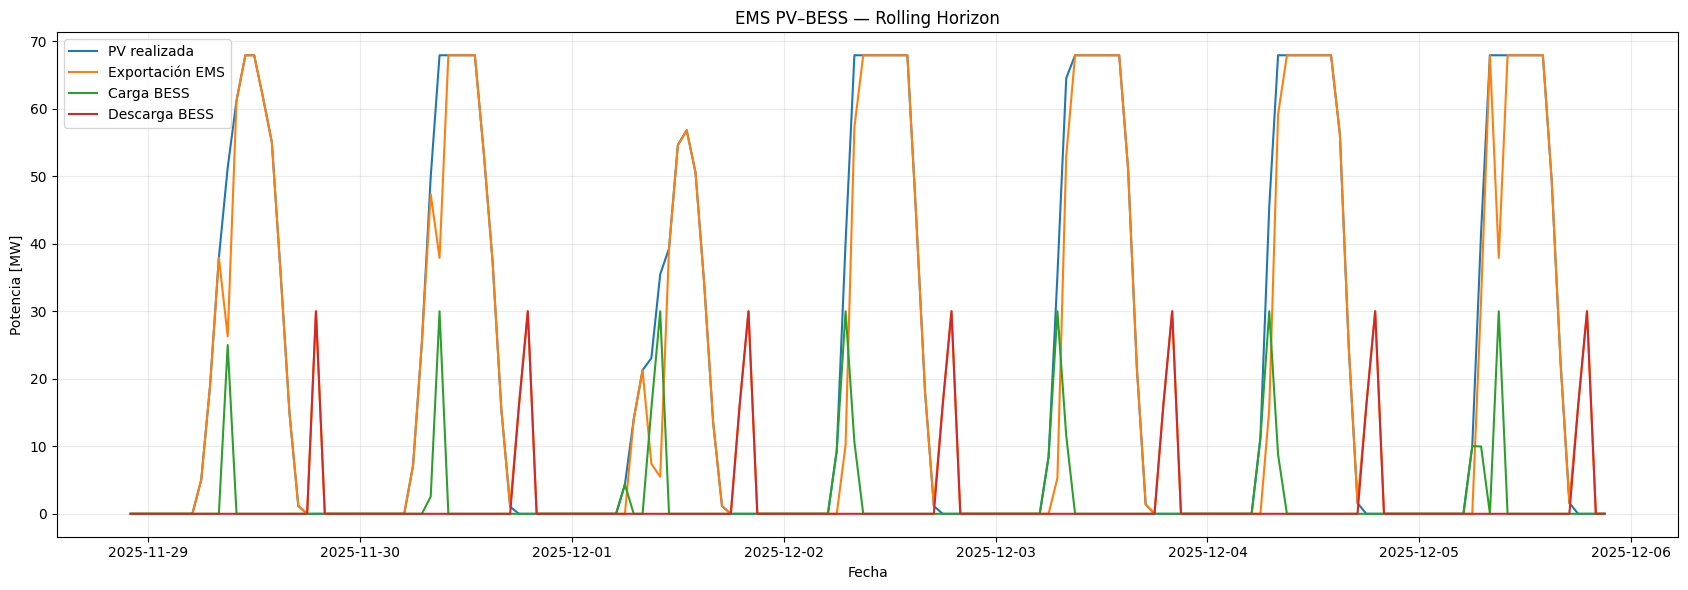

In [110]:
# ============================================================
# 25.9 OPERACIÓN REALIZADA DEL BESS
# ============================================================

fig, ax = plt.subplots(
    figsize=(17,6)
)


ax.plot(

    rolling_resultados.index,

    rolling_resultados[
        "PV_real_MW"
    ],

    label="PV realizada"

)


ax.plot(

    rolling_resultados.index,

    rolling_resultados[
        "export_real_MW"
    ],

    label="Exportación EMS"

)


ax.plot(

    rolling_resultados.index,

    rolling_resultados[
        "charge_real_MW"
    ],

    label="Carga BESS"

)


ax.plot(

    rolling_resultados.index,

    rolling_resultados[
        "discharge_real_MW"
    ],

    label="Descarga BESS"

)


ax.set_title(
    "EMS PV–BESS — Rolling Horizon"
)

ax.set_ylabel(
    "Potencia [MW]"
)

ax.set_xlabel(
    "Fecha"
)

ax.legend()

ax.grid(
    alpha=.25
)

plt.tight_layout()

plt.show()

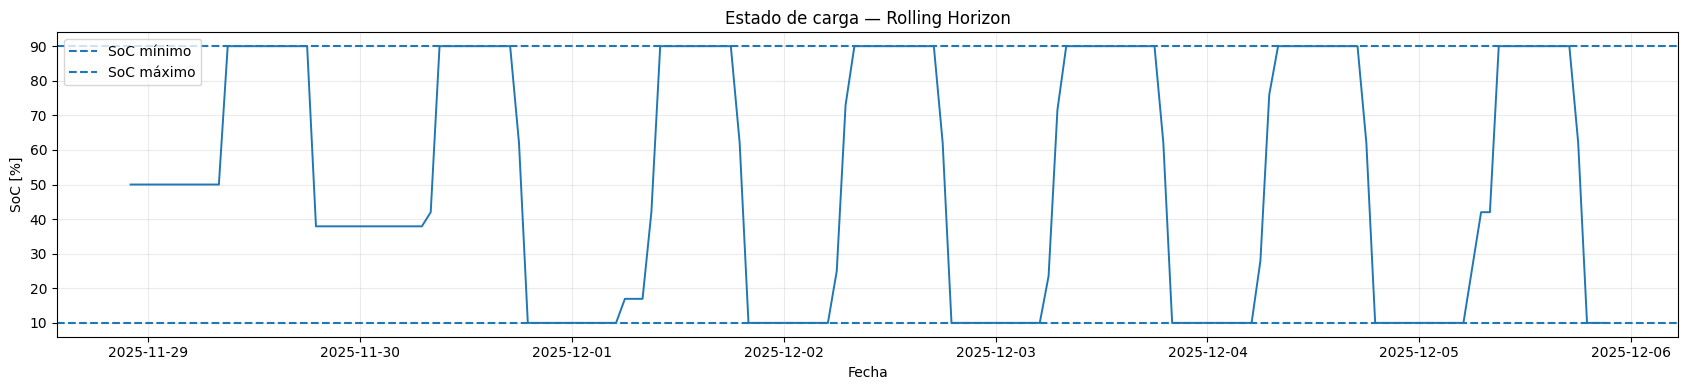

In [111]:
fig, ax = plt.subplots(
    figsize=(17,4)
)


ax.plot(

    rolling_resultados.index,

    rolling_resultados[
        "SoC_pct"
    ],

    linewidth=1.4

)


ax.axhline(
    SOC_MIN * 100,
    linestyle="--",
    label="SoC mínimo"
)


ax.axhline(
    SOC_MAX * 100,
    linestyle="--",
    label="SoC máximo"
)


ax.set_title(
    "Estado de carga — Rolling Horizon"
)

ax.set_ylabel(
    "SoC [%]"
)

ax.set_xlabel(
    "Fecha"
)

ax.legend()

ax.grid(
    alpha=.25
)

plt.tight_layout()

plt.show()

In [112]:
# ============================================================
# 27. EXPORTACIÓN DE FIGURAS PARA LA TESIS
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import zipfile

# ------------------------------------------------------------
# CARPETAS
# ------------------------------------------------------------

BASE_OUTPUT = Path(
    globals().get(
        "OUTPUT_DIR",
        "outputs_tesis_ems"
    )
)

FIG_DIR = (
    BASE_OUTPUT
    /
    "figuras_tesis"
)

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)


figuras_guardadas = []


def guardar_figura(
    fig,
    nombre
):

    ruta = (
        FIG_DIR
        /
        f"{nombre}.png"
    )

    fig.savefig(
        ruta,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    figuras_guardadas.append(
        ruta.name
    )


# ============================================================
# 1. COMPARACIÓN DE MODELOS DE PRECIO
# ============================================================

if "resultados_modelos" in globals():

    datos_plot = (
        resultados_modelos
        .set_index("Modelo")["RMSE"]
        .sort_values()
    )

    fig, ax = plt.subplots(
        figsize=(10,5)
    )

    datos_plot.plot(
        kind="barh",
        ax=ax
    )

    ax.set_title(
        "Comparación de modelos — RMSE en validación"
    )

    ax.set_xlabel(
        "RMSE [COP/kWh]"
    )

    ax.set_ylabel(
        "Modelo"
    )

    ax.grid(
        axis="x",
        alpha=0.3
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "01_comparacion_modelos_precio_RMSE"
    )


# ============================================================
# 2. PRECIO REAL VS PRONOSTICADO — TEST
# ============================================================

if all(
    x in globals()
    for x in [
        "test",
        "y_test",
        "pred_test_gbm"
    ]
):

    n = min(
        336,
        len(test)
    )

    fig, ax = plt.subplots(
        figsize=(16,6)
    )

    ax.plot(
        test.index[:n],
        y_test.iloc[:n],
        label="Precio real",
        linewidth=1.5
    )

    ax.plot(
        test.index[:n],
        pred_test_gbm[:n],
        label="Precio pronosticado — GBM",
        linewidth=1.3
    )

    ax.set_title(
        "Precio de Bolsa Nacional — Real vs Pronosticado"
    )

    ax.set_ylabel(
        "Precio [COP/kWh]"
    )

    ax.set_xlabel(
        "Fecha"
    )

    ax.legend()

    ax.grid(
        alpha=0.25
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "02_precio_real_vs_pronosticado"
    )


# ============================================================
# 3. RESIDUOS DEL MODELO DE PRECIO
# ============================================================

if all(
    x in globals()
    for x in [
        "test",
        "residuos_test"
    ]
):

    fig, ax = plt.subplots(
        figsize=(15,5)
    )

    ax.plot(
        test.index,
        residuos_test,
        linewidth=0.8
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        "Residuos del modelo Gradient Boosting — Test"
    )

    ax.set_ylabel(
        "Error [COP/kWh]"
    )

    ax.set_xlabel(
        "Fecha"
    )

    ax.grid(
        alpha=0.25
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "03_residuos_modelo_precio"
    )


# ============================================================
# 4. IMPORTANCIA DE VARIABLES — PRECIO
# ============================================================

if "importancias_gbm" in globals():

    fig, ax = plt.subplots(
        figsize=(11,8)
    )

    (
        importancias_gbm
        .head(20)
        .sort_values()
        .plot(
            kind="barh",
            ax=ax
        )
    )

    ax.set_title(
        "Gradient Boosting — Importancia de variables"
    )

    ax.set_xlabel(
        "Importancia relativa"
    )

    ax.set_ylabel(
        "Variable"
    )

    ax.grid(
        axis="x",
        alpha=0.25
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "04_importancia_variables_precio"
    )


# ============================================================
# 5. IRRADIANCIA SOLAR NASA POWER
# ============================================================

if "solar_semana" in globals():

    fig, ax = plt.subplots(
        figsize=(16,5)
    )

    ax.plot(
        solar_semana.index,
        solar_semana[
            "ALLSKY_SFC_SW_DWN"
        ],
        label="GHI NASA POWER",
        linewidth=1.2
    )

    if (
        "CLRSKY_SFC_SW_DWN"
        in solar_semana.columns
    ):

        ax.plot(
            solar_semana.index,
            solar_semana[
                "CLRSKY_SFC_SW_DWN"
            ],
            label="GHI cielo despejado",
            linewidth=1
        )

    ax.set_title(
        "Irradiancia solar — El Paso, Cesar"
    )

    ax.set_ylabel(
        "Irradiancia [W/m²]"
    )

    ax.set_xlabel(
        "Fecha"
    )

    ax.legend()

    ax.grid(
        alpha=0.25
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "05_irradiancia_solar_El_Paso"
    )


# ============================================================
# 6. ENTRENAMIENTO CNN-LSTM — LOSS
# ============================================================

if "historial" in globals():

    fig, ax = plt.subplots(
        figsize=(10,5)
    )

    ax.plot(
        historial.index + 1,
        historial["loss"],
        label="Train loss"
    )

    ax.plot(
        historial.index + 1,
        historial["val_loss"],
        label="Validation loss"
    )

    ax.set_title(
        "CNN-LSTM — Evolución de la función de pérdida"
    )

    ax.set_xlabel(
        "Época"
    )

    ax.set_ylabel(
        "MSE escalado"
    )

    ax.legend()

    ax.grid(
        alpha=0.3
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "06_CNN_LSTM_loss"
    )


# ============================================================
# 7. ENTRENAMIENTO CNN-LSTM — MAE
# ============================================================

if (
    "historial" in globals()
    and
    "mae" in historial.columns
):

    fig, ax = plt.subplots(
        figsize=(10,5)
    )

    ax.plot(
        historial.index + 1,
        historial["mae"],
        label="Train MAE"
    )

    ax.plot(
        historial.index + 1,
        historial["val_mae"],
        label="Validation MAE"
    )

    ax.set_title(
        "CNN-LSTM — MAE durante entrenamiento"
    )

    ax.set_xlabel(
        "Época"
    )

    ax.set_ylabel(
        "MAE escalado"
    )

    ax.legend()

    ax.grid(
        alpha=0.3
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "07_CNN_LSTM_MAE"
    )


# ============================================================
# 8. ERROR SOLAR SEGÚN HORIZONTE
# ============================================================

if "metricas_horizonte_solar" in globals():

    fig, ax = plt.subplots(
        figsize=(11,5)
    )

    ax.plot(
        metricas_horizonte_solar[
            "Horizonte"
        ],
        metricas_horizonte_solar[
            "RMSE"
        ],
        marker="o"
    )

    ax.set_title(
        "CNN-LSTM — RMSE según horizonte de pronóstico"
    )

    ax.set_xlabel(
        "Hora futura"
    )

    ax.set_ylabel(
        "RMSE [W/m²]"
    )

    ax.set_xticks(
        range(
            1,
            25
        )
    )

    ax.grid(
        alpha=0.3
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "08_RMSE_solar_por_horizonte"
    )


# ============================================================
# 9. EJEMPLO PRONÓSTICO GHI 24 H
# ============================================================

if all(
    x in globals()
    for x in [
        "fechas_ejemplo",
        "real_solar",
        "pred_solar",
        "ejemplo"
    ]
):

    fig, ax = plt.subplots(
        figsize=(12,5)
    )

    ax.plot(
        fechas_ejemplo,
        real_solar[ejemplo],
        marker="o",
        label="GHI real"
    )

    ax.plot(
        fechas_ejemplo,
        pred_solar[ejemplo],
        marker="o",
        label="CNN-LSTM"
    )

    ax.set_title(
        "Pronóstico GHI — Horizonte de 24 horas"
    )

    ax.set_ylabel(
        "GHI [W/m²]"
    )

    ax.set_xlabel(
        "Fecha"
    )

    ax.legend()

    ax.grid(
        alpha=0.3
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "09_pronostico_GHI_24h"
    )


# ============================================================
# 10. OPTIMIZADOR — PRUEBA CONTROLADA
# ============================================================

if "resultado_demo" in globals():

    fig, ax = plt.subplots(
        figsize=(14,6)
    )

    ax.plot(
        resultado_demo["h"],
        resultado_demo["pv_pred_MW"],
        label="PV disponible"
    )

    ax.plot(
        resultado_demo["h"],
        resultado_demo["export_MW"],
        label="Potencia exportada"
    )

    ax.plot(
        resultado_demo["h"],
        resultado_demo["charge_MW"],
        label="Carga BESS"
    )

    ax.plot(
        resultado_demo["h"],
        resultado_demo["discharge_MW"],
        label="Descarga BESS"
    )

    ax.set_title(
        "Despacho óptimo PV-BESS — Prueba controlada"
    )

    ax.set_xlabel(
        "Hora del horizonte"
    )

    ax.set_ylabel(
        "Potencia [MW]"
    )

    ax.legend()

    ax.grid(
        alpha=0.3
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "10_despacho_optimo_prueba_controlada"
    )


    # --------------------------------------------------------
    # SOC PRUEBA
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(14,4)
    )

    ax.plot(
        resultado_demo["h"],
        resultado_demo["SoC_pct"],
        marker="o"
    )

    ax.axhline(
        SOC_MIN * 100,
        linestyle="--",
        label="SoC mínimo"
    )

    ax.axhline(
        SOC_MAX * 100,
        linestyle="--",
        label="SoC máximo"
    )

    ax.set_title(
        "Estado de carga del BESS — Prueba controlada"
    )

    ax.set_xlabel(
        "Hora del horizonte"
    )

    ax.set_ylabel(
        "SoC [%]"
    )

    ax.legend()

    ax.grid(
        alpha=0.3
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "11_SOC_prueba_controlada"
    )


# ============================================================
# 11. EMS — HORIZONTE DE 24 H
# ============================================================

if "resultado_ems_24h" in globals():

    fig, ax = plt.subplots(
        figsize=(16,6)
    )

    ax.plot(
        resultado_ems_24h.index,
        resultado_ems_24h[
            "pv_pred_MW"
        ],
        label="PV pronosticada"
    )

    ax.plot(
        resultado_ems_24h.index,
        resultado_ems_24h[
            "export_MW"
        ],
        label="Exportación a red"
    )

    ax.plot(
        resultado_ems_24h.index,
        resultado_ems_24h[
            "charge_MW"
        ],
        label="Carga BESS"
    )

    ax.plot(
        resultado_ems_24h.index,
        resultado_ems_24h[
            "discharge_MW"
        ],
        label="Descarga BESS"
    )

    ax.set_title(
        "EMS PV-BESS — Despacho óptimo pronosticado"
    )

    ax.set_ylabel(
        "Potencia [MW]"
    )

    ax.set_xlabel(
        "Fecha"
    )

    ax.legend()

    ax.grid(
        alpha=0.25
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "12_EMS_despacho_24h"
    )


    # --------------------------------------------------------
    # PRECIO + SOC
    # --------------------------------------------------------

    fig, ax1 = plt.subplots(
        figsize=(16,5)
    )

    ax1.plot(
        resultado_ems_24h.index,
        resultado_ems_24h[
            "precio_COP_kWh"
        ],
        label="Precio pronosticado"
    )

    ax1.set_ylabel(
        "Precio [COP/kWh]"
    )

    ax1.set_xlabel(
        "Fecha"
    )


    ax2 = ax1.twinx()

    ax2.plot(
        resultado_ems_24h.index,
        resultado_ems_24h[
            "SoC_pct"
        ],
        linestyle="--",
        label="SoC"
    )

    ax2.set_ylabel(
        "SoC [%]"
    )

    ax1.set_title(
        "Señal económica y estado de carga del BESS"
    )

    ax1.grid(
        alpha=0.25
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "13_EMS_precio_SOC_24h"
    )


# ============================================================
# 12. ROLLING HORIZON
# ============================================================

if (
    "rolling_resultados" in globals()
    and
    len(rolling_resultados) > 0
):

    fig, ax = plt.subplots(
        figsize=(17,6)
    )

    ax.plot(
        rolling_resultados.index,
        rolling_resultados[
            "PV_real_MW"
        ],
        label="PV realizada"
    )

    ax.plot(
        rolling_resultados.index,
        rolling_resultados[
            "export_real_MW"
        ],
        label="Exportación EMS"
    )

    ax.plot(
        rolling_resultados.index,
        rolling_resultados[
            "charge_real_MW"
        ],
        label="Carga BESS"
    )

    ax.plot(
        rolling_resultados.index,
        rolling_resultados[
            "discharge_real_MW"
        ],
        label="Descarga BESS"
    )

    ax.set_title(
        "EMS PV-BESS — Rolling Horizon"
    )

    ax.set_ylabel(
        "Potencia [MW]"
    )

    ax.set_xlabel(
        "Fecha"
    )

    ax.legend()

    ax.grid(
        alpha=0.25
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "14_EMS_Rolling_Horizon"
    )


    # --------------------------------------------------------
    # SOC ROLLING
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(17,4)
    )

    ax.plot(
        rolling_resultados.index,
        rolling_resultados[
            "SoC_pct"
        ]
    )

    ax.axhline(
        SOC_MIN * 100,
        linestyle="--",
        label="SoC mínimo"
    )

    ax.axhline(
        SOC_MAX * 100,
        linestyle="--",
        label="SoC máximo"
    )

    ax.set_title(
        "Estado de carga — Rolling Horizon"
    )

    ax.set_ylabel(
        "SoC [%]"
    )

    ax.set_xlabel(
        "Fecha"
    )

    ax.legend()

    ax.grid(
        alpha=0.25
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "15_SOC_Rolling_Horizon"
    )


# ============================================================
# 13. BENEFICIO DIARIO
# ============================================================

if (
    "rolling_diario" in globals()
    and
    len(rolling_diario) > 0
):

    diario = (
        rolling_diario
        .copy()
    )

    diario = diario[
        diario[
            "Ingreso_sin_BESS_COP"
        ] > 0
    ]


    fig, ax = plt.subplots(
        figsize=(13,5)
    )

    ax.bar(
        diario.index,
        diario[
            "Beneficio_COP"
        ]
    )

    ax.axhline(
        0,
        linewidth=1
    )

    ax.set_title(
        "Beneficio incremental diario del EMS"
    )

    ax.set_ylabel(
        "Beneficio [COP/día]"
    )

    ax.set_xlabel(
        "Fecha"
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )

    fig.tight_layout()

    guardar_figura(
        fig,
        "16_beneficio_diario_EMS"
    )


# ============================================================
# CREAR ÍNDICE DE FIGURAS
# ============================================================

indice_path = (
    FIG_DIR
    /
    "indice_figuras.txt"
)

with open(
    indice_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "FIGURAS GENERADAS — TESIS EMS PV-BESS\n"
    )

    f.write(
        "=" * 60
        +
        "\n\n"
    )

    for archivo in figuras_guardadas:

        f.write(
            archivo
            +
            "\n"
        )


# ============================================================
# CREAR ZIP
# ============================================================

ZIP_PATH = (
    BASE_OUTPUT
    /
    "figuras_tesis_EMS.zip"
)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for archivo in FIG_DIR.glob("*"):

        if archivo.is_file():

            zipf.write(
                archivo,
                arcname=archivo.name
            )


# ============================================================
# RESUMEN
# ============================================================

print("=" * 70)
print("EXPORTACIÓN DE FIGURAS FINALIZADA")
print("=" * 70)

print(
    f"\nFiguras guardadas: "
    f"{len(figuras_guardadas)}"
)

print(
    "\nCarpeta:"
)

print(
    FIG_DIR.resolve()
)

print(
    "\nArchivo ZIP:"
)

print(
    ZIP_PATH.resolve()
)

print(
    "\nArchivos:"
)

for archivo in figuras_guardadas:

    print(
        " -",
        archivo
    )

EXPORTACIÓN DE FIGURAS FINALIZADA

Figuras guardadas: 16

Carpeta:
/content/outputs_tesis_ems/figuras_tesis

Archivo ZIP:
/content/outputs_tesis_ems/figuras_tesis_EMS.zip

Archivos:
 - 01_comparacion_modelos_precio_RMSE.png
 - 02_precio_real_vs_pronosticado.png
 - 03_residuos_modelo_precio.png
 - 04_importancia_variables_precio.png
 - 05_irradiancia_solar_El_Paso.png
 - 06_CNN_LSTM_loss.png
 - 07_CNN_LSTM_MAE.png
 - 08_RMSE_solar_por_horizonte.png
 - 09_pronostico_GHI_24h.png
 - 10_despacho_optimo_prueba_controlada.png
 - 11_SOC_prueba_controlada.png
 - 12_EMS_despacho_24h.png
 - 13_EMS_precio_SOC_24h.png
 - 14_EMS_Rolling_Horizon.png
 - 15_SOC_Rolling_Horizon.png
 - 16_beneficio_diario_EMS.png
